# Data Project: What Determines a Song's Success on the Billboard Hot 100? (Group C)

[![Green-Black-and-White-Modern-Music-Charts-Presentation.png](https://i.postimg.cc/Qdt6grb1/Green-Black-and-White-Modern-Music-Charts-Presentation.png)](https://github.com/Isabelle333/billboard-musicbrainz-extract$0)



**Research question:** What determines the success of a song reaching the Billboard Hot 100 charts?

**Scope:** all weekly Billboard Hot 100 charts with chart dates from 2000-01-01 to 2025-12-27 (1,357 weekly charts).

**Data sources:**
1. Billboard Hot 100 weekly charts, obtained from the public archive `utdata/rwd-billboard-data` (Sections 1 and 3).
2. MusicBrainz: release dates, genres, artist information (later section).
3. Kaggle "Spotify Top Hit Playlist 2010–2022" (later section).

This notebook is our complete workflow: collection, cleaning, storage and analysis, in that order. Every decision is followed by its justification.

### About this study

**Research question.** What determines whether a song reaches the Billboard Hot 100?

**What we mean by success.** A song is successful if it appears on the Billboard Hot 100 at least once, i.e. it *reaches the chart*. This is a yes/no outcome. How high a song climbs, how long it stays, or whether it reaches No. 1 are **not** our measure of success; chart positions are used only to describe the data and to check its quality.
*Why this definition:* it is objective (one clear threshold), it matches our question, and it means the same thing in every year, whereas "how successful" a charting song is depends on Billboard's changing chart rules.

**What this implies for our data.** Billboard chart data contain only songs that reached the chart, so on their own they cannot show what distinguishes these songs from songs that never charted. Answering our question therefore requires a comparison group of songs released in the same period that did not chart (planned from MusicBrainz, later in this notebook). The role of the Billboard data is to identify *which* songs reached the chart and *when* they first entered it.

**Factors we plan to examine.**
- Genre.
- Artist popularity, e.g. whether the artist had already reached the chart before (measurable from the chart history itself).
- Timing: the time between a song's release and its first appearance on the chart.

**Hypothesis.** Most songs that reach the Hot 100 do so soon after release; beyond a certain time after release, a song becomes much less likely to ever enter the chart. We will examine whether the distribution of time from release to first chart entry shows such a threshold.

**Scope.**
- *Chart:* the Billboard Hot 100 only, Billboard's main all-genre singles chart. Other Billboard charts are specific to a genre or format and would change what "reaching the chart" means.
- *Period:* charts dated 2000-01-01 to 2025-12-27 (26 complete years, 1,357 weekly charts).
- *Unit of analysis:* a song, identified by its title and performer credit (refined during cleaning).

**Workflow.** Collection → raw-data quality assessment → cleaning → additional sources and matching → storage → analysis → communication (report and presentation). Each step is justified in this notebook.

**Data sources.**
1. Billboard Hot 100 weekly charts, from the public archive `utdata/rwd-billboard-data` (Sections 1 and 3).
2. MusicBrainz: release dates, genres, artist information (later section).
3. Kaggle "Spotify Top Hit Playlist 2010–2022" (later section).

**Caveats known from the start.**
- Songs already on the chart on 2000-01-01 first entered before our period, so their entry is not observed.
- Songs released in late 2025 may enter the chart only in 2026, after our period ends.
- Billboard's chart rules changed over 2000–2025 (e.g. the inclusion of streaming), so years are not perfectly comparable.

## Contents

0. Overview and how to reproduce
1. Choice of Billboard data source: legal and ethical considerations
2. Setup
3. Collection: acquiring the Billboard Hot 100 archive
4. Raw-data quality assessment
5. Cleaning
6. Storage
7. Descriptive analysis of Billboard Data
8. Collection, QA, Cleaning and Storage of MusicBrainz
9. Research: When do songs reach the chart?
10. Bonus. Comparison Group that never charted
11. What distinguished the songs that charted?
12. Conclusion

Because this work is Work In Progress, we are not ready to present results yet. However, you can still go to section 7 on Billboard Charts data and section 9 on enriched database (Billboard and MusicBrainz combined). You can also enjoy the report in section 11. However the conclusions and insights will be ready only during the presentation in class

## 1. Choice of Billboard data source: legal and ethical considerations

### 1.1 Our original plan: collecting charts with billboard.py

We originally planned to collect every weekly Hot 100 chart ourselves with the open-source Python library **billboard.py** (github.com/guoguo12/billboard-charts).

Although the library describes itself as a "Python API", it is not an API in the sense of a data service offered by Billboard: **Billboard provides no public API for chart data.** The library downloads the chart web pages from billboard.com and extracts the values from their HTML code. It is therefore a **web scraper** that offers a convenient Python interface.

In 2026 Billboard changed the layout of its chart pages (adding a "WEEKS AT NO. 1" column), which broke the library's parser (GitHub issue #101). A group member wrote a local patch to make it work again.

### 1.2 Why we stopped: Billboard.com's Terms of Use and actions we took

Billboard.com's Terms of Use are published by **Penske Media Corporation (PMC)** (version last updated 21 August 2026). The clauses relevant to us:

| Clause | What it says (summary) | Why it matters to us |
|---|---|---|
| §9 | Users shall not engage in "spidering, 'screen scraping,' 'database scraping'", or use robots or other automated data-gathering tools | billboard.py does exactly this |
| §1 | PMC claims ownership of the site's content, data, compilation and database rights | the chart data itself is claimed by PMC |
| §3 | Users get a limited, personal, non-commercial licence to view the site | scraping is outside this licence |
| §4 | No reproduction, redistribution or derivative works | constrains what we may publish |
| §9 | No use of content to train or ground AI/ML models "or other algorithms" | relevant to how we analyse the data (see 1.7) |

A non-commercial or educational purpose is **not** an exception to §9.

After a group member had patched billboard.py and tested it, we reviewed these terms, and confirmed that billboard.py, being a parser of billboard.com pages, is the kind of automatic extraction §9 prohibits. We therefore:
- **stopped** using billboard.py and rebuilt our chart data from a public archive (Section 3), so that our pipeline is reproducible from an accessible source;

Therefore, we decided to ask for permission of to PMC / Billboard directly

On 29/10/26 we wrote to PMC/Billboard's licensing contact (research@billboard.com & licensing@pmc.com), with our instructor in copy. We explained that this is a non-commercial university course project, stated the data we need (weekly Hot 100 chart positions, 2000–2025: chart date, rank, song title, artist, last-week position, peak position, weeks on chart), how we will use it (statistical analysis for coursework), and that we will not redistribute it.

The same day we were phoned by a billboard representative, Alex Vitoulis, the Director Charts Production Manager & Data Production.
He explained the data was publicly available, but only with a billboard subscription, billed annually at $191.88.

**Our choice:** we continue with the public archive described below, documented as such.

### 1.3 Alternatives we considered

| Option | What it is | Decision and reason |
|---|---|---|
| Scrape with patched billboard.py | We run the scraper ourselves | **Rejected.** Directly prohibited by §9; also fragile, since it breaks whenever Billboard changes its page layout |
| Scrape with `billboard-charts` (PyPI) | A different scraper library | **Rejected.** Same §9 problem |
| Wait for PMC's permission | No data until they answer | **Rejected as the only route.** They may never answer, and our deadlines (03.11, 27.11) would pass |
| **`utdata/rwd-billboard-data`** | Public archive of every Hot 100 chart since 1958, one CSV file, updated weekly | **Chosen.** Reasons below |
| `mhollingshead/billboard-hot-100` | Public archive, one JSON file per week, updated daily | **Not chosen as main source.** Same legal situation (also built by scraping); documentation and licence not checked in the same depth; possible independent cross-check later |
| ListenBrainz | Open listening-history data | **Not chosen.** It measures what ListenBrainz users listen to, not Billboard chart success, so it would change our research question; its users are also not representative of the general public |

Why `utdata/rwd-billboard-data`:
- Recommended by our instructor as an acceptable public archive.
- **Transparent:** its scraping and combining scripts are public, its sources are named, and its known errors are listed on its documentation site.
- **Maintained** by a university journalism programme (University of Texas at Austin) for teaching, and updated automatically every week.
- **Simple and verifiable:** the whole history is one CSV file, so we can pin and verify a single file (Section 3).
- **Licensed:** the repository carries an MIT licence (this covers the repository's files as distributed by UT; it cannot grant rights over Billboard's data, see 1.7).

### 1.4 Where the data comes from: the provenance chain

1. **Billboard** compiles the weekly Hot 100 (based on sales, streaming and radio airplay) and publishes it on billboard.com.
2. **The archive's maintainer**, Christian McDonald (GitHub: `critmcdonald`) of UT Data, University of Texas at Austin, collects it:
   - **2022 onwards:** an R script (`action_scrape_charts.R`) scrapes the current chart from billboard.com. It runs automatically on GitHub Actions (Tuesday to Friday) and saves one CSV per chart week in `data-scraped/hot-100/`.
   - **Before 2022:** combined from three third-party sources: a Kaggle dataset (charts to November 2021, with at least 13 missing records), a data.world dataset (to June 2021) used to fill gaps, and gap data collected with the Data Miner Chrome plugin and stored in a Google Sheet. These were merged in `notebooks/02-hot100-archive` and saved as `previous_archive.csv`.
   - The script `action_combine_charts.R` stacks all of these into `data-out/hot-100-current.csv`.
3. **We** download that file at a fixed version (commit `f5801b0`, 13 October 2026) and verify it with a SHA-256 fingerprint (Section 3).

The repository also contains `hot100_assignment.csv`. It holds the same rows with deliberately messy headers and date formats, created for UT's own data-cleaning exercise. We do not use it: it adds nothing and would only create artificial cleaning work, which the project brief tells us to avoid.

### 1.5 Why we consider our use acceptable

1. **We do not access or scrape billboard.com ourselves.**
2. **The data is already publicly available.** The same chart history is republished in several open archives. This does not by itself make our use lawful, but our use does not make the data any more available than it already is.
3. **Minimal use.** We use only the fields we need (positions, titles, artists) for the period we need (2000–2025). We use no images, editorial content, audio or lyrics.
4. **Transparency.** We disclose the full provenance (1.5), asked PMC for permission (1.3), and kept our instructor informed.
5. **No redistribution.** We do not publish the chart data. Our code downloads it from the original public source at run time, and we link to that source instead of sharing copies.


### 1.6 Dataset Challenges

Expected limitations, to be checked with data in Section 4:

- **Mixed origins.** Pre-2022 rows come from three third-party datasets; 2022 onwards from UT's scraper. Formatting (e.g. how featured artists are written) may change at the boundary.
- **Known errors.** The maintainer documents missing records in the Kaggle source and duplicate entries. Even though they occur in 1961 and 1970, outside our period, we cannot assume our period is error-free.
- **Methodology changes.** Billboard changed how the Hot 100 is calculated between 2000 and 2025 (e.g. adding streaming), so years are not perfectly comparable and this influences our insights.
- **Corrections.** Billboard occasionally corrects charts. Our fixed snapshot reflects what the maintainer captured as of 13 October 2026.
- **Name inconsistencies.** The same artist or song may be written differently across weeks or sources. This matters when matching to MusicBrainz.
- **Unusable column.** `wks_at_no1` was only added recently and is almost entirely empty.
- **Missing `last_week` by design.** It is empty for new entries and re-entries.
- **Chart date ≠ listening week.** `chart_week` is Billboard's official chart date, which falls after the week in which sales and streams were counted. This matters for our "time from release to chart" hypothesis.
- **Single maintainer.** The archive could change or disappear. This is addressed by pinning and verification (Section 3).

### 1.10 Licences of our other sources (to complete)

We apply the same check to our other sources:
- **MusicBrainz:** obtained from the official full export `20261017-002244` published by the MetaBrainz Foundation. Core data (recordings, artists, releases) is **CC0** (public domain); genres are derived from user tags, published under **CC BY-NC-SA 3.0** (attribution, non-commercial, share-alike). Our extract is therefore published with attribution, for non-commercial educational use, under the same licence.

## 2. Setup

### 2.1 Libraries

We use only Python’s standard library plus pandas, requests, numpy and matplotlib, all pre-installed on Colab, so no installation step is needed. Library versions are printed and later saved in the provenance record, because results can depend on them.

In [ ]:
# --- Standard library: built into Python, nothing to install ---------------
import hashlib                              # computes SHA-256 fingerprints of files
import io                                   # lets pandas read data held in memory as if it were a file
import json                                 # saves the provenance record in JSON format
import platform                             # records the operating system the notebook ran on
import sys                                  # gives the Python version
import time                                 # used to pause between download retries
from datetime import datetime, timezone     # timestamps in UTC
from pathlib import Path                    # builds file paths that work on any operating system

# --- Third-party libraries: pre-installed on Google Colab ------------------
import pandas as pd                         # tables (DataFrames)
import requests                             # downloads files from the web over HTTPS
import matplotlib                           # version recording
import matplotlib.pyplot as plt             # charts
import numpy as np                          # numerical helpers

# --- Colab helper for downloading files to your own computer --------------
# google.colab only exists inside Colab. try/except lets the notebook also run
# in a normal Jupyter environment without crashing.
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Print versions so they are visible in the notebook output.
print(f"Python   : {sys.version.split()[0]}")
print(f"pandas   : {pd.__version__}")
print(f"requests : {requests.__version__}")
print(f"In Colab : {IN_COLAB}")
print(f"numpy    : {np.__version__}")
print(f"matplotlib: {matplotlib.__version__}")

Python   : 3.13.16
pandas   : 2.2.3
requests : 2.32.4
In Colab : True
numpy    : 2.1.3
matplotlib: 3.10.0


### 2.2 Configuration

All fixed settings are defined here, in capital letters (the Python convention for values that should not change while the notebook runs).

- **Pinned source.** We download the archive file as it was in one specific commit (snapshot) of the repository, not the latest version. The file is updated every week, so downloading "the latest" would give different data on different days. A commit's content can never change, so this link always returns the same file.
- **Expected fingerprint.** `EXPECTED_SHA256` is the SHA-256 fingerprint of that exact file, calculated when we chose the snapshot on 2026-10-14. Section 3.2 compares every download against it.
- **Study window.** Charts dated 2000-01-01 (the first Saturday chart of 2000) to 2025-12-27 (the last chart dated in 2025). We define years by Billboard's official chart date, because that is how Billboard labels its charts. Note that the chart dated 2000-01-01 reflects listening in late December 1999.

In [ ]:
# --- Notebook identification ------------------------------------------------
NOTEBOOK_NAME = "Data Project_Billboard_Group C.ipynb"
RUN_BY = ""   # optional: type your name, e.g. "Anna", to record who ran the notebook

# --- Pinned data source ------------------------------------------------------
SOURCE_NAME        = "UT Data – rwd-billboard-data (Billboard Hot 100 archive)"
SOURCE_REPO        = "utdata/rwd-billboard-data"                    # GitHub owner/repository
SOURCE_COMMIT      = "f5801b03d5e629845e65213ff236df98f1aae3fd"     # the frozen snapshot we use
SOURCE_COMMIT_TIME = "2026-10-13T16:29:00Z"                         # when that snapshot was made (UTC)
SOURCE_PATH        = "data-out/hot-100-current.csv"                 # file inside the repository
SNAPSHOT_CHOSEN_ON = "2026-10-14"                                   # when our group chose this snapshot

# --- Expected properties of that exact file ----------------------------------
EXPECTED_SHA256 = "3f2a274dd7cb26217c3bce8fb2e761ed3e131c5da6c00744a39c070e8b47dc20"
EXPECTED_BYTES  = 20_699_092                                        # file size in bytes
EXPECTED_COLUMNS = ["chart_week", "current_week", "title", "performer",
                    "last_week", "peak_pos", "wks_on_chart", "wks_at_no1"]

# --- Links built from the settings above ------------------------------------
RAW_URL    = f"https://raw.githubusercontent.com/{SOURCE_REPO}/{SOURCE_COMMIT}/{SOURCE_PATH}"
COMMIT_URL = f"https://github.com/{SOURCE_REPO}/commit/{SOURCE_COMMIT}"
REPO_URL   = f"https://github.com/{SOURCE_REPO}"

# --- Study window (chart dates, inclusive) -----------------------------------
STUDY_START = "2000-01-01"
STUDY_END   = "2025-12-27"

# --- Where the notebook writes its files -------------------------------------
OUTPUT_DIR = Path("outputs")
RAW_DIR    = OUTPUT_DIR / "raw"

# --- Chart colours (used by every figure in the notebook) --------------------
# COLOR_MAIN for every chart with one series; COLOR_SECOND only for the second series when two are compared.
COLOR_MAIN   = "#C3B1E1"   # light purple: the main series
COLOR_SECOND = "#7E5BB5"   # dark purple: the comparison series

print("Pinned download URL:")
print(RAW_URL)

Pinned download URL:
https://raw.githubusercontent.com/utdata/rwd-billboard-data/f5801b03d5e629845e65213ff236df98f1aae3fd/data-out/hot-100-current.csv


### 2.3 Output folder and download helper

In [ ]:
# Create outputs/ and outputs/raw/ (no error if they already exist).
RAW_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output folder ready: {OUTPUT_DIR.resolve()}")

DOWNLOADED = []   # every file sent to computer, listed in the file inventory (Section 12.1)

def download_file(path):
    """Send a file from Colab to the user's computer and record it.
    Outside Colab, just report where the file was saved."""
    if str(path) not in DOWNLOADED:
        DOWNLOADED.append(str(path))
    if IN_COLAB:
        colab_files.download(str(path))
    else:
        print(f"Not in Colab – file saved at: {Path(path).resolve()}")

Output folder ready: /content/outputs


## 3. Collection: acquiring the Billboard Hot 100 archive

**Method.** We download `data-out/hot-100-current.csv` from the `utdata/rwd-billboard-data` repository at the pinned commit `f5801b0` (13 October 2026), verify that it is byte-for-byte the file we chose, save it unchanged as our raw data, check its structure, and record its provenance.

**Why this design:**
- **Same data every time.** The commit pin always returns the same file; the SHA-256 check proves it did, and stops the notebook if not.
- **Traceable.** The provenance record states exactly what was downloaded, from where, when, and with which software.
- **No redistribution.** We link to the original public source instead of sharing copies of Billboard data.
- **Raw data stays raw.** The downloaded file is saved without any modification. All changes happen later, in documented cleaning steps.

### 3.1 Download the pinned file

In [ ]:
def download_bytes(url, attempts=3, wait_seconds=5, timeout_seconds=60):
    """Download a file and return its raw bytes.
    Retries a few times, because temporary network errors are common."""
    last_error = None
    for attempt in range(1, attempts + 1):
        try:
            response = requests.get(url, timeout=timeout_seconds)
            response.raise_for_status()         # turns HTTP errors (e.g. 404 Not Found) into exceptions
            return response.content             # the file's exact bytes
        except requests.RequestException as error:
            last_error = error
            print(f"Attempt {attempt}/{attempts} failed: {error}")
            if attempt < attempts:
                time.sleep(wait_seconds)        # wait before trying again
    raise RuntimeError(f"Download failed after {attempts} attempts: {url}") from last_error

# Record when the data was accessed (UTC, to the second).
ACCESS_TIME_UTC = datetime.now(timezone.utc).replace(microsecond=0)
raw_bytes = download_bytes(RAW_URL)

print(f"Accessed at (UTC): {ACCESS_TIME_UTC.isoformat()}")
print(f"Downloaded       : {len(raw_bytes):,} bytes")

Accessed at (UTC): 2026-10-26T00:15:24+00:00
Downloaded       : 20,699,092 bytes


### 3.2 Verify integrity (SHA-256 fingerprint)

A SHA-256 fingerprint is a 64-character code calculated from a file's exact contents: the same file always gives the same code, and changing even one byte gives a completely different one. We compare the downloaded file's fingerprint with the one recorded when we chose the snapshot. Only if they match is the file saved as our raw data; otherwise the notebook stops, so that no later step can run on different data.

In [ ]:
actual_sha256 = hashlib.sha256(raw_bytes).hexdigest()   # fingerprint of what we received
actual_bytes  = len(raw_bytes)                          # size of what we received

print(f"Expected SHA-256 : {EXPECTED_SHA256}")
print(f"Actual SHA-256   : {actual_sha256}")
print(f"Expected size    : {EXPECTED_BYTES:,} bytes")
print(f"Actual size      : {actual_bytes:,} bytes")

if actual_sha256 != EXPECTED_SHA256 or actual_bytes != EXPECTED_BYTES:
    raise ValueError(
        "The downloaded file is NOT the snapshot this notebook was built on. "
        "Stop here: do not continue with different data. "
        "Check the commit SHA and URL in Section 2.2, and see Section 3.6."
    )

# Only a verified file is saved. The commit ID in the file name shows which snapshot it is.
RAW_FILE = RAW_DIR / f"hot-100-current_{SOURCE_COMMIT[:7]}.csv"
RAW_FILE.write_bytes(raw_bytes)
print(f"Integrity check passed. Raw file saved to: {RAW_FILE}")

Expected SHA-256 : 3f2a274dd7cb26217c3bce8fb2e761ed3e131c5da6c00744a39c070e8b47dc20
Actual SHA-256   : 3f2a274dd7cb26217c3bce8fb2e761ed3e131c5da6c00744a39c070e8b47dc20
Expected size    : 20,699,092 bytes
Actual size      : 20,699,092 bytes
Integrity check passed. Raw file saved to: outputs/raw/hot-100-current_f5801b0.csv


### 3.3 First structural check

The fingerprint proves we have the right file; this check confirms our understanding of it: that it reads as a table with the expected columns, and how many rows and weekly charts it contains, overall and within our study window. The full quality assessment follows in Section 4.

We read every column as text (`dtype=str`) and keep the text `"NA"` as written (`keep_default_na=False`). At this stage we only look at the data, so we do not let pandas guess types or convert values; type decisions are made, and justified, during cleaning.

In [ ]:
raw_hot100 = pd.read_csv(io.BytesIO(raw_bytes), dtype=str, keep_default_na=False)

actual_columns = list(raw_hot100.columns)
if actual_columns != EXPECTED_COLUMNS:
    raise ValueError(f"Unexpected columns: {actual_columns}")

# Whole file
n_rows   = len(raw_hot100)
n_weeks  = raw_hot100["chart_week"].nunique()
first_wk = raw_hot100["chart_week"].min()
last_wk  = raw_hot100["chart_week"].max()

# Study window (text comparison works because dates are YYYY-MM-DD)
in_scope      = raw_hot100["chart_week"].between(STUDY_START, STUDY_END)
n_rows_scope  = int(in_scope.sum())
n_weeks_scope = raw_hot100.loc[in_scope, "chart_week"].nunique()

print(f"Columns                     : {actual_columns}")
print(f"Rows (whole file)           : {n_rows:,}")
print(f"Chart weeks (whole file)    : {n_weeks:,}  ({first_wk} to {last_wk})")
print(f"Rows in study window        : {n_rows_scope:,}")
print(f"Chart weeks in study window : {n_weeks_scope:,}  ({STUDY_START} to {STUDY_END})")

raw_hot100.head()   # show only 5 rows (no redistribution of the full table)

Columns                     : ['chart_week', 'current_week', 'title', 'performer', 'last_week', 'peak_pos', 'wks_on_chart', 'wks_at_no1']
Rows (whole file)           : 355,900
Chart weeks (whole file)    : 3,559  (1958-08-04 to 2026-10-17)
Rows in study window        : 135,700
Chart weeks in study window : 1,357  (2000-01-01 to 2025-12-27)


,chart_week,current_week,title,performer,last_week,peak_pos,wks_on_chart,wks_at_no1
0,2022-01-01,1,All I Want For Christmas Is You,Mariah Carey,1,1,50,NA
1,2022-01-01,2,Rockin' Around The Christmas Tree,Brenda Lee,2,2,44,NA
2,2022-01-01,3,Jingle Bell Rock,Bobby Helms,4,3,41,NA
3,2022-01-01,4,A Holly Jolly Christmas,Burl Ives,5,4,25,NA
4,2022-01-01,5,Easy On Me,Adele,3,1,11,NA


### 3.4 Record provenance

We save a machine-readable record (JSON) of exactly what was acquired: source, pinned snapshot, access time, fingerprint, size, structure, software versions, and the status of our permission request. This file is the evidence behind our Collection documentation, and it will be used to generate the README in Section 12.

In [ ]:
provenance = {
    "record_type": "data provenance – raw Billboard Hot 100 archive",
    "notebook": NOTEBOOK_NAME,
    "run_by": RUN_BY or "not specified",
    "source": {
        "name": SOURCE_NAME,
        "repository_url": REPO_URL,
        "file_path_in_repository": SOURCE_PATH,
        "pinned_commit": SOURCE_COMMIT,
        "pinned_commit_time_utc": SOURCE_COMMIT_TIME,
        "commit_url": COMMIT_URL,
        "download_url": RAW_URL,
        "snapshot_chosen_on": SNAPSHOT_CHOSEN_ON,
        "repository_licence": "MIT (covers the repository's code and files as distributed by UT Data)",
        "underlying_data_rights": "Billboard chart data; Billboard.com Terms of Use published by "
                                  "Penske Media Corporation (PMC). See notebook Section 1.",
        "original_collection_method": "Web scraping of billboard.com by the archive maintainer "
                                      "(2022 onwards, R script run weekly by GitHub Actions); pre-2022 "
                                      "assembled from Kaggle, data.world and a Data Miner Chrome-plugin scrape.",
    },
    "this_run": {
        "accessed_at_utc": ACCESS_TIME_UTC.isoformat(),
        "sha256": actual_sha256,
        "size_bytes": actual_bytes,
        "integrity_check": "passed (matches expected SHA-256 and size)",
        "rows_total": n_rows,
        "chart_weeks_total": n_weeks,
        "first_chart_week": first_wk,
        "last_chart_week": last_wk,
        "columns": actual_columns,
        "study_window": [STUDY_START, STUDY_END],
        "rows_in_study_window": n_rows_scope,
        "chart_weeks_in_study_window": n_weeks_scope,
    },
    "environment": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "requests": requests.__version__,
        "platform": platform.platform(),
        "in_colab": IN_COLAB,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
    },
    "permission_request": {
        "sent_to": "PMC / Billboard licensing contact",
        "instructor_cc": True,
        "status": "awaiting reply",   # update if PMC answers
    },
}

PROVENANCE_FILE = OUTPUT_DIR / "provenance_billboard.json"
PROVENANCE_FILE.write_text(json.dumps(provenance, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Provenance record written to: {PROVENANCE_FILE}")
print(json.dumps(provenance["this_run"], indent=2))

Provenance record written to: outputs/provenance_billboard.json
{
  "accessed_at_utc": "2026-10-26T00:15:24+00:00",
  "sha256": "3f2a274dd7cb26217c3bce8fb2e761ed3e131c5da6c00744a39c070e8b47dc20",
  "size_bytes": 20699092,
  "integrity_check": "passed (matches expected SHA-256 and size)",
  "rows_total": 355900,
  "chart_weeks_total": 3559,
  "first_chart_week": "1958-08-04",
  "last_chart_week": "2026-10-17",
  "columns": [
    "chart_week",
    "current_week",
    "title",
    "performer",
    "last_week",
    "peak_pos",
    "wks_on_chart",
    "wks_at_no1"
  ],
  "study_window": [
    "2000-01-01",
    "2025-12-27"
  ],
  "rows_in_study_window": 135700,
  "chart_weeks_in_study_window": 1357
}


### 3.5 Download the provenance record

In [ ]:
download_file(PROVENANCE_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 3.6 Optional: private backup of the raw file

The pinned link works as long as the archive repository exists. If it were deleted, made private, or its history rewritten, the download in 3.1 would fail with an error (the notebook can never silently receive different data). As insurance, one group member may keep a private copy of the raw file. If ever needed, it can be loaded instead and verified with the same fingerprint check.

**This copy must stay private:** do not upload it to the group repository or share it publicly (Section 1.8).

In [ ]:
DOWNLOAD_RAW_BACKUP = False   # set to True only if you are the group member keeping the backup

if DOWNLOAD_RAW_BACKUP:
    download_file(RAW_FILE)   # about 20 MB
else:
    print("Raw backup download skipped (DOWNLOAD_RAW_BACKUP = False).")

Raw backup download skipped (DOWNLOAD_RAW_BACKUP = False).


### 3.7 Summary of Section 3

**Observations** (from the outputs above):
- The file downloaded from the pinned commit `f5801b0` matched the expected SHA-256 fingerprint and size (20,699,092 bytes).
- It has 8 columns and 355,900 rows covering 3,559 weekly charts (1958-08-04 to 2026-10-17).
- Our study window (2000-01-01 to 2025-12-27) contains 135,700 rows across 1,357 weekly charts, i.e. 100 rows per chart on average.
- The rows are not stored in date order: 2022+ charts come first.

**Interpretation and next step:** the acquisition is complete, verified and documented. The row counts are consistent with a complete set of charts for our window, but this has not yet been checked week by week. Section 4 assesses the raw data's quality (missing weeks, duplicates, impossible values, inconsistencies) before any cleaning.

## 4. Raw-data quality assessment

Before changing anything, we diagnose the raw data: we check it against what valid Billboard Hot 100 data should look like, and record every problem with evidence. Cleaning decisions (Section 5) are then based on these findings rather than on assumptions.

**Rules we follow in this section:**
- **Observe, do not modify.** All checks run on a copy of the data; the raw table is never changed.
- **Study window only.** We assess the charts dated 2000-01-01 to 2025-12-27, because that is the data we will use. (Exception: to check the first week of 2000, we look up the previous week, 1999-12-25, in the full file.)
- **Compare the two collection processes.** The archive is built in two different ways (Section 1.5): charts before 2022 come from combined third-party datasets, charts from 2022 onwards from UT's own scraper. Data quality can differ between them, so results are shown separately for each "era".
- **Every check states what it tests and why.** Results are stored and saved to a file (Section 4.11) as evidence.

**Quality dimensions checked:**

| Dimension | Question | Section |
|---|---|---|
| Completeness | Is every weekly chart there, with all 100 positions? | 4.3 |
| Missing values | How are missing values written, and where are they? | 4.4 |
| Validity | Are values in the right format and in possible ranges? | 4.5 |
| Uniqueness | Are there duplicate rows? | 4.6 |
| Consistency across weeks | Does each chart agree with the previous week's chart? | 4.7 |
| Text consistency | Are titles and performer names written consistently? | 4.8 |

Accuracy, i.e. whether the values match what Billboard actually published, cannot be checked directly, because we do not access billboard.com (Section 1.8). The consistency checks in 4.7 are our indirect test of it.

### 4.1 Assessment copy and collection eras

In [ ]:
# Every check below stores its result here; all results are saved at the end of Section 4.
QA_RESULTS = {}

# Work on a COPY of the study-window rows: the raw table itself is never changed.
qa = raw_hot100.loc[in_scope].copy()

# Label each row with the collection process ("era") it comes from (Section 1.5).
ERA_SPLIT = "2022-01-01"
qa["era"] = np.where(qa["chart_week"] < ERA_SPLIT, "pre-2022 archive", "2022+ UT scrape")

print(f"Rows in the assessment copy: {len(qa):,}")
print(qa["era"].value_counts().to_string())

Rows in the assessment copy: 135,700
era
pre-2022 archive    114800
2022+ UT scrape      20900


### 4.2 Column overview

| Column | Meaning | Expected values |
|---|---|---|
| `chart_week` | Date of the chart (Billboard's official chart date, a Saturday) | `YYYY-MM-DD`, weekly |
| `current_week` | The song's **rank** on this chart (despite the name) | 1–100, each once per week |
| `title` | Song title as printed on the chart | text |
| `performer` | Artist credit as printed, including featured artists | text |
| `last_week` | Rank on the previous week's chart; empty if the song was not on it | 1–100 or missing |
| `peak_pos` | Best rank reached so far | 1–100, never worse than this week's rank |
| `wks_on_chart` | Total weeks on the chart so far, including earlier runs | 1 or more |
| `wks_at_no1` | Weeks at No. 1 (recently added by Billboard) | mostly missing |

In [ ]:
overview = pd.DataFrame({
    "distinct values": qa.drop(columns="era").nunique(),
    "example (first row)": qa.drop(columns="era").iloc[0],
})
overview

,distinct values,example (first row)
chart_week,1357,2022-01-01
current_week,100,1
title,10390,All I Want For Christmas Is You
performer,5180,Mariah Carey
last_week,102,1
peak_pos,100,1
wks_on_chart,112,50
wks_at_no1,1,NA


### 4.3 Completeness: every week, every position

A complete dataset has one chart for every Saturday from 2000-01-01 to 2025-12-27 (one every 7 days), each with exactly 100 rows and every rank from 1 to 100 exactly once. We build the list of expected dates independently and compare it with the dates present, so that a missing week cannot go unnoticed.

In [ ]:
# Expected: one chart every 7 days from STUDY_START to STUDY_END.
expected_weeks = set(pd.date_range(STUDY_START, STUDY_END, freq="7D").strftime("%Y-%m-%d"))
present_weeks  = set(qa["chart_week"])
missing_weeks  = sorted(expected_weeks - present_weeks)
extra_weeks    = sorted(present_weeks - expected_weeks)

# Each week should have exactly 100 rows ...
rows_per_week = qa.groupby("chart_week").size()
weeks_not_100 = rows_per_week[rows_per_week != 100].index.tolist()

# ... and contain every rank from 1 to 100 exactly once.
full_ranks = list(range(1, 101))
ranks_complete = qa.groupby("chart_week")["current_week"].apply(
    lambda ranks: sorted(ranks.astype(int)) == full_ranks)
weeks_bad_ranks = ranks_complete[~ranks_complete].index.tolist()

completeness = {
    "expected weekly charts": len(expected_weeks),
    "weekly charts present": len(present_weeks),
    "missing weeks": len(missing_weeks),
    "unexpected extra weeks": len(extra_weeks),
    "weeks without exactly 100 rows": len(weeks_not_100),
    "weeks without ranks 1 to 100 exactly once": len(weeks_bad_ranks),
}
QA_RESULTS["completeness"] = {**completeness, "missing_week_list": missing_weeks,
                              "extra_week_list": extra_weeks}
pd.Series(completeness, name="count").to_frame()

,count
expected weekly charts,1357
weekly charts present,1357
missing weeks,0
unexpected extra weeks,0
weeks without exactly 100 rows,0
weeks without ranks 1 to 100 exactly once,0


### 4.4 Missing values and placeholders

Missing information can be written in different ways ("NA", an empty cell, or a placeholder number such as 0). We count each form, per column and per era, because the same meaning written two ways must be harmonised before analysis.

In [ ]:
value_cols = [c for c in qa.columns if c != "era"]
placeholder_rules = {
    "'NA'":  lambda s: s == "NA",
    "empty": lambda s: s.str.strip() == "",
    "'0'":   lambda s: s == "0",
}

rows = []
for era, group in qa.groupby("era"):
    for col in value_cols:
        row = {"era": era, "column": col}
        for label, rule in placeholder_rules.items():
            row[label] = int(rule(group[col]).sum())
        rows.append(row)

placeholder_table = pd.DataFrame(rows).set_index(["era", "column"])
placeholder_table = placeholder_table[placeholder_table.sum(axis=1) > 0]   # keep only rows with something to report
QA_RESULTS["placeholders"] = {f"{era} | {col}": r.to_dict()
                              for (era, col), r in placeholder_table.iterrows()}
placeholder_table

'NA'  empty   '0'
era              column                         
2022+ UT scrape  last_week        0      0  3203
                 wks_at_no1   20900      0     0
pre-2022 archive last_week    11154      0     0
                 wks_at_no1  114800      0     0

### 4.5 Validity: formats and possible values

We check that every numeric column contains only whole numbers, that chart dates are real dates falling on a Saturday, and that values respect the rules of the Hot 100: ranks and peaks lie between 1 and 100, and a song's peak can never be worse (a higher number) than its current or last-week rank. For these rules, both missing codes for `last_week` ("NA" and "0") are treated as "no last-week rank", following 4.4.

In [ ]:
numeric_cols = ["current_week", "last_week", "peak_pos", "wks_on_chart"]
format_summary = {}
for col in numeric_cols:
    values = qa.loc[qa[col] != "NA", col]
    is_digits = values.str.fullmatch(r"\d+")          # True if the text is only digits
    as_int = values[is_digits].astype(int)
    format_summary[col] = {"non-integer values": int((~is_digits).sum()),
                           "min": int(as_int.min()), "max": int(as_int.max())}
QA_RESULTS["formats"] = format_summary
display(pd.DataFrame(format_summary).T)

chart_dates = pd.to_datetime(qa["chart_week"], format="%Y-%m-%d", errors="coerce")
QA_RESULTS["chart_dates"] = {"unparseable": int(chart_dates.isna().sum()),
                             "weekdays": chart_dates.dt.day_name().value_counts().to_dict()}
print(f"Unparseable chart dates : {QA_RESULTS['chart_dates']['unparseable']}")
print(f"Weekday of chart dates  : {QA_RESULTS['chart_dates']['weekdays']}")

,non-integer values,min,max
current_week,0,1,100
last_week,0,0,100
peak_pos,0,1,100
wks_on_chart,0,1,112


Unparseable chart dates : 0
Weekday of chart dates  : {'Saturday': 135700}


Result:
* There are no non-integer values.
* last_week has a minimum of 0 (the placeholder from 4.4).
* wks_on_chart has a maximum of 112 (“Lose Control”, Teddy Swims).
* All 135,700 dates are valid Saturdays.

In [ ]:
rank      = qa["current_week"].astype(int)
peak      = qa["peak_pos"].astype(int)
last_rank = pd.to_numeric(qa["last_week"].replace({"NA": None, "0": None}))   # both codes → missing

rule_checks = {
    "rank outside 1-100":           int((~rank.between(1, 100)).sum()),
    "peak outside 1-100":           int((~peak.between(1, 100)).sum()),
    "last-week rank outside 1-100": int((last_rank.notna() & ~last_rank.between(1, 100)).sum()),
    "peak worse than this week":    int((peak > rank).sum()),
    "peak worse than last week":    int((last_rank.notna() & (peak > last_rank)).sum()),
}
QA_RESULTS["value_rules"] = rule_checks
pd.Series(rule_checks, name="rows breaking the rule").to_frame()

,rows breaking the rule
rank outside 1-100,0
peak outside 1-100,0
last-week rank outside 1-100,0
peak worse than this week,0
peak worse than last week,0


### 4.6 Uniqueness: duplicate rows

In [ ]:
duplicates = {
    "identical rows":              int(qa.duplicated().sum()),
    "same week and rank twice":    int(qa.duplicated(["chart_week", "current_week"]).sum()),
    "same song twice in one week": int(qa.duplicated(["chart_week", "title", "performer"]).sum()),
}
QA_RESULTS["duplicates"] = duplicates
pd.Series(duplicates, name="rows").to_frame()

,rows
identical rows,0
same week and rank twice,0
same song twice in one week,0


### 4.7 Consistency across weeks

Consecutive charts must agree with each other. If a song claims it was at rank *k* last week, last week's chart must show it at rank *k*; its weeks-on-chart must have increased by exactly 1; its peak must equal the better of its previous peak and its current rank; and a debut (weeks on chart = 1) cannot have a last-week rank. Because we cannot compare with billboard.com, these internal agreements are our best test of accuracy.

A song is identified here by its exact title and performer text. A song whose name is spelled differently from one week to the next will therefore look "not found" in the previous chart; 4.8 investigates this.

Joins in this notebook declare their expected relationship (one-to-one or many-to-one) and check the row count, so a duplicated key stops the notebook instead of silently multiplying rows. <br>

| Check | Rule being tested |
|---|---|
| A | Has a last-week rank, but is not on the previous chart |
| B | Last-week rank differs from its rank on the previous chart |
| C | Is on the previous chart, but has no last-week rank |
| D | Weeks on chart is not the previous value + 1 |
| E | Peak is not the better of previous peak and current rank |
| F | Debut (weeks on chart = 1) but has a last-week rank |

In [ ]:
# Previous-week lookup table: every chart from the week before the study window onwards
# (so 2000-01-01 can be checked against 1999-12-25). Earlier weeks are never needed, and the
# raw file has 13 duplicate (week, title, performer) rows in late 1990 that would break the key.
FIRST_PREV_WEEK = (pd.Timestamp(STUDY_START) - pd.Timedelta(days=7)).strftime("%Y-%m-%d")
previous_chart = (raw_hot100.loc[raw_hot100["chart_week"] >= FIRST_PREV_WEEK,
                                 ["chart_week", "title", "performer", "current_week", "peak_pos", "wks_on_chart"]]
                  .rename(columns={"chart_week": "prev_week", "current_week": "prev_rank",
                                   "peak_pos": "prev_peak", "wks_on_chart": "prev_wks"}))

# Attach to every row the same song's values from the previous week (if it was there).
# Join contract: many-to-one (each row has at most one partner), so the row count must not change.
cont = qa.copy()
cont["prev_week"] = (pd.to_datetime(cont["chart_week"]) - pd.Timedelta(days=7)).dt.strftime("%Y-%m-%d")
cont = cont.merge(previous_chart, on=["prev_week", "title", "performer"], how="left", validate="many_to_one")
if len(cont) != len(qa):
    raise ValueError(f"Join contract broken: {len(qa):,} rows became {len(cont):,}.")

claims_last = ~cont["last_week"].isin(["NA", "0"])     # row gives a real last-week rank
on_prev     = cont["prev_rank"].notna()                 # song found in previous chart
wks         = cont["wks_on_chart"].astype(int)
this_rank   = cont["current_week"].astype(int)
this_peak   = cont["peak_pos"].astype(int)
prev_rank   = pd.to_numeric(cont["prev_rank"])
prev_peak   = pd.to_numeric(cont["prev_peak"])
prev_wks    = pd.to_numeric(cont["prev_wks"])

cont["A_last_week_but_not_on_previous_chart"]  = claims_last & ~on_prev
cont["B_last_week_differs_from_previous_rank"] = claims_last & on_prev & (pd.to_numeric(cont["last_week"], errors="coerce") != prev_rank)
cont["C_on_previous_chart_but_no_last_week"]   = ~claims_last & on_prev
cont["D_weeks_not_previous_plus_1"]            = on_prev & (wks != prev_wks + 1)
cont["E_peak_not_min_of_previous_and_now"]     = on_prev & (this_peak != np.minimum(prev_peak, this_rank))
cont["F_debut_with_last_week"]                 = (wks == 1) & claims_last

check_cols = [c for c in cont.columns if c[:2] in {"A_", "B_", "C_", "D_", "E_", "F_"}]
continuity_table = cont.groupby("era")[check_cols].sum().T
continuity_table["total"] = continuity_table.sum(axis=1)
QA_RESULTS["continuity"] = continuity_table["total"].astype(int).to_dict()
continuity_table

era,2022+ UT scrape,pre-2022 archive,total
A_last_week_but_not_on_previous_chart,48,13,61
B_last_week_differs_from_previous_rank,0,68,68
C_on_previous_chart_but_no_last_week,0,0,0
D_weeks_not_previous_plus_1,0,83,83
E_peak_not_min_of_previous_and_now,0,9,9
F_debut_with_last_week,0,0,0


#### 4.7b Where are the inconsistencies concentrated?

In [ ]:
for col in check_cols:
    flagged = cont.loc[cont[col], "chart_week"]
    if len(flagged):
        print(f"{col}: {len(flagged)} rows; weeks with most cases: {flagged.value_counts().head(3).to_dict()}")

A_last_week_but_not_on_previous_chart: 61 rows; weeks with most cases: {'2025-07-19': 6, '2018-01-06': 5, '2024-03-23': 4}
B_last_week_differs_from_previous_rank: 68 rows; weeks with most cases: {'2018-01-06': 68}
D_weeks_not_previous_plus_1: 83 rows; weeks with most cases: {'2018-01-06': 83}
E_peak_not_min_of_previous_and_now: 9 rows; weeks with most cases: {'2018-01-06': 9}


#### 4.7c Investigating the 2018-01-06 chart, and frozen holiday charts

The previous step showed that all last-week, weeks-on-chart and peak inconsistencies come from a single chart (2018-01-06). We examine it more closely. We also check for "frozen" charts (two consecutive charts that are identical), a known Billboard practice over some past holiday seasons that would make a week's data a copy of the previous one.

In [ ]:
# Frozen charts: identical song order in two consecutive weeks (checked from 1999-12-25 to the end of our window).
week_lists = {week: grp.sort_values("current_week", key=lambda s: s.astype(int))[["title", "performer"]]
              .apply(tuple, axis=1).tolist()
              for week, grp in raw_hot100.groupby("chart_week")}
weeks_sorted = sorted(week_lists)
frozen = [(a, b) for a, b in zip(weeks_sorted, weeks_sorted[1:])
          if a >= "1999-12-25" and b <= STUDY_END and week_lists[a] == week_lists[b]]
QA_RESULTS["frozen_charts_in_window"] = frozen
print(f"Identical consecutive charts in our window: {len(frozen)} {frozen}")

# The 2018-01-06 chart compared with 2017-12-30.
c18 = cont[cont["chart_week"] == "2018-01-06"]
jump2 = int((pd.to_numeric(c18["wks_on_chart"]) - pd.to_numeric(c18["prev_wks"]) == 2).sum())
print(f"2018-01-06: songs whose weeks-on-chart jumps by 2 instead of 1: {jump2} of {int(c18['prev_wks'].notna().sum())} songs also on 2017-12-30")
QA_RESULTS["chart_2018_01_06"] = {"weeks_on_chart_jumps_by_2": jump2}

Identical consecutive charts in our window: 0 []
2018-01-06: songs whose weeks-on-chart jumps by 2 instead of 1: 83 of 83 songs also on 2017-12-30


#### 4.7d Examples: songs "not found" in the previous chart

In [ ]:
cols_show = ["chart_week", "current_week", "title", "performer", "last_week", "prev_rank"]
cont.loc[cont["A_last_week_but_not_on_previous_chart"], cols_show].head(15)

,chart_week,current_week,title,performer,last_week,prev_rank
81,2022-01-01,82,'Til You Can't,Cody Johnson,88,NaN
857,2022-02-26,58,Beers On Me,"Dierks Bentley, BRELAND & HARDY",57,NaN
951,2022-03-05,52,Beers On Me,"Dierks Bentley, Breland & HARDY",58,NaN
1543,2022-04-16,44,Beers On Me,"Dierks Bentley, BRELAND & HARDY",43,NaN
3348,2022-08-20,49,F.N.F. (Let's Go),Hitkidd & GloRilla,62,NaN
5062,2022-12-17,63,Victoria's Secret,Jax,57,NaN
6200,2023-03-11,1,Die For You,The Weeknd & Ariana Grande,6,NaN
7501,2023-06-10,2,Karma,Taylor Swift Featuring Ice Spice,27,NaN
8045,2023-07-15,46,Area Codes,Kaliii,42,NaN
8324,2023-08-05,25,Dial Drunk,Noah Kahan With Post Malone,39,NaN


### 4.8 Text consistency: titles and performer names

Song titles and performer names are how we identify songs (and later how we will match them with other sources), so inconsistent spelling would split one song into several. We check for stray spaces, special characters, and songs whose title and performer differ only in capitalisation, spacing or apostrophe style. We also count the different ways featured or collaborating artists are written.

In [ ]:
def text_profile(s):
    return {
        "leading/trailing spaces": int((s != s.str.strip()).sum()),
        "double spaces":           int(s.str.contains("  ", regex=False).sum()),
        "curly apostrophe (’)":    int(s.str.contains("’", regex=False).sum()),
        "other non-ASCII":         int(s.str.contains(r"[^\x00-\x7F’]", regex=True).sum()),
    }

text_table = pd.DataFrame({col: text_profile(qa[col]) for col in ["title", "performer"]})
QA_RESULTS["text_profile"] = text_table.to_dict()
text_table

,title,performer
leading/trailing spaces,0,0
double spaces,16,3
curly apostrophe (’),21,0
other non-ASCII,0,52


In [ ]:
def loose(s):
    """Lower-case, straight apostrophes, single spaces: used only to DETECT variants."""
    return (s.str.lower()
             .str.replace("’", "'", regex=False)
             .str.replace(r"\s+", " ", regex=True)
             .str.strip())

songs = qa[["title", "performer"]].drop_duplicates().copy()
songs["loose_key"] = loose(songs["title"]) + " | " + loose(songs["performer"])
variants = songs[songs.duplicated("loose_key", keep=False)].sort_values("loose_key")

QA_RESULTS["song_identity"] = {
    "distinct exact title+performer pairs": len(songs),
    "distinct after loose matching": int(songs["loose_key"].nunique()),
    "pairs that are case/space/apostrophe variants": len(variants),
}
display(pd.Series(QA_RESULTS["song_identity"]).to_frame("count"))
variants[["title", "performer"]]

,count
distinct exact title+performer pairs,11785
distinct after loose matching,11766
pairs that are case/space/apostrophe variants,38


,title,performer
13740,360,Charli xcx
12972,360,Charli XCX
13751,Apple,Charli xcx
13580,Apple,Charli XCX
195,Beers On Me,"Dierks Bentley, Breland & HARDY"
857,Beers On Me,"Dierks Bentley, BRELAND & HARDY"
17380,Blue Strips,Jessie Murph
18725,Blue Strips,jessie murph
18379,Bottle Rockets,Scotty McCreery & Hootie & The Blowfish
18767,Bottle Rockets,Scotty McCreery & Hootie & the Blowfish


In [ ]:
credit_patterns = {
    "Featuring": r"\bFeaturing\b",
    "Feat./Ft.": r"(?i)\b(?:feat|ft)\.",
    "&":         r"&",
    " x ":       r"\sx\s",
    " X ":       r"\sX\s",
    "With":      r"\bWith\b",
    " And ":     r"\sAnd\s",
    "comma":     r",",
}
performers = qa[["performer", "era"]].drop_duplicates()
credit_table = pd.DataFrame({
    name: performers.groupby("era")["performer"].apply(
        lambda s, p=pattern: int(s.str.contains(p, regex=True).sum()))
    for name, pattern in credit_patterns.items()}).T
QA_RESULTS["credit_separators"] = credit_table.to_dict()
credit_table

era,2022+ UT scrape,pre-2022 archive
Featuring,328,2067
Feat./Ft.,0,11
&,486,958
x,16,33
X,26,44
With,29,69
And,8,26
comma,138,223


### 4.9 Preliminary profile of the raw data

To understand the data's overall shape, we compute a few descriptive figures. **They are preliminary:** they count songs by their exact raw spelling, so the variants found in 4.8 make them very slightly inaccurate. The descriptive analysis proper is done after cleaning.

In [ ]:
year = qa["chart_week"].str[:4].astype(int)
songs_per_year  = qa.assign(year=year).drop_duplicates(["year", "title", "performer"]).groupby("year").size()
debuts_per_year = qa.assign(year=year).loc[qa["wks_on_chart"] == "1"].groupby("year").size()
longest_run     = qa.groupby(["title", "performer"])["wks_on_chart"].apply(lambda s: s.astype(int).max())

profile = {
    "distinct songs (exact title+performer)": len(longest_run),
    "distinct performer strings": int(qa["performer"].nunique()),
    "debut rows (weeks on chart = 1)": int((qa["wks_on_chart"] == "1").sum()),
    "songs with only 1 week on chart": int((longest_run == 1).sum()),
    "median weeks on chart per song": float(longest_run.median()),
    "max weeks on chart": int(longest_run.max()),
}
QA_RESULTS["preliminary_profile"] = profile
display(pd.Series(profile).to_frame("value"))
pd.DataFrame({"distinct songs": songs_per_year, "debuts": debuts_per_year}).T

,value
distinct songs (exact title+performer),11785.0
distinct performer strings,5180.0
debut rows (weeks on chart = 1),11582.0
songs with only 1 week on chart,3024.0
median weeks on chart per song,8.0
max weeks on chart,112.0


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
distinct songs,413,387,399,404,398,441,471,462,511,547,...,530,567,704,630,804,788,767,778,776,736
debuts,316,288,302,307,303,344,366,352,411,429,...,410,453,593,518,674,647,629,605,613,566


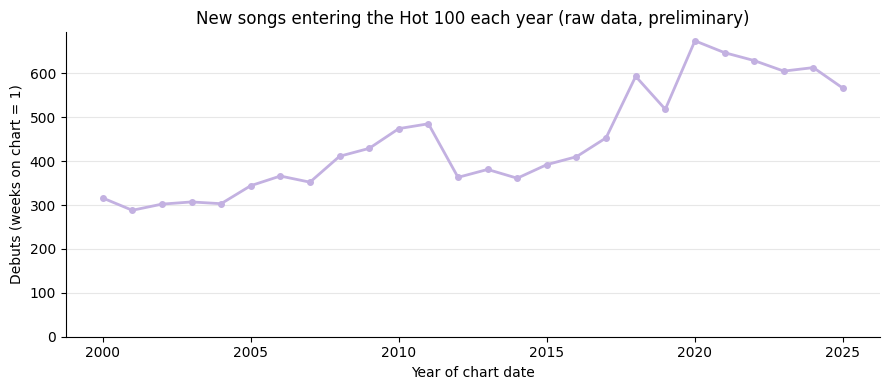

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(debuts_per_year.index, debuts_per_year.values, color=COLOR_MAIN, linewidth=2, marker="o", markersize=4)
ax.set_title("New songs entering the Hot 100 each year (raw data, preliminary)")
ax.set_xlabel("Year of chart date")
ax.set_ylabel("Debuts (weeks on chart = 1)")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

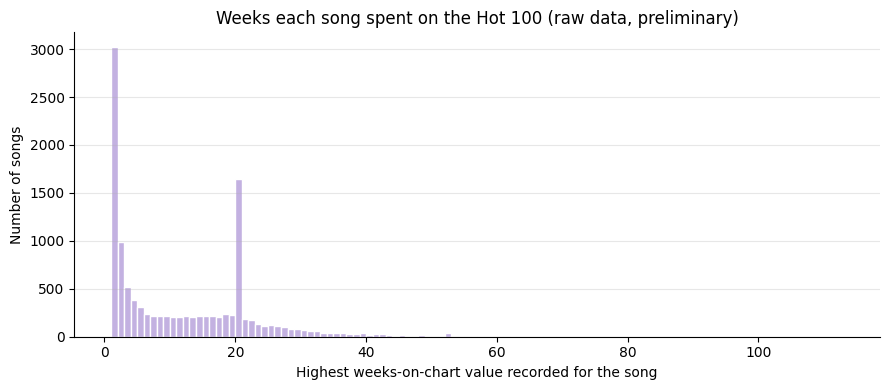

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(longest_run, bins=range(1, int(longest_run.max()) + 2), color=COLOR_MAIN, edgecolor="white")
ax.set_title("Weeks each song spent on the Hot 100 (raw data, preliminary)")
ax.set_xlabel("Highest weeks-on-chart value recorded for the song")
ax.set_ylabel("Number of songs")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 4.10 Summary of findings

**No problems found:**
- All 1,357 weekly charts are present, each with exactly 100 rows and ranks 1–100 once each.
- No duplicates; all values are whole numbers in possible ranges; all chart dates are valid Saturdays; no peak is worse than a current or last-week rank.
- No "frozen" (identical consecutive) charts in our window.

**Problems found** (observations; treatments are proposals, decided and justified in Section 5):

| # | Observation | Rows affected | Interpretation | Proposed treatment |
|---|---|---|---|---|
| 1 | "Not on last week's chart" is coded `NA` before 2022 and `0` from 2022 | 11,154 + 3,203 | Two collection processes, two codes for the same meaning (confirmed: checks C and F = 0) | Convert both to one missing-value code |
| 2 | `wks_at_no1` empty for every row in our window | 135,700 (100%) | Column only recorded since Sept 2026 | Drop the column |
| 3 | The 2018-01-06 chart disagrees with 2017-12-30: 68 last-week ranks, all 83 weeks-on-chart values (+2 instead of +1), 9 peaks | 1 chart | Cause unknown; one of the two charts is likely wrong in the source; cannot be verified without billboard.com | Keep ranks as recorded; do not rely on the supplied `last_week`/`wks_on_chart`/`peak_pos` — recompute what we need from the sequence of charts; report as a limitation |
| 4 | Same song with different capitalisation, spacing or apostrophe | 38 pairs (19 songs), almost all 2022+ | Name styling changes (some genuine, e.g. "Charli xcx") | Build a normalised song key for identifying songs; keep original text for display |
| 5 | Same song with a changed credit (remixes adding an artist, holiday songs credited differently across years) | most of the 61 check-A rows | Credits are not stable identifiers | Decide identity rules in cleaning; document remaining cases as a limitation |
| 6 | Collaborations written in many ways ("Featuring", "Feat.", "Ft.", "&", "x", "With", "And", commas) | thousands of credits | Inconsistent conventions across sources | Standardise before splitting credits into individual artists |
| 7 | Double spaces and curly apostrophes in names | 19 + 21 rows | Typing/formatting noise | Normalise in the song key |
| 8 | Rows not stored in date order | whole file | Result of how UT stacks its files | Sort by chart date and rank |
| 9 | Column `current_week` actually holds the rank | — | Misleading name | Rename (e.g. `rank`) |
| 10 | Songs on the chart at the start of 2000 debuted before our window | at most 100 songs | Their entry is not observed (left-censoring) | Flag them; exclude from "first entry" analyses |
| 11 | Debuts per year double between the early 2000s and the 2020s; spikes at 20 and ~52 weeks on chart | — | Chart-rule effects, not data errors | No cleaning; account for this in analysis |

### 4.11 Save and download the quality assessment

In [ ]:
QA_FILE = OUTPUT_DIR / "quality_assessment_billboard.json"
qa_record = {
    "record_type": "raw-data quality assessment – Billboard Hot 100 (study window)",
    "source_commit": SOURCE_COMMIT,
    "source_sha256": actual_sha256,
    "study_window": [STUDY_START, STUDY_END],
    "assessed_at_utc": datetime.now(timezone.utc).replace(microsecond=0).isoformat(),
    "results": QA_RESULTS,
}
QA_FILE.write_text(json.dumps(qa_record, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(f"Quality assessment written to: {QA_FILE}")
download_file(QA_FILE)

Quality assessment written to: outputs/quality_assessment_billboard.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Cleaning

This section turns the raw data into clean, analysis-ready tables. Every step responds to a finding of Section 4, and every decision is justified.

**Principles:**
- **The raw data is never modified.** Cleaning works on a copy; the raw file (Section 3) stays as downloaded.
- **Original values are kept where possible.** We add columns (normalised keys, flags, identifiers) rather than overwrite titles, names or reported values, so nothing is lost and every change can be traced.
- **We flag what we cannot fix.** Where the correct value cannot be known without the original source, the row is flagged, not altered. Changing values without evidence would be inventing data.
- **Every step is logged.** A cleaning log (rows before/after, values changed, justification) is saved and downloaded at the end.
- **The result is validated.** Section 5.13 re-runs the key checks of Section 4 on the clean data.

**Steps:**

| Step | What | Responds to |
|---|---|---|
| C1 | Keep the study window | scope |
| C2 | Rename columns | 4.10 #9 |
| C3 | Drop `wks_at_no1` | 4.10 #2 |
| C4 | Unify the two "not on last week's chart" codes | 4.10 #1 |
| C5 | Convert data types | 4.5 |
| C6 | Sort by date and rank | 4.10 #8 |
| C7 | Add source era; flag the 2018-01-06 chart | 4.10 #3 |
| C8 | Normalised name keys | 4.10 #4, #6, #7 |
| C9 | Song identifier, linking renamed entries | 4.10 #5 |
| C10–C11 | Flag songs whose first entry lies outside the window | 4.10 #10 |
| C12 | One-row-per-song table | our outcome |

### 5.1 Cleaning log

In [ ]:
CLEANING_LOG = []

def log_step(step, description, rows_before, rows_after, values_changed=0, justification=""):
    """Record one cleaning step so the whole cleaning process can be traced afterwards."""
    CLEANING_LOG.append({
        "step": step, "description": description,
        "rows_before": int(rows_before), "rows_after": int(rows_after),
        "values_changed": int(values_changed), "justification": justification,
    })
    print(f"[{step}] {description}\n      rows {rows_before:,} → {rows_after:,} | values changed: {values_changed:,}")

### 5.2 Study window (C1)

In [ ]:
clean = raw_hot100.loc[in_scope].copy()
log_step("C1", "Keep only charts dated within the study window",
         len(raw_hot100), len(clean),
         justification=f"Our question covers charts dated {STUDY_START} to {STUDY_END}.")

[C1] Keep only charts dated within the study window
      rows 355,900 → 135,700 | values changed: 0


### 5.3 Clear column names (C2)

In [ ]:
RENAME = {
    "chart_week":   "chart_date",
    "current_week": "rank",
    "last_week":    "last_week_rank",
    "peak_pos":     "peak_rank_reported",
    "wks_on_chart": "weeks_on_chart_reported",
}
clean = clean.rename(columns=RENAME)
log_step("C2", "Rename columns to describe their content", len(clean), len(clean),
         justification="current_week holds a rank, not a week; 'reported' marks values supplied by the source "
                       "that we do not fully trust (Section 4.7).")

[C2] Rename columns to describe their content
      rows 135,700 → 135,700 | values changed: 0


### 5.4 Remove the empty column (C3)

In [ ]:
if not (clean["wks_at_no1"] == "NA").all():
    raise ValueError("wks_at_no1 is not empty in the window – re-examine before dropping it.")
clean = clean.drop(columns="wks_at_no1")
log_step("C3", "Drop the wks_at_no1 column", len(clean), len(clean),
         justification="Empty for 100% of rows in the window (Section 4.4); it carries no information.")

[C3] Drop the wks_at_no1 column
      rows 135,700 → 135,700 | values changed: 0


### 5.5 One code for "not on last week's chart" (C4)

In [ ]:
is_missing_code = clean["last_week_rank"].isin(["NA", "0"])
n_zero_codes = int((clean["last_week_rank"] == "0").sum())
clean.loc[is_missing_code, "last_week_rank"] = None
log_step("C4", "Treat both codes for 'not on last week's chart' (NA and 0) as missing",
         len(clean), len(clean), values_changed=n_zero_codes,
         justification="0 is not a valid rank; checks C and F in Section 4.7 show 0 is used exactly where "
                       "NA is used before 2022.")

[C4] Treat both codes for 'not on last week's chart' (NA and 0) as missing
      rows 135,700 → 135,700 | values changed: 3,203


### 5.6 Data types (C5)

In [ ]:
clean["chart_date"] = pd.to_datetime(clean["chart_date"], format="%Y-%m-%d")
for col in ["rank", "last_week_rank", "peak_rank_reported", "weeks_on_chart_reported"]:
    clean[col] = pd.to_numeric(clean[col]).astype("Int64")
log_step("C5", "Convert chart dates to dates and ranks/counts to whole numbers", len(clean), len(clean),
         justification="Allows date arithmetic and numeric comparisons; Int64 keeps missing values without "
                       "turning whole numbers into decimals.")
clean.dtypes.to_frame("type")

[C5] Convert chart dates to dates and ranks/counts to whole numbers
      rows 135,700 → 135,700 | values changed: 0


,type
chart_date,datetime64[ns]
rank,Int64
title,object
performer,object
last_week_rank,Int64
peak_rank_reported,Int64
weeks_on_chart_reported,Int64


### 5.7 Order (C6)

In [ ]:
clean = clean.sort_values(["chart_date", "rank"]).reset_index(drop=True)
log_step("C6", "Sort rows by chart date, then rank", len(clean), len(clean),
         justification="The source file is not in date order (Section 3.3); week-to-week steps need it.")

[C6] Sort rows by chart date, then rank
      rows 135,700 → 135,700 | values changed: 0


### 5.8 Provenance and flag columns (C7)

We keep the collection era as a column, so any later result can be checked for differences between the two collection processes. The 2018-01-06 chart is **flagged, not changed and not removed**: its ranks are valid (complete, 1–100, consistent with peaks), but its last-week, peak and weeks-on-chart values disagree with the previous chart, and without access to billboard.com we cannot know which of the two charts is wrong. Removing it would create a gap in an otherwise complete series; correcting it would mean inventing values.

In [ ]:
ERA_SPLIT_DATE = pd.Timestamp("2022-01-01")
INCONSISTENT_CHART = pd.Timestamp("2018-01-06")
clean["source_era"] = np.where(clean["chart_date"] < ERA_SPLIT_DATE, "pre-2022 archive", "2022+ UT scrape")
clean["flag_inconsistent_chart"] = clean["chart_date"] == INCONSISTENT_CHART
log_step("C7", "Add source_era and flag the 2018-01-06 chart", len(clean), len(clean),
         justification="Keeps provenance visible in the clean data; the flagged chart's last-week, peak and "
                       "weeks values are internally inconsistent (Section 4.7c) and cannot be corrected without "
                       "the original source, so they are flagged rather than changed.")
print(f"Rows flagged: {int(clean['flag_inconsistent_chart'].sum())}")

[C7] Add source_era and flag the 2018-01-06 chart
      rows 135,700 → 135,700 | values changed: 0
Rows flagged: 100


### 5.9 Normalised name keys (C8)

To decide whether two rows are the same song, we compare simplified versions of their title and performer ("keys"). The original text is kept unchanged for display.

| Rule | Example | Why |
|---|---|---|
| Lower case | `Charli XCX` = `Charli xcx` | Capitalisation styling changes (Section 4.8) |
| All apostrophe styles → `'` | `Victoria’s` = `Victoria's` | Typographic variants |
| `Feat.` / `Ft.` → `featuring` | `Ariana Grande Feat. Doja Cat` | Older rows abbreviate (Section 4.8) |
| `&` → `and` | `A & B` = `A and B` | Same meaning |
| Remove punctuation and symbols | `'Til You Can't` = `Til You Can't`; `Nat "King" Cole` = `Nat King Cole` | Punctuation varies across sources |
| Collapse spaces | `W O R K I N  M E` | Double spaces (Section 4.8) |

Risk: too aggressive a key could merge two *different* songs. We therefore list every merge the keys produce and inspect them.

In [ ]:
def make_key(text):
    """Simplified version of a title or performer, used only to decide whether two names are the same."""
    return (text.str.lower()
                .str.replace("[’‘`´]", "'", regex=True)                  # all apostrophe styles → '
                .str.replace(r"\b(?:feat|ft)\.", "featuring", regex=True) # Feat. / Ft. → featuring
                .str.replace("&", " and ", regex=False)                    # & → and
                .str.replace(r"[^a-z0-9 ]", "", regex=True)                # drop punctuation and symbols
                .str.replace(r"\s+", " ", regex=True)                      # collapse repeated spaces
                .str.strip())

clean["title_key"]     = make_key(clean["title"])
clean["performer_key"] = make_key(clean["performer"])

if (clean["title_key"] == "").any() or (clean["performer_key"] == "").any():
    raise ValueError("A key became empty – make_key removed too much.")

n_exact = len(clean[["title", "performer"]].drop_duplicates())
n_keyed = len(clean[["title_key", "performer_key"]].drop_duplicates())
log_step("C8", "Add normalised title and performer keys (original text kept)", len(clean), len(clean),
         justification=f"Spelling variants split songs (Section 4.8): {n_exact:,} exact title+performer "
                       f"pairs become {n_keyed:,} keyed pairs.")

[C8] Add normalised title and performer keys (original text kept)
      rows 135,700 → 135,700 | values changed: 0


In [ ]:
# Every group of original spellings that the keys treat as one: inspect for wrong merges.
merged_spellings = (clean[["title", "performer", "title_key", "performer_key"]].drop_duplicates()
                    .groupby(["title_key", "performer_key"]).filter(lambda g: len(g) > 1)
                    .sort_values(["title_key", "performer_key"]))
merged_spellings[["title", "performer"]]

,title,performer
127772,360,Charli XCX
128540,360,Charli xcx
128380,Apple,Charli XCX
128551,Apple,Charli xcx
114995,Beers On Me,"Dierks Bentley, Breland & HARDY"
115657,Beers On Me,"Dierks Bentley, BRELAND & HARDY"
132180,Blue Strips,Jessie Murph
133525,Blue Strips,jessie murph
133179,Bottle Rockets,Scotty McCreery & Hootie & The Blowfish
133567,Bottle Rockets,Scotty McCreery & Hootie & the Blowfish


   We inspected every group above: each is one song written in different ways (capitalisation, punctuation, "HUNTRX" vs "HUNTR/X:", "Sing!" vs "Sing"). No different songs were merged.

### 5.10 Song identifier (C9)

Some songs appear under a changed credit from one week to the next (e.g. "Die For You" by The Weeknd, then by "The Weeknd & Ariana Grande" after the remix). Keys cannot fix this, because the names genuinely differ.

**Our rule uses Billboard's own evidence.** Each row's last-week rank says where the song was the week before. If that position on the previous chart holds an entry with a *different* name, but the **same title or the same performer**, then Billboard itself treats the two as one continuing chart entry, so we link them.

Safeguards:
- the 2018-01-06 chart is excluded, because its last-week ranks are unreliable (5.8);
- links whose title *and* performer both differ are rejected;
- after linking, no song may appear twice in the same week; if it did, two different songs would have been merged, and the notebook stops.

Linked names are collected into groups; each group is one song and receives a `song_id`.

In [ ]:
# Each distinct (title_key, performer_key) pair gets a number; linking puts numbers into shared groups.
pairs = clean[["title_key", "performer_key"]].drop_duplicates()
pair_id = {pair: i for i, pair in enumerate(pairs.itertuples(index=False, name=None))}
parent = list(range(len(pair_id)))      # at the start, every pair is its own group

def find(i):
    """Return the representative ('root') of the group that pair i belongs to."""
    while parent[i] != i:
        parent[i] = parent[parent[i]]   # shortcut: point closer to the root (keeps groups fast to search)
        i = parent[i]
    return i

def union(a, b):
    """Merge the groups of pairs a and b."""
    root_a, root_b = find(a), find(b)
    if root_a != root_b:
        parent[root_b] = root_a

In [ ]:
previous = clean[["chart_date", "rank", "title_key", "performer_key"]].rename(columns={
    "chart_date": "prev_date", "rank": "last_week_rank",
    "title_key": "prev_title_key", "performer_key": "prev_performer_key"})

# For each row with a last-week rank: what was at that rank on the previous chart?
# Join contract: many-to-one – each (week, rank) position holds exactly one entry (Section 4.3).
with_last_week = clean[clean["last_week_rank"].notna()]
linked = (with_last_week.assign(prev_date=with_last_week["chart_date"] - pd.Timedelta(days=7))
                        .merge(previous, on=["prev_date", "last_week_rank"], how="inner", validate="many_to_one"))
if len(linked) > len(with_last_week):
    raise ValueError("Join contract broken: rows multiplied when looking up last week's position.")
print(f"Rows with a last-week rank: {len(with_last_week):,} | found on the previous chart: {len(linked):,} "
      f"(the rest point to 1999-12-25, outside our data, or to a missing entry – Section 4.7)")
linked = linked[~linked["flag_inconsistent_chart"]]

name_changed = ((linked["title_key"] != linked["prev_title_key"]) |
                (linked["performer_key"] != linked["prev_performer_key"]))
candidates = linked[name_changed]
shares_title_or_performer = ((candidates["title_key"] == candidates["prev_title_key"]) |
                             (candidates["performer_key"] == candidates["prev_performer_key"]))
accepted = candidates[shares_title_or_performer]
rejected = candidates[~shares_title_or_performer]

for row in accepted.itertuples():
    union(pair_id[(row.prev_title_key, row.prev_performer_key)], pair_id[(row.title_key, row.performer_key)])

print(f"Rows whose last-week rank points to a differently named entry: {len(candidates)}")
print(f"  accepted as the same song (same title or same performer): {len(accepted)}")
print(f"  rejected (nothing in common): {len(rejected)}")
accepted[["chart_date", "rank", "title", "performer", "prev_title_key", "prev_performer_key"]]

Rows with a last-week rank: 121,343 | found on the previous chart: 121,248 (the rest point to 1999-12-25, outside our data, or to a missing entry – Section 4.7)
Rows whose last-week rank points to a differently named entry: 34
  accepted as the same song (same title or same performer): 34
  rejected (nothing in common): 0


,chart_date,rank,title,performer,prev_title_key,prev_performer_key
100725,2021-05-08,1,Save Your Tears,The Weeknd & Ariana Grande,save your tears,the weeknd
100747,2021-05-08,23,Without You,The Kid LAROI & Miley Cyrus,without you,the kid laroi
100905,2021-05-22,9,Without You,The Kid LAROI,without you,the kid laroi and miley cyrus
100931,2021-05-22,36,34+35,Ariana Grande Feat. Doja Cat & Megan Thee Stal...,3435,ariana grande
101648,2021-07-24,4,Levitating,Dua Lipa,levitating,dua lipa featuring dababy
101712,2021-07-24,72,Essence,Wizkid Featuring Justin Bieber & Tems,essence,wizkid featuring tems
108828,2023-03-11,1,Die For You,The Weeknd & Ariana Grande,die for you,the weeknd
109969,2023-06-10,2,Karma,Taylor Swift Featuring Ice Spice,karma,taylor swift
110426,2023-07-15,46,Area Codes,Kaliii,area codes,kali
110640,2023-08-05,25,Dial Drunk,Noah Kahan With Post Malone,dial drunk,noah kahan


In [ ]:
root_of_pair = {pair: find(i) for pair, i in pair_id.items()}
clean["song_root"] = [root_of_pair[p] for p in zip(clean["title_key"], clean["performer_key"])]

# Readable IDs, numbered in order of first appearance: S00001, S00002, ...
first_seen_order = clean.drop_duplicates("song_root")["song_root"]
song_number = {root: f"S{n:05d}" for n, root in enumerate(first_seen_order, start=1)}
clean["song_id"] = clean["song_root"].map(song_number)
clean = clean.drop(columns="song_root")

collisions = int(clean.duplicated(["chart_date", "song_id"]).sum())
if collisions:
    raise ValueError(f"{collisions} rows: one song_id twice in the same week – linking merged different songs.")
log_step("C9", "Assign a song_id, linking renamed entries via the chart's own last-week ranks",
         len(clean), len(clean),
         justification=f"{len(accepted)} renamed entries linked; {len(rejected)} rejected; "
                       f"{clean['song_id'].nunique():,} songs; no song appears twice in a week.")
print(f"Distinct songs: {clean['song_id'].nunique():,}")

[C9] Assign a song_id, linking renamed entries via the chart's own last-week ranks
      rows 135,700 → 135,700 | values changed: 0
Distinct songs: 11,728


### 5.11 Is each song's first chart entry observed? (C10–C11)

Our outcome includes *when* a song first reached the chart. That date is only known if the first entry lies inside our window. Songs already on the chart before 2000 (e.g. the whole first chart of 2000) first entered earlier: their entry is **left-censored**. We flag them rather than delete them: they are still songs that reached the chart, and the analysis decides how to treat them.

We detect them in two independent ways and compare:
1. **Direct evidence:** the song's keys appear in the raw file before 2000.
2. **The source's own counter:** at the song's first appearance in our window, its reported weeks-on-chart is above 1.

In [ ]:
pre_window = raw_hot100[raw_hot100["chart_week"] < STUDY_START]
pre_window_pairs = set(zip(make_key(pre_window["title"]), make_key(pre_window["performer"])))
pair_charted_before = pd.Series(
    [p in pre_window_pairs for p in zip(clean["title_key"], clean["performer_key"])], index=clean.index)
songs_charted_before = set(clean.loc[pair_charted_before, "song_id"])
clean["charted_before_window"] = clean["song_id"].isin(songs_charted_before)
log_step("C10", "Flag songs that were already on the chart before 2000", len(clean), len(clean),
         justification="Their first entry is outside our window (left-censoring); found by matching keys "
                       "against the pre-2000 part of the raw file.")
print(f"Songs that charted before 2000: {len(songs_charted_before):,}")

[C10] Flag songs that were already on the chart before 2000
      rows 135,700 → 135,700 | values changed: 0
Songs that charted before 2000: 133


In [ ]:
first_rows = clean.sort_values(["chart_date", "rank"]).drop_duplicates("song_id")
display(pd.crosstab(first_rows["charted_before_window"],
                    first_rows["weeks_on_chart_reported"] > 1,
                    rownames=["found before 2000 (our flag)"],
                    colnames=["source: weeks on chart > 1 at first appearance"]))

reported_earlier_weeks = set(first_rows.loc[first_rows["weeks_on_chart_reported"] > 1, "song_id"])
uncertain = songs_charted_before | reported_earlier_weeks
clean["first_entry_uncertain"] = clean["song_id"].isin(uncertain)
log_step("C11", "Flag songs whose first chart entry is not observed in the window", len(clean), len(clean),
         justification=f"{len(songs_charted_before)} songs found before 2000, plus "
                       f"{len(reported_earlier_weeks - songs_charted_before)} whose own weeks-on-chart counter shows "
                       f"earlier weeks we cannot match (e.g. an earlier run under another name): "
                       f"{len(uncertain)} songs in total.")

unmatched = first_rows[~first_rows["charted_before_window"] & (first_rows["weeks_on_chart_reported"] > 1)]
unmatched[["chart_date", "rank", "title", "performer", "weeks_on_chart_reported"]]

source: weeks on chart > 1 at first appearance,False,True
found before 2000 (our flag),,
False,11580,15
True,0,133


[C11] Flag songs whose first chart entry is not observed in the window
      rows 135,700 → 135,700 | values changed: 0


,chart_date,rank,title,performer,weeks_on_chart_reported
94042,2018-01-06,43,River,Eminem Featuring Ed Sheeran,2
94079,2018-01-06,80,Ice Tray,Quavo & Lil Yachty,2
111724,2021-05-29,25,the.climb.back,J. Cole,3
117107,2022-06-11,8,Running Up That Hill (A Deal With God),Kate Bush,21
120048,2022-12-31,49,Linus And Lucy (Peanuts Theme),Vince Guaraldi Trio,2
120140,2023-01-07,41,(There's No Place Like) Home For The Holidays ...,Perry Como With Mitchell Ayers And His Orchestra,13
122237,2023-06-03,38,America Has A Problem,Beyonce Featuring Kendrick Lamar,2
124492,2023-11-04,93,Oklahoma Smokeshow,Zach Bryan,10
124922,2023-12-09,23,White Christmas,Bing Crosby With Ken Darby Singers & John Scot...,31
127399,2024-05-25,100,Think I'm In Love With You,Chris Stapleton,2


### 5.12 One row per song (C12)

Our outcome (whether and when a song reached the chart) describes a song, not a chart week. We therefore build a second table with one row per song, alongside the weekly table. Keeping both, rather than one wide table, avoids repeating song information in every week (tidy data) and prepares the storage design of Section 6.

For songs with several spellings, the displayed title and performer are the spelling used in most weeks (ties broken alphabetically, so the result is always the same).

In [ ]:
def most_common_spelling(names):
    return names.mode().iloc[0]

songs = (clean.groupby("song_id")
              .agg(title=("title", most_common_spelling),
                   performer=("performer", most_common_spelling),
                   first_chart_date=("chart_date", "min"),
                   last_chart_date=("chart_date", "max"),
                   weeks_in_window=("chart_date", "size"),
                   best_rank_in_window=("rank", "min"),
                   charted_before_window=("charted_before_window", "first"),
                   first_entry_uncertain=("first_entry_uncertain", "first"))
              .reset_index())

first_appearance = clean.sort_values(["chart_date", "rank"]).drop_duplicates("song_id").set_index("song_id")
songs["entry_rank"] = songs["song_id"].map(first_appearance["rank"]).astype("Int64")

by_song = clean.sort_values(["song_id", "chart_date"])
starts_new_run = by_song.groupby("song_id")["chart_date"].diff() != pd.Timedelta(days=7)
songs["runs_in_window"] = songs["song_id"].map(starts_new_run.groupby(by_song["song_id"]).sum()).astype(int)

name_variants = clean.drop_duplicates(["song_id", "title", "performer"]).groupby("song_id").size()
songs["name_variants"] = songs["song_id"].map(name_variants).astype(int)

songs = songs[["song_id", "title", "performer", "first_chart_date", "entry_rank", "last_chart_date",
               "weeks_in_window", "runs_in_window", "best_rank_in_window", "name_variants",
               "charted_before_window", "first_entry_uncertain"]]
log_step("C12", "Build the one-row-per-song table", len(clean), len(songs),
         justification="Our outcome (whether and when a song reached the chart) describes a song, not a chart week.")
songs.head()

[C12] Build the one-row-per-song table
      rows 135,700 → 11,728 | values changed: 0


,song_id,title,performer,first_chart_date,entry_rank,last_chart_date,weeks_in_window,runs_in_window,best_rank_in_window,name_variants,charted_before_window,first_entry_uncertain
0,S00001,Smooth,Santana Featuring Rob Thomas,2000-01-01,1,2000-09-02,36,1,1,1,True,True
1,S00002,Back At One,Brian McKnight,2000-01-01,2,2000-05-06,19,1,2,1,True,True
2,S00003,I Wanna Love You Forever,Jessica Simpson,2000-01-01,3,2000-02-26,9,1,3,1,True,True
3,S00004,My Love Is Your Love,Whitney Houston,2000-01-01,4,2000-03-11,11,1,4,1,True,True
4,S00005,I Knew I Loved You,Savage Garden,2000-01-01,5,2000-06-03,23,1,1,1,True,True


### 5.13 Validation of the clean data

We re-run the key checks on the clean tables. All counts must match expectations; the continuity checks of Section 4.7, now using `song_id`, must show no remaining inconsistencies outside the flagged 2018-01-06 chart. If any check fails, the notebook stops.

In [ ]:
weekly_cols = ["chart_date", "rank", "song_id", "title", "performer", "last_week_rank",
               "peak_rank_reported", "weeks_on_chart_reported", "title_key", "performer_key",
               "source_era", "flag_inconsistent_chart", "charted_before_window", "first_entry_uncertain"]
weekly = clean[weekly_cols]

# Join contract: many-to-one – a song appears at most once per week, so each row has at most one partner.
prev_ids = weekly[["chart_date", "song_id", "rank"]].rename(columns={"chart_date": "prev_date", "rank": "prev_rank"})
chk = (weekly.assign(prev_date=weekly["chart_date"] - pd.Timedelta(days=7))
             .merge(prev_ids, on=["prev_date", "song_id"], how="left", validate="many_to_one"))
if len(chk) != len(weekly):
    raise ValueError(f"Join contract broken: {len(weekly):,} rows became {len(chk):,}.")
in_window_prev = chk["prev_date"] >= pd.Timestamp(STUDY_START)
not_flagged = ~chk["flag_inconsistent_chart"]

validation = {
    "rows (expected 135,700)": len(weekly),
    "weekly charts (expected 1,357)": weekly["chart_date"].nunique(),
    "weeks without ranks 1-100 exactly once": int(weekly.groupby("chart_date")["rank"]
                                                  .apply(lambda r: sorted(r) != list(range(1, 101))).sum()),
    "same song twice in one week": int(weekly.duplicated(["chart_date", "song_id"]).sum()),
    "missing values outside last_week_rank": int(weekly.drop(columns="last_week_rank").isna().sum().sum()),
    "missing last_week_rank (expected 14,357)": int(weekly["last_week_rank"].isna().sum()),
    "last-week rank given but song not on previous chart (excl. 2018-01-06)":
        int((in_window_prev & chk["last_week_rank"].notna() & chk["prev_rank"].isna() & not_flagged).sum()),
    "last-week rank differs from previous chart (excl. 2018-01-06)":
        int((in_window_prev & chk["prev_rank"].notna() & (chk["last_week_rank"] != chk["prev_rank"]) & not_flagged).sum()),
    "songs": len(songs),
}

must_be_zero = [k for k in validation if k.startswith(("weeks without", "same song", "missing values outside", "last-week rank"))]
failed = {k: validation[k] for k in must_be_zero if validation[k] != 0}
if failed:
    raise ValueError(f"Validation failed: {failed}")
pd.Series(validation, name="value").to_frame()

,value
"rows (expected 135,700)",135700
"weekly charts (expected 1,357)",1357
weeks without ranks 1-100 exactly once,0
same song twice in one week,0
missing values outside last_week_rank,0
"missing last_week_rank (expected 14,357)",14357
last-week rank given but song not on previous chart (excl. 2018-01-06),0
last-week rank differs from previous chart (excl. 2018-01-06),0
songs,11728


### 5.14 Save the clean tables and the cleaning log

The clean tables are written as CSV files inside this Colab session, where later sections can use them. CSV here is an interim working format; the storage format is chosen and justified in Section 6. The data files are **not** downloaded by default (Section 1.8: the chart data is not redistributed, and anyone can regenerate them by running this notebook). The cleaning log is downloaded, since it is our documentation.

In [ ]:
CLEAN_DIR = OUTPUT_DIR / "clean"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
WEEKLY_FILE = CLEAN_DIR / "hot100_weekly_clean.csv"
SONGS_FILE  = CLEAN_DIR / "hot100_songs.csv"
weekly.to_csv(WEEKLY_FILE, index=False, date_format="%Y-%m-%d")
songs.to_csv(SONGS_FILE, index=False, date_format="%Y-%m-%d")

CLEANING_LOG_FILE = OUTPUT_DIR / "cleaning_log_billboard.json"
CLEANING_LOG_FILE.write_text(json.dumps({
    "record_type": "cleaning log – Billboard Hot 100",
    "source_commit": SOURCE_COMMIT,
    "source_sha256": actual_sha256,
    "cleaned_at_utc": datetime.now(timezone.utc).replace(microsecond=0).isoformat(),
    "steps": CLEANING_LOG,
    "validation": validation,
    "outputs": {
        "weekly_table": {"file": WEEKLY_FILE.name, "rows": len(weekly), "columns": list(weekly.columns)},
        "songs_table":  {"file": SONGS_FILE.name,  "rows": len(songs),  "columns": list(songs.columns)},
    },
}, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
download_file(CLEANING_LOG_FILE)

DOWNLOAD_CLEAN_DATA = False   # True only for private use within the group (Section 1.8)
if DOWNLOAD_CLEAN_DATA:
    download_file(WEEKLY_FILE)
    download_file(SONGS_FILE)

pd.DataFrame(CLEANING_LOG)[["step", "description", "rows_before", "rows_after", "values_changed"]]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,step,description,rows_before,rows_after,values_changed
0,C1,Keep only charts dated within the study window,355900,135700,0
1,C2,Rename columns to describe their content,135700,135700,0
2,C3,Drop the wks_at_no1 column,135700,135700,0
3,C4,Treat both codes for 'not on last week's chart...,135700,135700,3203
4,C5,Convert chart dates to dates and ranks/counts ...,135700,135700,0
5,C6,"Sort rows by chart date, then rank",135700,135700,0
6,C7,Add source_era and flag the 2018-01-06 chart,135700,135700,0
7,C8,Add normalised title and performer keys (origi...,135700,135700,0
8,C9,"Assign a song_id, linking renamed entries via ...",135700,135700,0
9,C10,Flag songs that were already on the chart befo...,135700,135700,0


### 5.15 What we deliberately did not change

| Not done | Why |
|---|---|
| Correct or delete the 2018-01-06 chart | Its ranks are valid; which neighbouring chart is wrong cannot be determined without the original source. Flagged instead (C7). |
| Edit titles or performer names | Original text is information (e.g. "Charli xcx" is the artist's real restyling). Identity uses keys instead (C8). |
| Split performer credits into individual artists | Separators are ambiguous inside band names ("Earth, Wind & Fire", "Tyler, The Creator", "Hootie & The Blowfish"); naive splitting would create false artists. Deferred to the step where we build artist-level information, with a dedicated, tested method. |
| Remove songs that charted before 2000 | They did reach the chart; whether to include them is an analysis decision. Flagged (C10–C11). |
| Remove holiday songs or unusual performers (e.g. Glee Cast) | They are real chart entries, not errors. Whether they need special treatment is an analysis question. |
| Recompute last-week, peak and weeks-on-chart columns | Not needed for our outcome (reaching the chart); the source's values are kept, clearly labelled `_reported`, and the flagged chart marks where they fail. |

### 5.16 Summary of Section 5

**Observations:**
- All 135,700 rows in the window are kept; only one value type was changed (3,203 `0` codes → missing).
- Normalised keys merged spelling variants: 11,785 exact title+performer pairs → 11,759.
- 34 renamed chart entries were linked using Billboard's own last-week ranks, with none rejected and no song appearing twice in a week: **11,728 songs**.
- 148 songs have a first entry outside our window (133 found before 2000, 15 identified only by the source's weeks counter).
- After cleaning, no week-to-week inconsistency remains except in the flagged 2018-01-06 chart.

**Interpretation:** the clean data gives, for each song, whether and when it first reached the Hot 100 within 2000–2025 (reliable for 11,580 songs), which is what our research question requires from the Billboard data.

**Remaining limitations:**
- Identity across long gaps under a different credit can only be detected through the source's counter (the 15 cases), so some similar cases may remain undetected.
- The 2018-01-06 chart's reported values are unreliable.
- The two collection eras differ in conventions; `source_era` is kept so results can be checked by era.

## 6. Storage

This section decides how the cleaned Billboard data is stored, and justifies that choice against alternatives.

**What we store:** four related kinds of information: weekly charts (1,357), songs (11,728), the different names under which songs were printed (11,785), and chart entries, i.e. one song at one rank in one week (135,700).

**Requirements, derived from our project:**

| # | Requirement | Why we need it |
|---|---|---|
| R1 | Runs in Colab with nothing to install and no server | Reproducibility: anyone can rerun the notebook (Section 0) |
| R2 | Enforces the integrity rules found in Section 4 | Our main data risks are duplicates, impossible ranks and identity errors (4.6–4.8, C9) |
| R3 | Represents relationships between songs, names and weekly entries | Songs appear in many weeks and under several names; MusicBrainz matches will add more linked tables |
| R4 | Can be queried in a readable, standard way | Analyses must be traceable by a reader (brief: reproducibility) |
| R5 | Keeps data types (dates, whole numbers, flags) | Avoids silent errors when data is reloaded |
| R6 | Proportionate to the data size (~150,000 rows) | The brief warns against choosing technology for its complexity |
| R7 | One private file, easy to keep out of public repositories | No redistribution of chart data (Section 1.8) |

### 6.1 Options considered

| Option | What it is | Fit with our requirements | Verdict |
|---|---|---|---|
| CSV files | Plain-text tables | R1 ✓, R6 ✓; no rules enforced (R2 ✗), no relationships (R3 ✗), types lost on reload (R5 ✗) | Tested in 6.7 |
| Excel | Spreadsheet file | Same weaknesses as CSV, plus automatic reformatting of values (e.g. dates) and manual-editing risk | Rejected |
| Parquet files | Compressed, typed column files | R1 ✓, R5 ✓, R6 ✓, very small and fast; no rules or relationships (R2 ✗, R3 ✗) | Tested in 6.7 |
| **SQLite** [chosen] | A relational database in a single file, built into Python | R1–R4 ✓, R6 ✓, R7 ✓; no native date or boolean type (R5 partly) | **Tested in 6.7; chosen (6.8)** |
| DuckDB | An analytical database, also single-file | Strong for analytics and supports constraints, but an extra library to install and maintain; its speed advantage is irrelevant at our size | Not needed |
| PostgreSQL | A full database server | Strongest features, but needs a running server, so a reader cannot rerun the notebook in Colab (R1 ✗); far beyond our data size (R6 ✗) | Rejected for the Billboard data |
| MongoDB | A document (non-relational) database | Our data is tabular with clear relationships; a document model adds nothing and needs a server | Rejected |

### 6.2 Data model

We split the clean data into four tables so that each fact is stored once (normalisation), and we let the database enforce the rules found in Section 4.

| Table | One row per… | Key | Main columns |
|---|---|---|---|
| `charts` | weekly chart | `chart_date` | `source_era`, `flag_inconsistent_chart` |
| `songs` | song | `song_id` | display title and performer, `charted_before_window`, `first_entry_uncertain` |
| `song_names` | way a song was printed | `name_id` | `song_id`, title and performer as printed, their normalised keys |
| `chart_entries` | song at a rank in a week | (`chart_date`, `rank`) | `song_id`, `name_id`, last-week rank, reported peak and weeks |

**Relationships:** each chart entry belongs to one chart, one song and one printed name; each song has one or more printed names.

```
  charts ──1:many──> chart_entries <──many:1── songs ──1:many──> song_names
                            │                                        ▲
                            └─────────── many:1 (name_id) ───────────┘
```


**Rules the database enforces, and the finding behind each:**

| Rule | Finding |
|---|---|
| (`chart_date`, `rank`) unique | 4.3 / 4.6: one song per rank per week |
| (`chart_date`, `song_id`) unique | 4.6 / C9: a song appears at most once per week |
| `rank`, `peak_rank_reported` between 1 and 100 | 4.5 |
| `last_week_rank` between 1 and 100, or empty | 4.4: the `0` code must never return |
| every entry refers to an existing chart, song and name (foreign keys) | no orphan rows |
| each printed (title, performer) belongs to exactly one song | C8–C9: identity is unambiguous |

**Design choices:**
- **Era and flag are stored once per chart**, not repeated in 100 rows per week.
- **Song statistics (first and last chart date, weeks, best rank) are not stored but calculated by a view** (`song_summary`, a saved query). A stored copy could become outdated; a view is always consistent with the entries.
- **`songs` stores the two "first entry" flags** because they depend on pre-2000 data, which is not in the database.
- **Deliberate redundancy:** `song_id` in `chart_entries` could be looked up through `name_id`. We keep it because it lets the database enforce "one song once per week", and it keeps queries simple. A check in 6.5 confirms the two never disagree.
- **SQLite has no date or true/false type:** dates are stored as `YYYY-MM-DD` text (which sorts correctly and works with SQLite's date functions) and flags as 0/1.
- **`song_names` is designed for later matching with MusicBrainz:** it lists every spelling of every song with its normalised keys.

### 6.3 Prepare the four tables

In [ ]:
charts_tbl = (weekly[["chart_date", "source_era", "flag_inconsistent_chart"]]
              .drop_duplicates().sort_values("chart_date").reset_index(drop=True))
if charts_tbl["chart_date"].duplicated().any():
    raise ValueError("A chart week has two different era/flag values – charts table would have a duplicate key.")

song_names_tbl = (weekly[["song_id", "title", "performer", "title_key", "performer_key"]]
                  .drop_duplicates(["title", "performer"])
                  .sort_values(["song_id", "title", "performer"]).reset_index(drop=True))
song_names_tbl.insert(0, "name_id", range(1, len(song_names_tbl) + 1))

songs_tbl = songs[["song_id", "title", "performer", "charted_before_window", "first_entry_uncertain"]].rename(
    columns={"title": "display_title", "performer": "display_performer"})

# Join contract: many-to-one (many weekly rows share one name), every row must find its name (no orphans).
entries_tbl = (weekly.merge(song_names_tbl[["name_id", "title", "performer"]], on=["title", "performer"],
                            how="left", validate="many_to_one")
               [["chart_date", "rank", "song_id", "name_id", "last_week_rank",
                 "peak_rank_reported", "weeks_on_chart_reported"]])

if len(entries_tbl) != len(weekly):
    raise ValueError(f"Join contract broken: {len(weekly):,} weekly rows became {len(entries_tbl):,}.")
if entries_tbl["name_id"].isna().any():
    raise ValueError("Some chart entries did not find their name_id.")

for name, tbl in {"charts": charts_tbl, "songs": songs_tbl, "song_names": song_names_tbl,
                  "chart_entries": entries_tbl}.items():
    print(f"{name:14s} {len(tbl):>8,} rows  {tbl.shape[1]} columns")

charts            1,357 rows  3 columns
songs            11,728 rows  5 columns
song_names       11,785 rows  6 columns
chart_entries   135,700 rows  7 columns


### 6.4 Create the database

In [ ]:
import sqlite3   # built into Python

DB_FILE = OUTPUT_DIR / "billboard_hot100.sqlite"
if DB_FILE.exists():
    DB_FILE.unlink()          # start from an empty database on every run

SCHEMA = """
PRAGMA foreign_keys = ON;

CREATE TABLE charts (
    chart_date              TEXT    PRIMARY KEY,               -- 'YYYY-MM-DD', a Saturday
    source_era              TEXT    NOT NULL CHECK (source_era IN ('pre-2022 archive', '2022+ UT scrape')),
    flag_inconsistent_chart INTEGER NOT NULL CHECK (flag_inconsistent_chart IN (0, 1))
);

CREATE TABLE songs (
    song_id                 TEXT    PRIMARY KEY,               -- our identifier, e.g. 'S00001'
    display_title           TEXT    NOT NULL,
    display_performer       TEXT    NOT NULL,
    charted_before_window   INTEGER NOT NULL CHECK (charted_before_window IN (0, 1)),
    first_entry_uncertain   INTEGER NOT NULL CHECK (first_entry_uncertain IN (0, 1))
);

CREATE TABLE song_names (
    name_id                 INTEGER PRIMARY KEY,
    song_id                 TEXT    NOT NULL REFERENCES songs(song_id),
    title                   TEXT    NOT NULL,                  -- exactly as printed on the chart
    performer               TEXT    NOT NULL,
    title_key               TEXT    NOT NULL,
    performer_key           TEXT    NOT NULL,
    UNIQUE (title, performer)
);

CREATE TABLE chart_entries (
    chart_date              TEXT    NOT NULL REFERENCES charts(chart_date),
    rank                    INTEGER NOT NULL CHECK (rank BETWEEN 1 AND 100),
    song_id                 TEXT    NOT NULL REFERENCES songs(song_id),
    name_id                 INTEGER NOT NULL REFERENCES song_names(name_id),
    last_week_rank          INTEGER          CHECK (last_week_rank BETWEEN 1 AND 100),
    peak_rank_reported      INTEGER NOT NULL CHECK (peak_rank_reported BETWEEN 1 AND 100),
    weeks_on_chart_reported INTEGER NOT NULL CHECK (weeks_on_chart_reported >= 1),
    PRIMARY KEY (chart_date, rank),
    UNIQUE (chart_date, song_id)
);

CREATE INDEX idx_entries_song ON chart_entries(song_id);

CREATE VIEW song_summary AS
SELECT  s.song_id,
        s.display_title,
        s.display_performer,
        MIN(e.chart_date)  AS first_chart_date,
        MAX(e.chart_date)  AS last_chart_date,
        COUNT(*)           AS weeks_in_window,
        MIN(e.rank)        AS best_rank_in_window,
        s.charted_before_window,
        s.first_entry_uncertain
FROM songs s
JOIN chart_entries e ON e.song_id = s.song_id
GROUP BY s.song_id;
"""

def to_sql_ready(df):
    """Convert pandas types SQLite cannot store directly: dates → 'YYYY-MM-DD' text, True/False → 1/0."""
    out = df.copy()
    for col in out.columns:
        if pd.api.types.is_datetime64_any_dtype(out[col]):
            out[col] = out[col].dt.strftime("%Y-%m-%d")
        elif pd.api.types.is_bool_dtype(out[col]):
            out[col] = out[col].astype(int)
    return out

con = sqlite3.connect(DB_FILE)
con.executescript(SCHEMA)
for name, tbl in [("charts", charts_tbl), ("songs", songs_tbl),
                  ("song_names", song_names_tbl), ("chart_entries", entries_tbl)]:
    to_sql_ready(tbl).to_sql(name, con, if_exists="append", index=False)
con.commit()

pd.read_sql("SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name", con)

,name,type
0,chart_entries,table
1,charts,table
2,song_names,table
3,songs,table
4,song_summary,view


### 6.5 Check the database against the clean data

In [ ]:
def q(sql, params=()):
    """Run a SQL query on our database and return the result as a table."""
    return pd.read_sql(sql, con, params=params)

db_checks = {
    "charts":        q("SELECT COUNT(*) AS n FROM charts")["n"][0],
    "songs":         q("SELECT COUNT(*) AS n FROM songs")["n"][0],
    "song_names":    q("SELECT COUNT(*) AS n FROM song_names")["n"][0],
    "chart_entries": q("SELECT COUNT(*) AS n FROM chart_entries")["n"][0],
    "foreign-key violations": len(q("PRAGMA foreign_key_check")),
    "entries whose song_id disagrees with their name_id":
        q("""SELECT COUNT(*) AS n FROM chart_entries e JOIN song_names n ON n.name_id = e.name_id
             WHERE n.song_id <> e.song_id""")["n"][0],
}
display(pd.Series(db_checks, name="value").to_frame())

view = q("SELECT * FROM song_summary ORDER BY song_id")
expected = songs.sort_values("song_id").reset_index(drop=True)
view_matches_python = {
    "first_chart_date":    bool((view["first_chart_date"] == expected["first_chart_date"].dt.strftime("%Y-%m-%d")).all()),
    "last_chart_date":     bool((view["last_chart_date"]  == expected["last_chart_date"].dt.strftime("%Y-%m-%d")).all()),
    "weeks_in_window":     bool((view["weeks_in_window"]  == expected["weeks_in_window"]).all()),
    "best_rank_in_window": bool((view["best_rank_in_window"] == expected["best_rank_in_window"]).all()),
}
pd.Series(view_matches_python, name="view equals Section 5 result").to_frame()

,value
charts,1357
songs,11728
song_names,11785
chart_entries,135700
foreign-key violations,0
entries whose song_id disagrees with their name_id,0


,view equals Section 5 result
first_chart_date,True
last_chart_date,True
weeks_in_window,True
best_rank_in_window,True


### 6.6 Test that the database rejects invalid data

A rule is only useful if it works. We try to insert examples of each kind of error found in Section 4 (and others that must never happen). Each attempt runs in a transaction that is undone, so the database is unchanged afterwards. Every attempt must be rejected.

In [ ]:
new_chart = "INSERT INTO charts VALUES ('2026-01-03', '2022+ UT scrape', 0)"
violations = {
    "rank outside 1-100":             [new_chart, "INSERT INTO chart_entries VALUES ('2026-01-03', 101, 'S00001', 1, NULL, 1, 1)"],
    "two songs at the same rank":     [new_chart, "INSERT INTO chart_entries VALUES ('2026-01-03', 1, 'S00001', 1, NULL, 1, 1)",
                                                  "INSERT INTO chart_entries VALUES ('2026-01-03', 1, 'S00002', 2, NULL, 1, 1)"],
    "same song twice in one week":    [new_chart, "INSERT INTO chart_entries VALUES ('2026-01-03', 1, 'S00001', 1, NULL, 1, 1)",
                                                  "INSERT INTO chart_entries VALUES ('2026-01-03', 2, 'S00001', 1, NULL, 1, 1)"],
    "last-week rank coded as 0":      [new_chart, "INSERT INTO chart_entries VALUES ('2026-01-03', 1, 'S00001', 1, 0, 1, 1)"],
    "song that does not exist":       [new_chart, "INSERT INTO chart_entries VALUES ('2026-01-03', 1, 'S99999', 1, NULL, 1, 1)"],
    "chart week that does not exist": ["INSERT INTO chart_entries VALUES ('2026-01-10', 1, 'S00001', 1, NULL, 1, 1)"],
    "same printed name added twice":  ["INSERT INTO song_names VALUES (999999, 'S00001', 'Smooth', 'Santana Featuring Rob Thomas', 'x', 'y')"],
}

results = {}
for label, statements in violations.items():
    try:
        with con:                                   # transaction: undone automatically if anything fails
            for sql in statements:
                con.execute(sql)
            raise RuntimeError("accepted")           # never keep test rows, even if they were accepted
    except sqlite3.IntegrityError as err:
        results[label] = f"rejected – {err}"
    except RuntimeError:
        results[label] = "ACCEPTED (problem!)"

display(pd.Series(results, name="database response").to_frame())
q("SELECT (SELECT COUNT(*) FROM charts) AS charts, (SELECT COUNT(*) FROM chart_entries) AS entries")

,database response
rank outside 1-100,rejected – CHECK constraint failed: rank BETWE...
two songs at the same rank,rejected – UNIQUE constraint failed: chart_ent...
same song twice in one week,rejected – UNIQUE constraint failed: chart_ent...
last-week rank coded as 0,rejected – CHECK constraint failed: last_week_...
song that does not exist,rejected – FOREIGN KEY constraint failed
chart week that does not exist,rejected – FOREIGN KEY constraint failed
same printed name added twice,rejected – UNIQUE constraint failed: song_name...


,charts,entries
0,1357,135700


### 6.7 Decision


**Decision: Storage: SQLite.**

**Justification:**
1. **Integrity (R2) is our main risk.** Section 4 found duplicate-identity, placeholder and continuity problems; SQLite makes these impossible to reintroduce (6.6). At ~150,000 rows, the size and speed differences are a few megabytes and fractions of a second, so they do not affect our work (R6).
2. **Our data is relational (R3).** Songs, printed names and weekly entries are linked, and MusicBrainz matches will add another linked table. A relational database states and checks these links; files do not. Besides, MusicBrainz data is also stored in our SQLite per our previous choices
3. **Readable, standard queries (R4).** Recurring logic (such as each song's first week) is defined once in a view and reused, instead of being re-coded in every analysis.
4. **Nothing to install, no server, one file (R1, R7).** SQLite is part of Python, so the notebook stays fully reproducible in Colab; the single file is easy to keep private.
5. **Proportionate (R6).** SQLite is the simplest database available; PostgreSQL or MongoDB would add a server without solving any problem we have.

**Accepted costs and how we handle them:**
- *Types:* dates return as text and flags as 0/1 → a helper restores the types on every read (6.9).
- *When we would choose differently:* for much larger data used only for analysis (e.g. millions of rows), Parquet or DuckDB would be better; for data shared live between many users, PostgreSQL. Neither applies to the Billboard data.


### 6.9 Reading data back with correct types

In [ ]:
TYPE_RULES = {
    "dates":    ["chart_date"],
    "integers": ["rank", "name_id", "last_week_rank", "peak_rank_reported", "weeks_on_chart_reported",
                 "n_matched_recordings", "first_release_year", "days_release_to_chart"],
    "flags":    ["flag_inconsistent_chart", "charted_before_window", "first_entry_uncertain"],
}

def read_table(name_or_sql, connection=con):
    """Read a table, view or SELECT query from the database and restore pandas types."""
    sql = name_or_sql if name_or_sql.strip().upper().startswith("SELECT") else f"SELECT * FROM {name_or_sql}"
    df = pd.read_sql(sql, connection)
    for col in df.columns:
        is_full_date_text = df[col].dropna().astype(str).str.fullmatch(r"\d{4}-\d{2}-\d{2}").all()
        if (col in TYPE_RULES["dates"] or col.endswith("_date")) and is_full_date_text:
            df[col] = pd.to_datetime(df[col], format="%Y-%m-%d")
        elif col in TYPE_RULES["integers"]:
            df[col] = df[col].astype("Int64")
        elif col in TYPE_RULES["flags"] or col.startswith("flag_"):
            df[col] = df[col].astype(bool)
    return df

read_table("song_summary").dtypes.to_frame("type")

,type
song_id,object
display_title,object
display_performer,object
first_chart_date,datetime64[ns]
last_chart_date,datetime64[ns]
weeks_in_window,int64
best_rank_in_window,int64
charted_before_window,bool
first_entry_uncertain,bool


### 6.10 Save and download the storage documentation

In [ ]:
SCHEMA_FILE = OUTPUT_DIR / "schema_billboard.sql"
SCHEMA_FILE.write_text(SCHEMA.strip() + "\n", encoding="utf-8")

STORAGE_LOG_FILE = OUTPUT_DIR / "storage_billboard.json"
STORAGE_LOG_FILE.write_text(json.dumps({
    "record_type": "storage record – Billboard Hot 100",
    "source_commit": SOURCE_COMMIT,
    "source_sha256": actual_sha256,
    "built_at_utc": datetime.now(timezone.utc).replace(microsecond=0).isoformat(),
    "chosen_storage": "SQLite database (single file), relational schema with constraints",
    "database_file": DB_FILE.name,
    "sqlite_version": sqlite3.sqlite_version,
    "tables": {name: int(q(f"SELECT COUNT(*) AS n FROM {name}")["n"][0]) for name in TABLES},
    "views": ["song_summary"],
    "database_checks": {k: int(v) for k, v in db_checks.items()},
    "constraint_tests": results,
    "format_comparison": comparison,
}, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

download_file(SCHEMA_FILE)
download_file(STORAGE_LOG_FILE)

DOWNLOAD_DATABASE = False   # True only for private use within the group (Section 1.8)
if DOWNLOAD_DATABASE:
    download_file(DB_FILE)
print(f"Database: {DB_FILE} ({DB_FILE.stat().st_size / 1_000_000:.1f} MB)")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Database: outputs/billboard_hot100.sqlite (16.7 MB)


### 6.11 Summary of Section 6

**Observations:** the clean Billboard data is stored in a SQLite database with four tables (charts 1,357; songs 11,728; song_names 11,785; chart_entries 135,700) and one view. The database matches the cleaned data exactly, its calculated song figures equal those of Section 5, and it rejected all seven kinds of invalid data tested.

**Prepared for later:** `song_names` lists every spelling of every song with its normalised keys, ready for matching with MusicBrainz; a matching table can be added to this database, linked by `song_id`.

## 7. Descriptive analysis of the Billboard data

This section describes the songs that reached the Hot 100 between 2000 and 2025: how many, when, how they entered, how long they stayed, and who performed them.

**What these results can and cannot show.** All songs in the Billboard data reached the chart, so this section cannot identify what *determines* reaching it: that requires a comparison with songs that never charted (Sections 10–11). It describes the population of successful songs and how the chart itself changed over time, which later analyses must take into account. These limitations are fixed with MusicBrainz data and essentially it is work in progress

**Choices made for this section:**
- **Unit:** the song (`song_summary` view, Section 6).
- **Songs analysed:** the 11,580 songs whose first chart entry falls inside our window. The 148 songs with `first_entry_uncertain` (Section 5.11) are excluded, because their true entry date is earlier than what we observe.
- **Positions and longevity** are used only to describe how songs enter and how the chart changed, not as measures of success (consistent with our definition).
- Each result is followed by **observations** and, separately, **interpretations**.

### 7.1 Data and chart settings

In [ ]:
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DESCRIPTIVE_RESULTS = {}

def style_axes(ax, title, xlabel, ylabel):
    """Apply the same labels and light styling to every chart."""
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

def save_figure(fig, name):
    """Save a chart as a high-resolution PNG for the report and presentation."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    return path

songs_desc   = read_table("song_summary")
entries_desc = read_table("chart_entries")

entry_rank = (entries_desc.sort_values(["chart_date", "rank"])
              .drop_duplicates("song_id").set_index("song_id")["rank"])
songs_desc["entry_rank"] = songs_desc["song_id"].map(entry_rank)
songs_desc["entry_year"] = songs_desc["first_chart_date"].dt.year

entered = songs_desc[~songs_desc["first_entry_uncertain"]].copy()
print(f"Songs in the database               : {len(songs_desc):,}")
print(f"Songs whose first entry we observe  : {len(entered):,}")
print(f"Excluded (first entry before window): {len(songs_desc) - len(entered):,}")

Songs in the database               : 11,728
Songs whose first entry we observe  : 11,580
Excluded (first entry before window): 148


### 7.2 How many songs reach the chart each year?

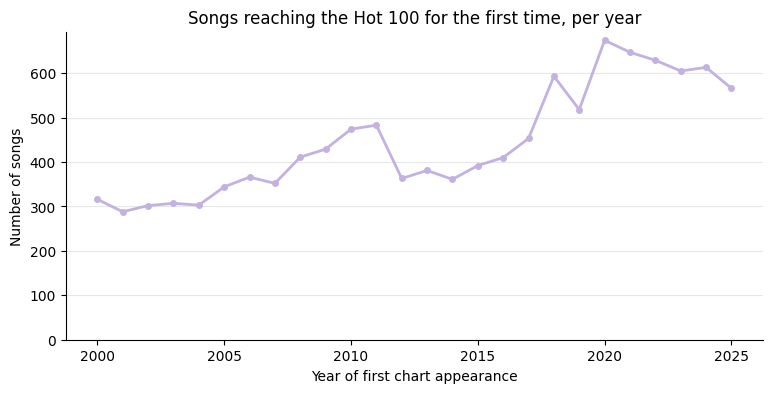

Average per year 2000–2004: 303 | 2021–2025: 612 | ratio: 2.0x


entry_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
songs,316,288,302,307,303,344,366,352,411,429,...,410,453,593,518,674,647,629,605,613,566


In [ ]:
entries_per_year = entered.groupby("entry_year").size()
DESCRIPTIVE_RESULTS["entries_per_year"] = entries_per_year.to_dict()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(entries_per_year.index, entries_per_year.values, color=COLOR_MAIN, linewidth=2, marker="o", markersize=4)
ax.set_ylim(bottom=0)
style_axes(ax, "Songs reaching the Hot 100 for the first time, per year",
           "Year of first chart appearance", "Number of songs")
save_figure(fig, "fig1_entries_per_year")
plt.show()

early = entries_per_year.loc[2000:2004].mean()
late  = entries_per_year.loc[2021:2025].mean()
print(f"Average per year 2000–2004: {early:.0f} | 2021–2025: {late:.0f} | ratio: {late / early:.1f}x")
entries_per_year.to_frame("songs").T

**Observations:** about 300 songs per year reached the chart for the first time in 2000–2004, against about 610 per year in 2021–2025 (2.0 times as many). The increase is not steady: rises in 2005–2011, a drop in 2012, and a jump in 2018–2020.

**Interpretation:** the number of slots is fixed (100 per week), so twice as many new songs means songs pass through the chart faster. The timing matches documented changes to the Hot 100 formula: digital downloads were added in 2005, on-demand streaming in 2012, YouTube views in 2013, and paid streams were weighted more heavily from 2018 (sources below). This timing is consistent with, but does not prove, an effect of these changes.

**Implication:** reaching the chart was not equally hard in every year, so any later comparison across years must take the year into account.

*Sources:* [Music Business Journal (Berklee), "Modernizing the Hot 100"](https://www.thembj.org/?p=4740); [MusicRow, 14 March 2012](https://musicrow.com/category/salesmarketing/page/86/); [heise, on YouTube and Billboard chart data](https://heise.de/-11123509).

### 7.3 When in the year do songs enter?

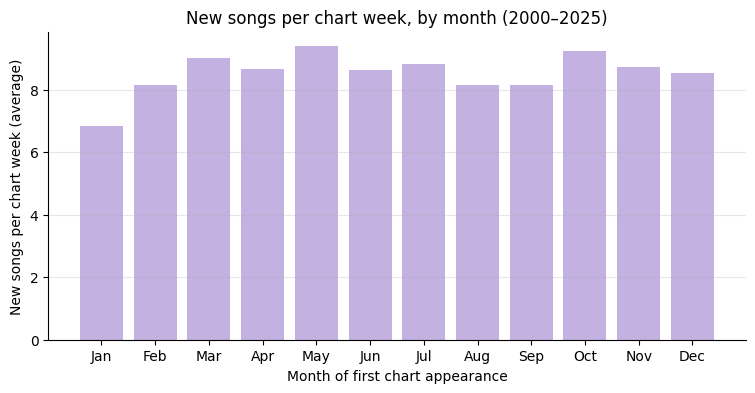

,1,2,3,4,5,6,7,8,9,10,11,12
chart weeks,114.0,105.0,116.0,112.0,114.0,112.0,115.0,115.0,112.0,114.0,112.0,116.0
new songs,779.0,857.0,1045.0,970.0,1071.0,968.0,1014.0,940.0,914.0,1053.0,977.0,992.0
per chart week,6.8,8.2,9.0,8.7,9.4,8.6,8.8,8.2,8.2,9.2,8.7,8.6


In [ ]:
chart_weeks = read_table("charts")["chart_date"]
weeks_per_month = chart_weeks.groupby(chart_weeks.dt.month).size()
entries_per_month = entered.groupby(entered["first_chart_date"].dt.month).size()
per_chart_week = entries_per_month / weeks_per_month
DESCRIPTIVE_RESULTS["new_songs_per_chart_week_by_month"] = per_chart_week.round(2).to_dict()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(per_chart_week.index, per_chart_week.values, color=COLOR_MAIN)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
style_axes(ax, "New songs per chart week, by month (2000–2025)",
           "Month of first chart appearance", "New songs per chart week (average)")
save_figure(fig, "fig2_entries_per_month")
plt.show()

pd.DataFrame({"chart weeks": weeks_per_month, "new songs": entries_per_month,
              "per chart week": per_chart_week.round(1)}).T

**Observations:** new songs enter at a similar rate throughout the year (about 8–9 per chart week), except January, which is clearly lower (6.8 per week).

**Interpretation:** a plausible explanation is that fewer songs are released around the holidays and that holiday songs occupy chart places in late December and early January; our data cannot confirm this. **Implication:** for the timing factor, the month of entry matters little except around the turn of the year.

### 7.4 How do new songs enter, and how long do they stay?

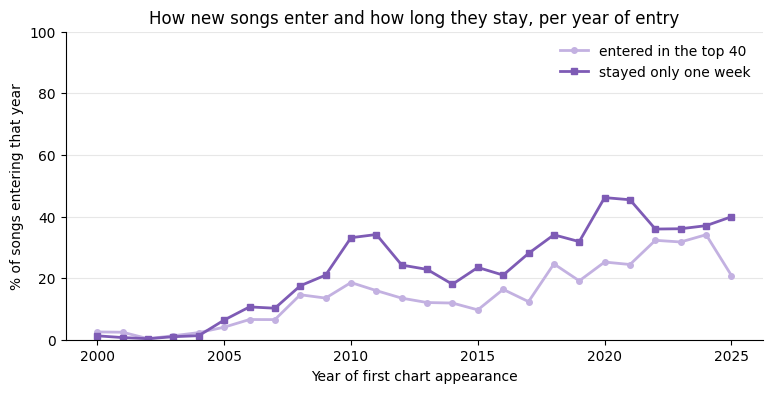

Songs entering from October 2025 (few weeks left to observe): 102


,songs,median_entry_rank,share_entered_top40,share_one_week_only,median_weeks_on_chart
entry_year,,,,,
2000,316,79.5,0.03,0.01,19.0
2001,288,77.0,0.02,0.01,20.0
2002,302,75.0,0.0,0.00,20.0
2003,307,75.0,0.01,0.01,19.0
2004,303,74.0,0.02,0.01,19.0
2005,344,91.0,0.04,0.06,16.0
2006,366,90.0,0.07,0.11,15.0
2007,352,89.0,0.07,0.10,17.0
2008,411,86.0,0.15,0.18,13.0


In [ ]:
entered["entered_top40"] = entered["entry_rank"] <= 40
entered["one_week_only"] = entered["weeks_in_window"] == 1

by_year = entered.groupby("entry_year").agg(
    songs=("song_id", "size"),
    median_entry_rank=("entry_rank", "median"),
    share_entered_top40=("entered_top40", "mean"),
    share_one_week_only=("one_week_only", "mean"),
    median_weeks_on_chart=("weeks_in_window", "median"),
)
DESCRIPTIVE_RESULTS["entry_and_longevity_by_year"] = by_year.round(3).to_dict(orient="index")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_year.index, by_year["share_entered_top40"] * 100, color=COLOR_MAIN, linewidth=2,
        marker="o", markersize=4, label="entered in the top 40")
ax.plot(by_year.index, by_year["share_one_week_only"] * 100, color=COLOR_SECOND, linewidth=2,
        marker="s", markersize=4, label="stayed only one week")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
style_axes(ax, "How new songs enter and how long they stay, per year of entry",
           "Year of first chart appearance", "% of songs entering that year")
save_figure(fig, "fig3_entry_and_longevity")
plt.show()

late_entries = int((entered["first_chart_date"] >= "2025-10-01").sum())
print(f"Songs entering from October 2025 (few weeks left to observe): {late_entries}")
by_year.round(2)

**Observations:**
- In 2000–2004, almost no new song entered in the top 40 (0–3%) or stayed only one week (≈1%); the median song stayed about 19–20 weeks.
- From 2005 both shares rise; by the 2020s about a fifth to a third of new songs enter in the top 40 (21–34%), 36–46% stay only one week, and the median song stays 2–3 weeks.
- 102 songs entered from October 2025, so 2025's one-week share is partly an effect of the window ending.

**Interpretation:** the chart changed from slow climbs (enter low, rise gradually, stay for months) to fast turnover (many songs enter high and leave quickly). The rise starts in 2005, when digital downloads were added to the Hot 100, and continues with the addition of streaming (see the sources in 7.2): these let a song's popularity register in its first week, for example when a whole album's songs chart at once (7.6). This timing is consistent with, but does not prove, such an effect.

**Implication:** "reaching the chart" means something different in 2002 and in 2022: in recent years many songs reach it for one week only.

### 7.5 Who reaches the chart?

To describe the "artist popularity" factor, we use the **lead credit**: the performer text before "Featuring" (normalised as in Section 5). For example, "Taylor Swift Featuring Ice Spice" has the lead credit "taylor swift".

**Why this definition:** "Featuring" always separates the main artist from guests, whereas "&", "x", "With" and commas also appear inside band names (Section 5.15). **Limitation:** joint credits such as "Future & Metro Boomin" count as their own lead credit, separate from each artist. MusicBrainz, which stores each credited artist separately, is used to identify individual lead artists for the comparison group (Section 10).

A song's lead credit **had charted before** if it appears on the chart before 2000 (anywhere in the raw archive, back to 1958) or with an earlier song in our window.

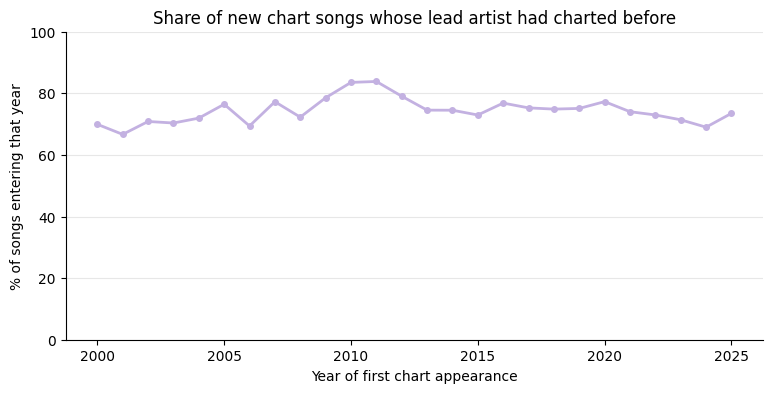

Overall: 74.5% of entering songs had a lead credit that charted before


entry_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
share,0.7,0.67,0.71,0.7,0.72,0.76,0.69,0.77,0.72,0.79,...,0.77,0.75,0.75,0.75,0.77,0.74,0.73,0.71,0.69,0.73


In [ ]:
def lead_credit(performer_text):
    """Normalised performer text before 'featuring' (the main credited artist or group)."""
    keys = make_key(performer_text)
    return keys.str.split(" featuring ", n=1).str[0].str.strip()

entered["lead_credit"] = lead_credit(entered["display_performer"])
pre_window_leads = set(lead_credit(raw_hot100.loc[raw_hot100["chart_week"] < STUDY_START, "performer"]))
first_entry_of_lead = entered.groupby("lead_credit")["first_chart_date"].transform("min")
entered["lead_charted_before"] = (entered["lead_credit"].isin(pre_window_leads)
                                  | (entered["first_chart_date"] > first_entry_of_lead))

returning_share = entered.groupby("entry_year")["lead_charted_before"].mean()
DESCRIPTIVE_RESULTS["share_from_lead_credits_that_charted_before"] = returning_share.round(3).to_dict()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(returning_share.index, returning_share.values * 100, color=COLOR_MAIN, linewidth=2, marker="o", markersize=4)
ax.set_ylim(0, 100)
style_axes(ax, "Share of new chart songs whose lead artist had charted before",
           "Year of first chart appearance", "% of songs entering that year")
save_figure(fig, "fig4_returning_artists")
plt.show()

print(f"Overall: {entered['lead_charted_before'].mean():.1%} of entering songs had a lead credit that charted before")
returning_share.round(2).to_frame("share").T

**Observations:** about three quarters (74.5%) of songs entering the chart had a lead credit that had already charted; the share is stable over time (roughly 67–84% each year).

**Interpretation:** among successful songs, most come from artists with a chart history. This does **not** show that chart history *causes* success: artists with past hits also release more songs, and we do not know how many songs by new versus established artists were released but never charted. Our comparison group cannot settle this either, because all of its artists have charted (Section 10); Section 9.7 examines instead whether established artists' songs enter the chart faster.

In [ ]:
songs_per_lead = entered.groupby("lead_credit").size().sort_values(ascending=False)
top_1pct = int(np.ceil(len(songs_per_lead) * 0.01))
concentration = {
    "lead credits with at least one entering song": len(songs_per_lead),
    "lead credits with exactly one song": int((songs_per_lead == 1).sum()),
    "share of lead credits with exactly one song": round(float((songs_per_lead == 1).mean()), 3),
    "median songs per lead credit": float(songs_per_lead.median()),
    f"share of all songs by the top 1% of lead credits ({top_1pct})":
        round(float(songs_per_lead.head(top_1pct).sum() / songs_per_lead.sum()), 3),
}
DESCRIPTIVE_RESULTS["artist_concentration"] = concentration
DESCRIPTIVE_RESULTS["top_lead_credits"] = songs_per_lead.head(10).to_dict()
display(pd.Series(concentration).to_frame("value"))
songs_per_lead.head(10).to_frame("songs")

,value
lead credits with at least one entering song,3081.000
lead credits with exactly one song,1975.000
share of lead credits with exactly one song,0.641
median songs per lead credit,1.000
share of all songs by the top 1% of lead credits (31),0.221


,songs
lead_credit,
taylor swift,268
drake,226
glee cast,205
morgan wallen,97
future,93
youngboy never broke again,88
justin bieber,88
rod wave,81
kanye west,81


**Observations:** most lead credits (64%) reached the chart with a single song, while 31 credits (1%) account for 22% of all entering songs. Glee Cast, a TV-show cast that recorded cover versions, is third with 205 songs.

**Interpretation:** chart entries are highly concentrated among a few very prolific artists. Such outliers (and special cases like Glee Cast) could dominate any analysis of artist effects, so later analyses should check whether results hold without them.

### 7.6 Weeks with many new songs

In [ ]:
entries_per_week = entered.groupby("first_chart_date").size()
busiest = entries_per_week.nlargest(10, keep="all").sort_index()   # 10 busiest weeks (+ ties), then in date order

def top_credit(week):
    """Most frequent lead credit among a week's new songs (ties broken alphabetically)."""
    counts = entered.loc[entered["first_chart_date"] == week, "lead_credit"].value_counts()
    counts = counts.sort_index().sort_values(ascending=False, kind="stable")
    return counts.index[0], int(counts.iloc[0])

busiest_table = pd.DataFrame(
    [top_credit(d) for d in busiest.index],
    index=busiest.index.strftime("%Y-%m-%d"),
    columns=["most frequent lead credit", "songs by that credit"])
busiest_table.insert(0, "new songs", busiest.values)
busiest_table.index.name = "chart date"

DESCRIPTIVE_RESULTS["new_songs_per_week"] = {"median": float(entries_per_week.median()), "max": int(entries_per_week.max())}
DESCRIPTIVE_RESULTS["busiest_weeks"] = busiest_table.reset_index().to_dict(orient="records")
print(f"New songs per chart week: median {entries_per_week.median():.0f}, max {entries_per_week.max()}")
print(f"Weeks shown: {len(busiest_table)} (the 10 busiest, plus any week tied with the 10th)")
busiest_table

New songs per chart week: median 7, max 34
Weeks shown: 11 (the 10 busiest, plus any week tied with the 10th)


,new songs,most frequent lead credit,songs by that credit
chart date,,,
2020-12-26,28,taylor swift,15
2021-11-27,34,taylor swift,26
2022-01-22,28,the weeknd,13
2022-05-21,32,bad bunny,15
2023-03-18,29,morgan wallen,27
2024-04-06,31,future and metro boomin,12
2024-05-04,33,taylor swift,31
2025-01-18,29,bad bunny,11
2025-03-29,33,playboi carti,19


**Observations:** a typical week brings 7 new songs; the 11 busiest weeks (the 10 busiest plus one tied week) bring 28–34, and all of them are from December 2020 onwards. In 6 of these 11 weeks, a single lead credit accounts for more than half of the new songs (e.g. Taylor Swift with 31 of 33 on 2024-05-04, Morgan Wallen with 29 of 31 on 2025-05-31); in the others the top credit still has 11–15 songs.

**Interpretation:** in recent years, a large part of chart entries comes in bursts when a popular artist releases an album and many of its tracks chart at once, often for a single week. This links 7.4 (one-week songs) with 7.5 (concentration), and suggests that album releases by established artists are a major route onto the chart. That none of the busiest weeks predates 2020 is consistent with the streaming-era changes described in 7.2.

**Implication:** later analyses may need to distinguish album tracks from singles (possible with MusicBrainz release information).

### 7.7 Save the descriptive results and figures

In [ ]:
import shutil

DESC_FILE = OUTPUT_DIR / "descriptive_results_billboard.json"
DESC_FILE.write_text(json.dumps({
    "record_type": "descriptive results – Billboard Hot 100 (aggregates only)",
    "source_commit": SOURCE_COMMIT,
    "computed_at_utc": datetime.now(timezone.utc).replace(microsecond=0).isoformat(),
    "songs_analysed": len(entered),
    "results": DESCRIPTIVE_RESULTS,
}, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

FIG_ZIP = shutil.make_archive(str(OUTPUT_DIR / "figures_billboard"), "zip", FIG_DIR)
download_file(DESC_FILE)
download_file(FIG_ZIP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.8 Summary of Section 7

**Observations:**
1. About twice as many songs reached the chart per year in 2021–2025 (≈610) as in 2000–2004 (≈300).
2. New songs enter at a similar rate all year, except fewer in January.
3. The chart moved from slow climbs to fast turnover: in the 2020s, a fifth to a third of new songs enter in the top 40, 36–46% stay only one week, and the median song stays 2–3 weeks (vs ≈19 weeks in the early 2000s).
4. About three quarters of entering songs come from lead credits that had charted before; 1% of lead credits account for 22% of entries.
5. All of the busiest weeks for new entries are from December 2020 onwards, and in about half of them a single artist's release accounts for most new songs.

**Interpretation:** reaching the Hot 100 became more common and more short-lived over the period, with established artists and album releases accounting for a large share of entries. The timing of these changes matches documented changes to the Hot 100 formula (downloads from 2005, streaming from 2012–2013, see 7.2).

**Limitations:**
- Only successful songs are observed, so none of these patterns identify what determines reaching the chart (selection; requires the comparison group of Sections 10–11).
- The link with Billboard's methodology changes is based on timing only; its effect is not tested here.
- Lead credits treat joint credits as separate artists.
- Entries in late 2025 have little time left in the window (right-censoring).

**Next:** add release dates, genres and artist information (Section 8), analyse when songs enter the chart (Section 9), and build a comparison group of songs that did not chart (Section 10).

## 8. Second source: MusicBrainz

### 8.1 Export the Billboard song list for matching

MusicBrainz is matched to our songs in a local PostgreSQL database built from the official MusicBrainz dump (too large for Colab). This cell exports the list of songs to look up: every printed spelling of every song (`song_names`, Section 6), so that a match can be found under any of them. The file contains Billboard titles and performers, so it is kept private and not published (Section 1.8).

In [ ]:
BB_FOR_MB_FILE = OUTPUT_DIR / "billboard_song_names.csv"
bb_for_mb = read_table("SELECT song_id, name_id, title, performer FROM song_names ORDER BY name_id")
bb_for_mb.to_csv(BB_FOR_MB_FILE, index=False)
print(f"{len(bb_for_mb):,} spellings of {bb_for_mb['song_id'].nunique():,} songs written to {BB_FOR_MB_FILE}")
download_file(BB_FOR_MB_FILE)

11,785 spellings of 11,728 songs written to outputs/billboard_song_names.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 8.2 How the MusicBrainz information was obtained

**Source.** MusicBrainz, an open music encyclopedia maintained by the non-profit MetaBrainz Foundation. MetaBrainz publishes the full database as downloadable files ("dumps") about twice a week and keeps each one for about two weeks. We used the full export **`20261017-002244`** (17 October 2026), files `mbdump.tar.bz2` (core data, CC0) and `mbdump-derived.tar.bz2` (tags, CC BY-NC-SA 3.0). Both files were verified against MusicBrainz's published SHA-256 checksums; a private copy is kept, because the dump is removed from the server after about two weeks.

**Why outside Colab.** The tables we need total about 25 GB (e.g. 58.5 million tracks, 40.6 million recordings), too large for a Colab session. They were loaded into a local PostgreSQL 18.6 database on a laptop; only the result (one row per song) is brought into this notebook.

**Steps** (scripts and full log in our MusicBrainz repository, linked in 8.3):

| Script | What it does |
|---|---|
| `mb_01_schema.sql` | Creates the 17 needed tables, with definitions copied unchanged from the official MusicBrainz schema (version 31, matching the dump) |
| `mb_02_load.sql` | Loads the dump files |
| `mb_03_indexes.sql` | Adds keys and indexes for fast joins |
| `mb_04_billboard.sql` | Loads our list of 11,785 spellings of 11,728 songs (8.1) |
| `mb_05_match.sql` | Matches songs to MusicBrainz recordings and derives release dates and genres |
| `mb_06_export.sql` | Exports one row per song |

**Matching rules (`mb_05`), and why:**
- **Same normalisation on both sides** as in Section 5 (case, apostrophes, "Feat."/"Ft.", "&", punctuation, spaces), plus accent removal (MusicBrainz writes "Beyoncé", Billboard "Beyonce").
- **Title and artist must both match** (the artist as lead credit, full credit, or any credited artist), so that covers and songs with the same title by other artists are excluded.
- **Excluded:** music videos, and versions described as live, karaoke, instrumental, demo or a cappella, which are not the charting song.
- **Fallback:** for songs without a match, titles are compared without bracketed parts (e.g. "Soak City (Do It)" vs "Soak City"); marked as such.
- **First release date:** the earliest dated release containing any matched recording, excluding bootlegs and pseudo-releases (translations). Dates may be complete or known only to the month or year; the precision is recorded.
- **Genres:** only user tags that are on MusicBrainz's official genre list and have positive votes; from the most specific level available: the recording, else the artist's own releases (never compilations), else the artist.

**Run result:** 11,224 of 11,728 songs matched (95.7%; 11,033 by exact title, 191 by the fallback); 11,190 with a release date and 11,061 with a genre. Total run time about 12 minutes.

**Reproducibility.** Re-running `run_all.sh` on the same dump reproduces the file exactly (its SHA-256 is recorded). Re-running on a later dump reproduces the method, but results may differ slightly, because MusicBrainz is continuously edited.

### 8.3 Download and verify the MusicBrainz extract

As with the Billboard archive (Section 3), the extract is downloaded from a fixed commit of a public repository and verified with its SHA-256 fingerprint, recorded when it was produced.

**Why a separate repository.** The PostgreSQL step runs outside this notebook (8.2), so its result has to be published somewhere the notebook can download it from automatically, at a fixed and verifiable version. We use a dedicated public repository, [github.com/Isabelle333/billboard-musicbrainz-extract](https://github.com/Isabelle333/billboard-musicbrainz-extract), that contains only the MusicBrainz scripts, the extracts and their run logs:
- **Reproducibility:** each extract is pinned by commit and checked by SHA-256, exactly like the Billboard archive, and the scripts that produced it sit next to it.
- **Licence:** the extract contains MusicBrainz data, including genres under CC BY-NC-SA 3.0; keeping it in its own repository keeps that licence separate from our own code and notebook, which are kept in the group's project repository (Section 1.8).
- **No chart data:** the extract contains MusicBrainz data and our own `song_id` only, so publishing it does not redistribute Billboard data (Section 1.6).

The settings are defined here rather than in Section 2.2 because they only exist after the PostgreSQL step.

In [ ]:
MB_REPO        = "Isabelle333/billboard-musicbrainz-extract"   # repository holding the extract
MB_COMMIT      = "c95bcb0ee8312c2a2145ac7bc613417ef250b74a"                 # pinned snapshot
MB_PATH        = "musicbrainz_for_billboard_songs.csv"
MB_EXPECTED_SHA256 = "a7dcab5ba6888d7a0f11da8d6b20f81fde6540f897400a9c09b3db85c3cfb3af"
MB_DUMP        = "20261017-002244"                                       # MusicBrainz full export used
MB_URL         = f"https://raw.githubusercontent.com/{MB_REPO}/{MB_COMMIT}/{MB_PATH}"

MB_ACCESS_TIME_UTC = datetime.now(timezone.utc).replace(microsecond=0)
mb_bytes = download_bytes(MB_URL)
mb_sha256 = hashlib.sha256(mb_bytes).hexdigest()
print(f"Expected SHA-256 : {MB_EXPECTED_SHA256}")
print(f"Actual SHA-256   : {mb_sha256}")
if mb_sha256 != MB_EXPECTED_SHA256:
    raise ValueError("The MusicBrainz extract is NOT the file produced by our PostgreSQL run. Stop here.")

MB_RAW_FILE = RAW_DIR / "musicbrainz_for_billboard_songs.csv"
MB_RAW_FILE.write_bytes(mb_bytes)
print(f"Integrity check passed. Saved to: {MB_RAW_FILE}")

Expected SHA-256 : a7dcab5ba6888d7a0f11da8d6b20f81fde6540f897400a9c09b3db85c3cfb3af
Actual SHA-256   : a7dcab5ba6888d7a0f11da8d6b20f81fde6540f897400a9c09b3db85c3cfb3af
Integrity check passed. Saved to: outputs/raw/musicbrainz_for_billboard_songs.csv


In [ ]:
MB_TYPES = {"song_id": str, "match_method": str, "n_matched_recordings": "Int64",
            "first_recording_mbid": str, "mb_title": str, "mb_artist_credit": str,
            "first_release_group_mbid": str, "first_release_type": str,
            "first_release_year": "Int64", "first_release_date": str, "date_precision": str,
            "genre_level": str, "top_genre": str, "top_genres_votes": str}
mb = pd.read_csv(io.BytesIO(mb_bytes), dtype=MB_TYPES, keep_default_na=False, na_values=[""])

checks = {
    "rows (expected 11,728)": len(mb),
    "columns as expected": list(mb.columns) == list(MB_TYPES),
    "song_id unique": bool(mb["song_id"].is_unique),
    "every song_id exists in our songs table": bool(mb["song_id"].isin(songs["song_id"]).all()),
    "every one of our songs present": bool(songs["song_id"].isin(mb["song_id"]).all()),
}
display(pd.Series(checks, name="value").to_frame())
if not all(v is True or v == 11728 for v in checks.values()):
    raise ValueError("The MusicBrainz extract does not line up with our songs table.")
mb.head(3)

,value
"rows (expected 11,728)",11728
columns as expected,True
song_id unique,True
every song_id exists in our songs table,True
every one of our songs present,True


,song_id,match_method,n_matched_recordings,first_recording_mbid,mb_title,mb_artist_credit,first_release_group_mbid,first_release_type,first_release_year,first_release_date,date_precision,genre_level,top_genre,top_genres_votes
0,S00001,exact title,13,fd635cea-3510-4d4b-930d-9ed69f754685,Smooth,Santana featuring Rob Thomas,70e23797-9da2-33bb-be6f-a85e7b581b69,Album,1999,1999-06-15,day,recording,rock,rock:11|classic rock:6|blues rock:5|latin:5|la...
1,S00002,exact title,35,ad661087-f3cc-4176-bbf8-cddcabba7cf6,Back at One,Brian McKnight,3d012356-745e-3665-87e3-9480a7ab4e43,Single,1999,1999-02-18,day,recording,r&b,r&b:6|soul:6|contemporary r&b:2|smooth soul:2|...
2,S00003,exact title,10,cd7b6692-fa81-4fe5-af79-0504be54d6c0,I Wanna Love You Forever,Jessica Simpson,870f7d62-486c-4321-8d00-25e79d7f4f19,Album,1997,1997,year,recording,pop,pop:4|traditional pop:2|ballad:1|pop rock:1|te...


### 8.4 Quality assessment of the MusicBrainz information

As for the Billboard data (Section 4), we assess the new information before using it: how many songs were matched and whether coverage differs over time (8.4a); how precise the release dates are and whether they are plausible compared with the chart dates (8.4b–c); a manual check of a random sample of matches against musicbrainz.org (8.4d); and the unmatched songs and genre information (8.4e).

#### 8.4a Coverage

In [ ]:
coverage = pd.DataFrame({
    "songs": mb["match_method"].value_counts(),
    "with release date": mb.dropna(subset=["first_release_year"])["match_method"].value_counts(),
    "with genre": mb.dropna(subset=["top_genre"])["match_method"].value_counts(),
}).fillna(0).astype(int)
coverage.loc["total"] = coverage.sum()
coverage["share of all songs"] = (coverage["songs"] / len(mb)).round(3)
MB_QA = {"coverage": coverage.to_dict(orient="index")}
display(coverage)

# Join contract: one MusicBrainz row and one chart summary per song.
mb_q = mb.merge(read_table("song_summary")[["song_id", "first_chart_date", "first_entry_uncertain"]],
                on="song_id", how="left", validate="one_to_one")
if len(mb_q) != len(mb) or mb_q["first_chart_date"].isna().any():
    raise ValueError("Join contract broken: a song is missing or duplicated after attaching chart dates.")
mb_q["entry_year"] = mb_q["first_chart_date"].dt.year
mb_q["period"] = pd.cut(mb_q["entry_year"], bins=[1999, 2004, 2009, 2014, 2019, 2025],
                        labels=["2000–04", "2005–09", "2010–14", "2015–19", "2020–25"])
by_period = mb_q.groupby("period", observed=True).agg(
    songs=("song_id", "size"),
    matched=("match_method", lambda m: (m != "no match").mean()),
    with_date=("first_release_year", lambda y: y.notna().mean()),
    with_genre=("top_genre", lambda g: g.notna().mean()),
).round(3)
MB_QA["coverage_by_period"] = by_period.to_dict(orient="index")
by_period

,songs,with release date,with genre,share of all songs
match_method,,,,
exact title,11033,11015,10890,0.941
no match,504,0,0,0.043
title without brackets,191,175,171,0.016
total,11728,11190,11061,1.000


,songs,matched,with_date,with_genre
period,,,,
2000–04,1614,0.976,0.973,0.965
2005–09,1902,0.971,0.963,0.960
2010–14,2071,0.970,0.966,0.948
2015–19,2385,0.964,0.963,0.948
2020–25,3756,0.931,0.929,0.919


**Observations:** 11,224 of 11,728 songs (95.7%) were matched to MusicBrainz: 11,033 by exact title and 191 by the title without brackets; 11,190 songs (95.4%) have a release date and 11,061 (94.3%) a genre. Coverage is high in every period but lower for the most recent songs: 97.6% matched in 2000–04 against 93.1% in 2020–25.

**Interpretation:** MusicBrainz is edited by volunteers, so recent songs are documented less completely, and recent hits more often have long multi-artist credits that are written differently in the two sources (see 8.4e). Analyses using MusicBrainz information therefore slightly under-represent recent songs; we report the number of songs behind every figure.

#### 8.4b Release dates

In [ ]:
precision = mb["date_precision"].value_counts(dropna=False).rename("songs").to_frame()
precision["share"] = (precision["songs"] / len(mb)).round(3)
MB_QA["date_precision"] = {str(k): int(v) for k, v in precision["songs"].items()}
display(precision)

dated = mb_q[(mb_q["date_precision"] == "day") & (~mb_q["first_entry_uncertain"])].copy()
dated["release_date"] = pd.to_datetime(dated["first_release_date"], format="%Y-%m-%d")
dated["days_release_to_chart"] = (dated["first_chart_date"] - dated["release_date"]).dt.days

timing_flags = {
    "songs with exact release date and observed first entry": len(dated),
    "release more than 7 days AFTER first chart week": int((dated["days_release_to_chart"] < -7).sum()),
    "release within 7 days after chart week (small date error or pre-release airplay)": int(dated["days_release_to_chart"].between(-7, -1).sum()),
    "release 0–365 days before first chart week": int(dated["days_release_to_chart"].between(0, 365).sum()),
    "release more than 1 year before first chart week": int((dated["days_release_to_chart"] > 365).sum()),
    "release more than 5 years before first chart week": int((dated["days_release_to_chart"] > 5 * 365).sum()),
    "median days from release to first chart week": float(dated["days_release_to_chart"].median()),
}
MB_QA["release_vs_chart_timing"] = timing_flags
pd.Series(timing_flags, name="value").to_frame()

,songs,share
date_precision,,
day,10412,0.888
NaN,538,0.046
month,429,0.037
year,349,0.030


,value
songs with exact release date and observed first entry,10306.0
release more than 7 days AFTER first chart week,399.0
release within 7 days after chart week (small date error or pre-release airplay),88.0
release 0–365 days before first chart week,9017.0
release more than 1 year before first chart week,802.0
release more than 5 years before first chart week,95.0
median days from release to first chart week,20.0


**Observations:** 88.8% of songs have an exact release date, 3.7% only a month, 3.0% only a year, and 4.6% none. Among the 10,306 songs with an exact release date and an observed first chart entry: 9,017 (87.5%) were released within a year before their first chart week; 802 more than a year before (95 of them more than five years before); 88 within a week after; and 399 (3.9%) more than a week after their first chart week, which is impossible in reality. The median time from release to first chart week is 20 days.

**Interpretation:** most release dates are consistent with the chart data, and most songs enter the chart within weeks of release, a first indication relevant to our hypothesis. Because a chart is dated after the week it measures (1.9), no song can genuinely be released after its first chart date. The 88 songs within a week are most likely small errors in the release date or radio play before the official release, so we tolerate them; the 399 cases beyond a week and the very old releases need specific treatment (8.7).

#### 8.4c Implausible release dates

In [ ]:
cols_check = ["song_id", "display_title", "display_performer", "first_chart_date",
              "mb_title", "mb_artist_credit", "first_release_date", "days_release_to_chart"]
dated_named = dated.merge(read_table("songs")[["song_id", "display_title", "display_performer"]],
                          on="song_id", how="left", validate="one_to_one")   # one name per song
display(dated_named[dated_named["days_release_to_chart"] < -7][cols_check].head(10))
dated_named[dated_named["days_release_to_chart"] > 5 * 365][cols_check].sort_values("days_release_to_chart", ascending=False).head(10)

,song_id,display_title,display_performer,first_chart_date,mb_title,mb_artist_credit,first_release_date,days_release_to_chart
33,S00143,I Need A Hot Girl,Hot Boys,2000-02-19,I Need a Hot Girl,Hot Boys feat. Big Tymers,2001-07-02,-499
51,S00167,Try Again,Aaliyah,2000-03-18,Try Again,Aaliyah,2000-03-28,-10
54,S00172,Couldn't Last A Moment,Collin Raye,2000-03-18,Couldn't Last a Moment,Collin Raye,2000-05-02,-45
92,S00223,I Hope You Dance,Lee Ann Womack,2000-05-13,I Hope You Dance,Lee Ann Womack special guest appearance Sons o...,2000-05-23,-10
97,S00228,Love Sets You Free,Kelly Price & Friends,2000-05-13,Love Sets You Free,Kelly Price & Friends,2000-06-27,-45
100,S00231,Monica,Before Dark,2000-05-20,Monica,Before Dark,2000-07-11,-52
112,S00245,When You Need My Love,Darryl Worley,2000-06-10,When You Need My Love,Darryl Worley,2000-07-18,-38
113,S00246,Doesn't Really Matter,Janet,2000-06-17,Doesn’t Really Matter (Jonathan Peters club mix),Janet,2000-08-07,-51
114,S00248,"Same Script, Different Cast",Whitney Houston & Deborah Cox,2000-06-17,"Same Script, Different Cast",Whitney Houston & Deborah Cox,2004-05-17,-1430
142,S00296,Imagine That,LL Cool J,2000-08-12,Imagine That,LL Cool J,2000-09-11,-30


,song_id,display_title,display_performer,first_chart_date,mb_title,mb_artist_credit,first_release_date,days_release_to_chart
6346,S07429,Here Comes Santa Claus (Right Down Santa Claus...,Gene Autry,2018-12-22,Here Comes Santa Claus (Right Down Santa Claus...,Gene Autry,1947-10-06,26010
6321,S07404,Rudolph The Red-Nosed Reindeer,Gene Autry,2018-12-15,Rudolph the Red‐Nosed Reindeer,Gene Autry and The Pinafores with Orchestral A...,1949-11-07,25240
6358,S07442,It's Beginning To Look A Lot Like Christmas,Perry Como And The Fontane Sisters With Mitche...,2018-12-29,It’s Beginning to Look a Lot Like Christmas,Perry Como & The Fontane Sisters with Mitchell...,1951-09-18,24574
6369,S07455,Blue Christmas,Elvis Presley,2019-01-05,Blue Christmas,Elvis Presley,1957-10-15,22362
9770,S11162,Winter Wonderland,Darlene Love,2025-01-04,Winter Wonderland,Darlene Love,1963-11-22,22324
6853,S07973,Baby It's Cold Outside,Dean Martin,2020-01-04,"Baby, It’s Cold Outside",Dean Martin,1959-11-16,21964
6323,S07406,"Let It Snow, Let It Snow, Let It Snow",Dean Martin,2018-12-15,Let It Snow! Let It Snow! Let It Snow!,Dean Martin,1959-11-16,21579
7487,S08652,Little Saint Nick,The Beach Boys,2021-01-02,Little Saint Nick,The Beach Boys,1963-11-09,20874
6360,S07446,Christmas (Baby Please Come Home),Darlene Love,2018-12-29,Christmas (Baby Please Come Home),Darlene Love,1963-11-22,20126
6347,S07430,Sleigh Ride,The Ronettes,2018-12-22,Sleigh Ride,The Ronettes,1963-11-22,20119


**Observations:** songs released "after" their first chart week fall into two groups. Some are early-2000s singles that charted on radio airplay before a commercial release (e.g. Aaliyah "Try Again", 10 days); others are matching problems where MusicBrainz's earliest known release is a later or different version (e.g. "Same Script, Different Cast" dated 2004 although it charted in 2000; Janet "Doesn't Really Matter" matched only to a club mix). Songs released more than five years before charting are almost all holiday classics from the 1940s–60s (e.g. Gene Autry, Dean Martin, The Ronettes) that entered the Hot 100 for the first time from 2018 onwards.

**Interpretation:** the first group cannot be corrected with our data; the second is a different phenomenon from new songs reaching the chart. Both are flagged rather than deleted (8.7).

#### to fill: 8.4d Manual check of 30 matches

In [ ]:
MANUAL_CHECK_SEED = 2026
matched_songs = mb[mb["match_method"] != "no match"].merge(
    read_table("songs")[["song_id", "display_title", "display_performer"]],
    on="song_id", how="left", validate="one_to_one")                  # one name per song
manual_sample = matched_songs.sample(n=30, random_state=MANUAL_CHECK_SEED)[
    ["song_id", "display_title", "display_performer", "mb_title", "mb_artist_credit",
     "first_release_date", "top_genre", "first_recording_mbid"]].copy()
manual_sample["musicbrainz_link"] = "https://musicbrainz.org/recording/" + manual_sample["first_recording_mbid"]
manual_sample = manual_sample.drop(columns="first_recording_mbid").reset_index(drop=True)
pd.set_option("display.max_colwidth", 80)
manual_sample

,song_id,display_title,display_performer,mb_title,mb_artist_credit,first_release_date,top_genre,musicbrainz_link
0,S03786,Just The Way You Are,Bruno Mars,Just the Way You Are,Bruno Mars,2010-07-20,pop,https://musicbrainz.org/recording/4658bb93-57c4-4710-86f1-b87869f5781b
1,S05511,Thinking Out Loud,Ed Sheeran,Thinking Out Loud,Ed Sheeran,2014-06-20,pop,https://musicbrainz.org/recording/cb2cc207-8125-445c-9ef9-6ea44eee959a
2,S05462,Animals,Maroon 5,Animals,Maroon 5,2014-08-25,pop,https://musicbrainz.org/recording/7c0ed007-5118-4086-917a-fd9cfb0d338e
3,S07188,Nico And The Niners,twenty one pilots,Nico and the Niners,twenty one pilots,2018-07-11,electronic,https://musicbrainz.org/recording/f5132c2a-203e-454a-9518-e994e40daf3a
4,S03737,If It's Love,Train,If It’s Love,Train,2009-10-26,pop rock,https://musicbrainz.org/recording/2bfb942f-630e-4d76-bdb4-c525675fedbe
5,S03670,Lose My Mind,Young Jeezy Featuring Plies,Lose My Mind,Young Jeezy feat. Plies,2010-03-30,hip hop,https://musicbrainz.org/recording/dffc55eb-b16e-411e-b9b4-f07b8e862401
6,S09440,Barbarian,Lil Durk,Barbarian,Lil Durk,2022-03-11,drill,https://musicbrainz.org/recording/ec136003-cbf7-4a43-b987-fbbe2065f7f1
7,S08307,Alice,Lady Gaga,Alice,Lady Gaga,2020-05-29,dance-pop,https://musicbrainz.org/recording/c1453699-ddef-4812-b110-85f70310df19
8,S02910,Paper Planes,M.I.A.,Paper Planes,M.I.A.,2007-08-08,hip hop,https://musicbrainz.org/recording/09f03130-4b30-46d8-a2cd-81f8ef9bb97b
9,S04579,Boyfriend,Justin Bieber,Boyfriend,Justin Bieber,2012-01-01,pop,https://musicbrainz.org/recording/3891874d-82cd-4ca6-bbbb-984b4f9b881d


**Manual check (30 randomly selected matches, seed 2026):** each match was opened on musicbrainz.org and checked for (1) same song and artist, (2) plausible release date, (3) sensible genre.

- Correct song and artist: [__] / 30
- Plausible release date: [__] / 30 — problems: [describe, e.g. "Justin Bieber 'Boyfriend' dated 2012-01-01, actual release March 2012"]
- Sensible genre: [__] / 30 — problems: [describe]

**Interpretation:** [e.g. "Matching is reliable (≈__% correct); release dates are mostly right, with placeholder 1 January dates as the main issue (see 8.7)."]

#### 8.4e Unmatched songs and genres

In [ ]:
unmatched = mb[mb["match_method"] == "no match"].merge(
    read_table("songs")[["song_id", "display_title", "display_performer"]],
    on="song_id", how="left", validate="one_to_one")                  # one name per song
print(f"Unmatched songs: {len(unmatched)}")
display(unmatched[["song_id", "display_title", "display_performer"]].sample(n=15, random_state=MANUAL_CHECK_SEED))

genre_levels = mb["genre_level"].value_counts(dropna=False).rename("songs").to_frame()
top_genres = mb["top_genre"].value_counts().head(20).rename("songs").to_frame()
MB_QA["genre_levels"] = {str(k): int(v) for k, v in genre_levels["songs"].items()}
MB_QA["top_genres_top20"] = top_genres["songs"].to_dict()
MB_QA["distinct_top_genres"] = int(mb["top_genre"].nunique())
print(f"Distinct top genres: {MB_QA['distinct_top_genres']}")
display(genre_levels)
top_genres

Unmatched songs: 504


,song_id,display_title,display_performer
91,S03294,Trust,Keyshia Cole Duet With Monica
134,S04697,New God Flow,Pusha T Kanye West
443,S10607,Keys To My Life,¥$: Kanye West & Ty Dolla $ign
121,S04215,Best Friend's Brother,Victorious Cast Featuring Victoria Justice
403,S10205,Rosa Pastel,Peso Pluma & Jasiel Nunez
491,S11488,Bottle Rockets,Scotty McCreery & Hootie & The Blowfish
157,S05644,Out The Speakers,A-Trak + Milo & Otis Featuring Rich Kidz
425,S10457,Worth It,Offset & Don Toliver
376,S09964,AMG,"Gabito Ballesteros, Peso Pluma & Natanael Cano"
420,S10385,Another One Of Me,"Diddy, French Montana & The Weeknd Featuring 21 Savage"


Distinct top genres: 218


,songs
genre_level,
recording,7792
release group,1804
artist,1465
NaN,667


,songs
top_genre,
hip hop,2887
pop,2150
country,1610
contemporary r&b,512
alternative rock,357
r&b,303
rock,245
contemporary country,219
trap,207


**Observations:** the 504 unmatched songs are mostly collaborations whose credits are written differently in the two sources (e.g. "Keyshia Cole Duet With Monica", "Juice WRLD x Marshmello", "Pusha T Kanye West", "¥$: Kanye West & Ty Dolla $ign") and recent songs. MusicBrainz uses 218 different genres for our songs; 7,792 genres come from the recording itself, 1,804 from the artist's release, 1,465 from the artist, and 667 songs have none.

**Interpretation:** unmatched songs are not a random 4.3%: they over-represent collaborations and recent releases, a limitation to state when using MusicBrainz information. 218 genres are far too many to compare, so they are grouped into broad families (8.7).

### 8.5 Store the MusicBrainz information in our database

The extract is added to our SQLite database (Section 6) as a new table, linked to `songs` by `song_id`, with rules that reject impossible values. All original columns are kept; problems found in 8.4 are handled in the analysis, not by changing the stored values.

In [ ]:
con.executescript("""
DROP TABLE IF EXISTS song_musicbrainz;
CREATE TABLE song_musicbrainz (
    song_id                  TEXT    PRIMARY KEY REFERENCES songs(song_id),
    match_method             TEXT    NOT NULL CHECK (match_method IN ('exact title', 'title without brackets', 'no match')),
    n_matched_recordings     INTEGER NOT NULL CHECK (n_matched_recordings >= 0),
    first_recording_mbid     TEXT,
    mb_title                 TEXT,
    mb_artist_credit         TEXT,
    first_release_group_mbid TEXT,
    first_release_type       TEXT,
    first_release_year       INTEGER CHECK (first_release_year BETWEEN 1800 AND 2026),
    first_release_date       TEXT,
    date_precision           TEXT    CHECK (date_precision IN ('day', 'month', 'year')),
    genre_level              TEXT    CHECK (genre_level IN ('recording', 'release group', 'artist')),
    top_genre                TEXT,
    top_genres_votes         TEXT,
    CHECK ((match_method = 'no match') = (n_matched_recordings = 0))
);
""")
mb.to_sql("song_musicbrainz", con, if_exists="append", index=False)
con.commit()

db_mb = {
    "rows in song_musicbrainz": q("SELECT COUNT(*) AS n FROM song_musicbrainz")["n"][0],
    "foreign-key violations": len(q("PRAGMA foreign_key_check(song_musicbrainz)")),
    "songs without a MusicBrainz row": q("""SELECT COUNT(*) AS n FROM songs s
                                           LEFT JOIN song_musicbrainz m ON m.song_id = s.song_id
                                           WHERE m.song_id IS NULL""")["n"][0],
}
MB_QA["database_checks"] = {k: int(v) for k, v in db_mb.items()}
pd.Series(db_mb, name="value").to_frame()

,value
rows in song_musicbrainz,11728
foreign-key violations,0
songs without a MusicBrainz row,0


### 8.6 Save the provenance and quality record

In [ ]:
MB_PROV_FILE = OUTPUT_DIR / "provenance_quality_musicbrainz.json"
MB_PROV_FILE.write_text(json.dumps({
    "record_type": "provenance and quality assessment – MusicBrainz information for Billboard songs",
    "musicbrainz_dump": MB_DUMP,
    "export_repository": f"https://github.com/{MB_REPO}",
    "export_commit": MB_COMMIT,
    "export_url": MB_URL,
    "export_sha256": mb_sha256,
    "accessed_at_utc": MB_ACCESS_TIME_UTC.isoformat(),
    "manual_check_seed": MANUAL_CHECK_SEED,
    "results": MB_QA,
}, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
download_file(MB_PROV_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 8.7 Cleaning the MusicBrainz information

Based on 8.4, we clean the MusicBrainz information in four logged steps (M1–M4, "M" for MusicBrainz, like C1–C12 in Section 5). As before, the stored original values are not changed: the cleaned values go into a separate table, `song_mb_clean`.

| Step | What | Responds to |
|---|---|---|
| M1 | Exact dates on 1 January treated as known to the year only | placeholder dates (8.4d) |
| M2 | Flag songs released more than 7 days after their first chart week | impossible timing (8.4b–c) |
| M3 | Flag songs released more than 5 years before their first chart week | old songs charting late (8.4c) |
| M4 | Group the 218 genres into 10 broad families | too many genres (8.4e) |

In [ ]:
MB_CLEANING_LOG = []

def log_mb_step(step, description, values_changed, justification):
    """Record one MusicBrainz cleaning step (same idea as log_step in Section 5)."""
    MB_CLEANING_LOG.append({"step": step, "description": description,
                            "values_changed": int(values_changed), "justification": justification})
    print(f"[{step}] {description} | values changed: {values_changed:,}")

mb_raw = read_table("SELECT * FROM song_musicbrainz")
mbc = mb_raw.merge(read_table("song_summary")[["song_id", "first_chart_date", "first_entry_uncertain"]],
                   on="song_id", how="left", validate="one_to_one")   # contract: one partner per song
if len(mbc) != len(mb_raw) or mbc["first_chart_date"].isna().any():
    raise ValueError("Join contract broken: a song is missing or duplicated after attaching chart dates.")

day_dates = mbc["date_precision"] == "day"
jan_first = day_dates & mbc["first_release_date"].str.endswith("-01-01", na=False)
expected_jan_first = day_dates.sum() / 365.25
print(f"Exact dates on 1 January: {int(jan_first.sum())} "
      f"(about {expected_jan_first:.0f} expected if release dates were spread evenly over the year)")

Exact dates on 1 January: 236 (about 29 expected if release dates were spread evenly over the year)


In [ ]:
# M1: 1 January dates count as "year only"; only reliable exact dates get a release_date
mbc["release_date"] = pd.to_datetime(mbc["first_release_date"].where(day_dates & ~jan_first), format="%Y-%m-%d")
mbc["release_precision"] = mbc["date_precision"].where(~jan_first, "year")
log_mb_step("M1", "Treat exact dates on 1 January as known to the year only", jan_first.sum(),
            f"{int(jan_first.sum())} dates fall on 1 January, about {jan_first.sum() / expected_jan_first:.0f} times "
            "more than expected; most are placeholders for 'released that year'.")

# M2: impossible timing
mbc["days_release_to_chart"] = (mbc["first_chart_date"] - mbc["release_date"]).dt.days
after_chart = mbc["days_release_to_chart"] < -7
mbc["flag_release_after_chart"] = after_chart
log_mb_step("M2", "Flag songs whose earliest known release is more than 7 days after their first chart week",
            after_chart.sum(), "A song cannot chart before it exists: MusicBrainz lacks the earliest release "
            "(e.g. radio-only singles) or the match is wrong. Kept, but excluded from time-to-chart analyses.")

# M3: old songs charting decades later
old_release = mbc["days_release_to_chart"] > 5 * 365
mbc["flag_old_song"] = old_release
log_mb_step("M3", "Flag songs first released more than 5 years before their first chart week",
            old_release.sum(), "Mostly old holiday classics and revivals entering the chart decades later; a "
            "different phenomenon from new releases, analysed separately.")

usable = (mbc["days_release_to_chart"].notna() & ~after_chart & ~old_release & ~mbc["first_entry_uncertain"])
pd.Series({"release after chart (M2)": int(after_chart.sum()),
           "old songs (M3)": int(old_release.sum()),
           "usable for time-to-chart analysis": int(usable.sum())}, name="songs").to_frame()

[M1] Treat exact dates on 1 January as known to the year only | values changed: 236
[M2] Flag songs whose earliest known release is more than 7 days after their first chart week | values changed: 399
[M3] Flag songs first released more than 5 years before their first chart week | values changed: 118


,songs
release after chart (M2),399
old songs (M3),118
usable for time-to-chart analysis,9589


In [ ]:
GENRE_FAMILY_RULES = [   # checked in this order; the first rule with a keyword found in the genre name wins
    ("Holiday",            ["christmas", "holiday"]),
    ("Latin",              ["latin", "reggaeton", "corrido", "bachata", "salsa", "cumbia", "banda",
                            "norteño", "regional mexican", "dembow", "mariachi", "urbano", "bolero"]),
    ("Hip hop / rap",      ["hip hop", "rap", "trap", "drill", "crunk", "dirty south", "grime",
                            "bounce", "phonk", "boom bap", "g-funk", "chipmunk soul"]),
    ("Country",            ["country", "bluegrass", "americana"]),
    ("R&B / soul",         ["r&b", "soul", "funk", "new jack swing", "quiet storm"]),
    ("Other",              ["dancehall", "reggae", "afrobeat"]),
    ("Pop",                ["indie pop", "alternative pop", "art pop", "dream pop", "bedroom pop"]),
    ("Rock / alternative", ["rock", "metal", "punk", "emo", "grunge", "indie", "alternative",
                            "post-hardcore", "new wave", "industrial", "aor"]),
    ("Pop",                ["pop", "ballad", "boy band", "girl group"]),
    ("Electronic / dance", ["electro", "house", "dance", "edm", "techno", "trance", "dubstep", "brostep",
                            "disco", "drum and bass", "club", "big beat", "downtempo", "ambient"]),
]

def genre_family(genre):
    """Broad family of a detailed MusicBrainz genre (first matching rule wins; otherwise 'Other')."""
    if pd.isna(genre):
        return pd.NA
    for family, keywords in GENRE_FAMILY_RULES:
        if any(k in genre for k in keywords):
            return family
    return "Other"

mbc["genre_family"] = mbc["top_genre"].map(genre_family)
log_mb_step("M4", "Group the detailed genres into broad families", mbc["top_genre"].notna().sum(),
            f"{mbc['top_genre'].nunique()} distinct genres are too many to compare; keyword rules in a fixed "
            "order assign each to one of 10 families (full mapping saved).")

genre_map = (mbc.dropna(subset=["top_genre"]).groupby(["genre_family", "top_genre"]).size()
             .rename("songs").reset_index().sort_values(["genre_family", "songs"], ascending=[True, False]))
family_counts = mbc["genre_family"].value_counts(dropna=False).rename("songs").to_frame()
family_counts["share"] = (family_counts["songs"] / len(mbc)).round(3)
display(family_counts)
genre_map.groupby("genre_family").head(6)

[M4] Group the detailed genres into broad families | values changed: 11,061


,songs,share
genre_family,,
Hip hop / rap,3577,0.305
Pop,2603,0.222
Country,1914,0.163
R&B / soul,1045,0.089
Rock / alternative,987,0.084
<NA>,667,0.057
Electronic / dance,324,0.028
Other,316,0.027
Latin,234,0.020


,genre_family,top_genre,songs
5,Country,country,1610
4,Country,contemporary country,219
6,Country,country pop,29
7,Country,country rock,23
2,Country,bro-country,11
0,Country,alternative country,10
22,Electronic / dance,electronic,125
14,Electronic / dance,dance,51
29,Electronic / dance,house,47
21,Electronic / dance,electro house,16


In [ ]:
song_mb_clean = mbc[["song_id", "release_date", "release_precision", "days_release_to_chart",
                     "flag_release_after_chart", "flag_old_song", "genre_family"]].copy()
con.executescript("""
DROP TABLE IF EXISTS song_mb_clean;
CREATE TABLE song_mb_clean (
    song_id                  TEXT    PRIMARY KEY REFERENCES songs(song_id),
    release_date             TEXT,
    release_precision        TEXT    CHECK (release_precision IN ('day', 'month', 'year')),
    days_release_to_chart    INTEGER,
    flag_release_after_chart INTEGER NOT NULL CHECK (flag_release_after_chart IN (0, 1)),
    flag_old_song            INTEGER NOT NULL CHECK (flag_old_song IN (0, 1)),
    genre_family             TEXT
);
""")
to_sql_ready(song_mb_clean).to_sql("song_mb_clean", con, if_exists="append", index=False)
con.commit()

GENRE_MAP_FILE = OUTPUT_DIR / "genre_family_mapping.csv"
genre_map.to_csv(GENRE_MAP_FILE, index=False)
MB_CLEAN_LOG_FILE = OUTPUT_DIR / "cleaning_log_musicbrainz.json"
MB_CLEAN_LOG_FILE.write_text(json.dumps({
    "record_type": "cleaning log – MusicBrainz information",
    "export_sha256": mb_sha256,
    "cleaned_at_utc": datetime.now(timezone.utc).replace(microsecond=0).isoformat(),
    "steps": MB_CLEANING_LOG,
    "genre_family_rules": GENRE_FAMILY_RULES,
    "genre_family_counts": {str(k): int(v) for k, v in family_counts["songs"].items()},
}, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
download_file(MB_CLEAN_LOG_FILE)
download_file(GENRE_MAP_FILE)

q("""SELECT COUNT(*) AS songs, SUM(release_date IS NOT NULL) AS with_exact_date,
            SUM(flag_release_after_chart) AS release_after_chart, SUM(flag_old_song) AS old_songs,
            SUM(genre_family IS NOT NULL) AS with_genre_family
     FROM song_mb_clean""")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,songs,with_exact_date,release_after_chart,old_songs,with_genre_family
0,11728,10176,399,118,11061


### 8.8 Summary of Section 8

**Observations:** MusicBrainz information was obtained for 95.7% of the charting songs (95.4% with a release date, 94.3% with a genre) from the official dump of 17 October 2026, through a documented PostgreSQL process (8.2) and a verified, published extract (8.3). After cleaning, 10,176 songs have a reliable exact release date and 9,589 can be used for time-to-chart analysis; 399 songs have an impossible release date and 118 are old songs that charted decades later (both flagged); the 218 genres are grouped into 10 families.

**Interpretation:** the matched information is complete and consistent enough for the planned analyses, with three limitations: coverage is lower for recent songs and collaborations; about 4% of release dates are implausible and excluded from timing analyses; genres come from volunteer tags and for some songs only from the artist, not the song itself.

## 9. When do songs reach the chart?

This section tests our hypothesis (Section 1): most songs that reach the Hot 100 do so soon after release, and beyond a certain time a song becomes much less likely to enter.

**Rules used throughout:** release dates from the cleaned MusicBrainz table (8.7); songs grouped by release year; every song is followed for the same fixed number of charts; medians with the 25th–75th percentiles; the number of songs shown for every figure.

### 9.1 How to measure time to chart

**First approach.** In 8.4 and 8.7 we measured time to chart in days, from the release date to the first chart date (`days_release_to_chart`, median 20 days). Before using it to test our hypothesis, we checked that one day means the same thing in every year. If it does, songs released on the same weekday should show the same typical gap in every period. We compare the most common gap for the three most frequent release weekdays, grouped by the chart rules in force when the song entered (A, B, C: explained below).

In [ ]:
timing = read_table("song_mb_clean").merge(
    read_table("song_summary")[["song_id", "first_chart_date", "first_entry_uncertain"]],
    on="song_id", how="left", validate="one_to_one")
timing = timing[timing["release_date"].notna() & ~timing["flag_release_after_chart"]
                & ~timing["flag_old_song"] & ~timing["first_entry_uncertain"]].copy()

entry_date = timing["first_chart_date"]
timing["chart rules at entry"] = np.select(
    [entry_date < pd.Timestamp("2015-07-25"), entry_date < pd.Timestamp("2018-01-06")],
    ["A: to Jul 2015", "B: Jul 2015 – Dec 2017"], default="C: from Jan 2018")
timing["release weekday"] = timing["release_date"].dt.day_name()

def most_common_gap(days):
    """Most frequent number of days from release to first chart entry, and how many songs have it."""
    mode = days.mode().iloc[0]
    return pd.Series({"songs": len(days), "most common gap (days)": int(mode),
                      "songs with that gap": int((days == mode).sum())})

gap_table = (timing[timing["release weekday"].isin(["Monday", "Tuesday", "Friday"])]
             .groupby(["chart rules at entry", "release weekday"])["days_release_to_chart"]
             .apply(most_common_gap).unstack())
display(gap_table)

songs  most common gap (days)  \
chart rules at entry   release weekday                                  
A: to Jul 2015         Friday             617                      22   
                       Monday             843                      19   
                       Tuesday           2049                      18   
B: Jul 2015 – Dec 2017 Friday             542                      22   
                       Monday              43                      26   
                       Tuesday            100                      18   
C: from Jan 2018       Friday            3223                      15   
                       Monday             114                      12   
                       Tuesday            113                      18   

                                        songs with that gap  
chart rules at entry   release weekday                       
A: to Jul 2015         Friday                           130  
                       Monday                           262  
                       Tuesday                          546  
B: Jul 2015 – Dec 2017 Friday                           284  
                       Monday                            10  
                       Tuesday                           21  
C: from Jan 2018       Friday                          2560  
                       Monday                            46  
                       Tuesday                           49

**Observations:** the typical gap depends on the period, not only on the song. Friday releases most often entered 22 days after release up to the end of 2017, but 15 days from 2018 (3,223 songs; 2,560 of them at exactly 15 days). Before July 2015, Tuesday releases (then the usual US release day) most often entered after 18 days and Monday releases after 19.

**Explanation:** each chart counts a *tracking week* that ends some days before the date printed on the chart, and Billboard changed these rules twice in our period:

| Rules | Charts dated | Tracking week | Chart dated … after the tracking week ends |
|---|---|---|---|
| A | before 25 July 2015 | Monday–Sunday | 13 days |
| B | 25 July 2015 – 30 December 2017 | Friday–Thursday | 16 days |
| C | from 6 January 2018 | Friday–Thursday | 9 days |

Under rules A, a Tuesday release counts from that week's Sunday (+5 days), and its chart is dated 13 days later: 18 days. Under B and C, Friday releases have the same tracking week, but in 2018 Billboard moved chart dates one week earlier, so the same situation is 22 days under B and 15 days under C. This re-dating also explains the irregular 2018-01-06 chart found in 4.7c.

**Decision:** we do not measure time to chart in days, because 22 days meant "the first chart the song could enter" in 2016 but "the second" in 2020; songs released before 2018 would look one week slower for purely administrative reasons. Instead, for each song we find its **first possible chart** (the first chart whose tracking week ends on or after the release date) and count **how many charts it waited** after that (0 = it entered on its first possible chart). This measure means the same in every year.

*Sources:* [AOL/Billboard, "Billboard to alter chart tracking week for global release date" (2015)](https://www.aol.com/billboard-alter-chart-tracking-week-080000277.html); [Hypebot, "Billboard shifts magazine, chart dates to reflect actual release week" (2017)](https://www.hypebot.com/billboard-shifts-magazine-chart-dates-to-reflect-actual-relkease-week).

### 9.2 How soon after release do charting songs enter?

In [ ]:
ANALYSIS_RESULTS = {}

# When could a song first have charted? Each chart counts a "tracking week" that ends some days before
# the date printed on the chart. Billboard changed this twice in our period (sources in the text above):
#   charts dated before 2015-07-25: Monday–Sunday tracking week, chart dated 13 days after it ends;
#   2015-07-25 to 2017-12-30:       Friday–Thursday tracking week, chart dated 16 days after it ends;
#   from 2018-01-06:                Friday–Thursday tracking week, chart dated 9 days after it ends.
TRACKING_RULES = [(pd.Timestamp("2015-07-25"), 13), (pd.Timestamp("2018-01-06"), 16), (pd.Timestamp.max, 9)]
FOLLOW_UP_CHARTS = 52                          # fixed observation window: 52 weekly charts (one year)

def days_after_tracking_end(chart_date):
    """Days between the end of a chart's tracking week and the date printed on the chart."""
    for dated_before, lag in TRACKING_RULES:
        if chart_date < dated_before:
            return lag

chart_dates = read_table("charts")["chart_date"].sort_values().reset_index(drop=True)
tracking_end = chart_dates - pd.to_timedelta(chart_dates.map(days_after_tracking_end), unit="D")
if not tracking_end.is_monotonic_increasing:
    raise ValueError("Tracking-week ends are not in order – check TRACKING_RULES.")
chart_position = pd.Series(range(len(chart_dates)), index=chart_dates)   # chart date -> 0, 1, 2, ...

songs_ttc = read_table("song_mb_clean").merge(
    read_table("song_summary")[["song_id", "display_title", "display_performer", "first_chart_date", "first_entry_uncertain"]],
    on="song_id", how="left", validate="one_to_one")
if len(songs_ttc) != len(read_table("songs")) or songs_ttc["first_chart_date"].isna().any():
    raise ValueError("Join contract broken: a song is missing or duplicated.")

dated = songs_ttc["release_date"].notna()
songs_ttc["first_possible_pos"] = pd.Series(
    np.searchsorted(tracking_end.values, songs_ttc["release_date"].values, side="left"), index=songs_ttc.index).where(dated)
songs_ttc["entry_pos"] = songs_ttc["first_chart_date"].map(chart_position)
songs_ttc["charts_waited"] = (songs_ttc["entry_pos"] - songs_ttc["first_possible_pos"]).astype("Int64")
songs_ttc["release_year"] = songs_ttc["release_date"].dt.year.astype("Int64")

# Selection ledger: every filter, with the number of songs left and the reason.
last_pos = len(chart_dates) - 1
steps = [
    ("all charting songs", pd.Series(True, index=songs_ttc.index), "Section 6 database"),
    ("reliable exact release date", dated, "M1: no date, month/year only, or 1 January placeholder"),
    ("release not after first chart week", ~songs_ttc["flag_release_after_chart"], "M2: impossible timing"),
    ("not an old song charting much later", ~songs_ttc["flag_old_song"], "M3: different phenomenon"),
    ("first chart entry observed", ~songs_ttc["first_entry_uncertain"], "first entry may lie before 2000"),
    ("released 2000 or later", songs_ttc["release_year"] >= 2000,
     "same release years as the comparison group; earlier songs may have had chances before our data starts"),
    (f"full {FOLLOW_UP_CHARTS}-chart window inside our data",
     songs_ttc["first_possible_pos"] + FOLLOW_UP_CHARTS - 1 <= last_pos,
     "every song gets the same chance to be seen entering: excludes releases from about December 2024"),
]
keep = pd.Series(True, index=songs_ttc.index)
ledger = []
for label, condition, reason in steps:
    keep &= condition.fillna(False).astype(bool)
    ledger.append({"filter": label, "songs left": int(keep.sum()), "reason": reason})
ttc = songs_ttc[keep].copy()
ttc["waited"] = ttc["charts_waited"].clip(lower=0).astype(int)   # entries before the first possible chart count as 0
ttc_ledger = pd.DataFrame(ledger)
ANALYSIS_RESULTS["selection_ledger"] = ttc_ledger.to_dict("records")
print(f"Release years covered: {ttc['release_year'].min()}–{ttc['release_year'].max()}")
display(ttc_ledger)

Release years covered: 2000–2024


,filter,songs left,reason
0,all charting songs,11728,Section 6 database
1,reliable exact release date,10176,"M1: no date, month/year only, or 1 January placeholder"
2,release not after first chart week,9777,M2: impossible timing
3,not an old song charting much later,9659,M3: different phenomenon
4,first chart entry observed,9589,first entry may lie before 2000
5,released 2000 or later,9466,same release years as the comparison group; earlier songs may have had chanc...
6,full 52-chart window inside our data,9007,every song gets the same chance to be seen entering: excludes releases from ...


Songs with a full 5-year window: 6,813 (released 2000–2020)


,songs,share,cumulative share
entered on,,,
1st possible chart (or earlier),2590,0.380,0.380
2nd–4th chart,1096,0.161,0.541
5th–13th chart,955,0.140,0.681
14th–26th chart,831,0.122,0.803
27th–52nd chart,799,0.117,0.920
53rd–260th chart,542,0.080,1.000


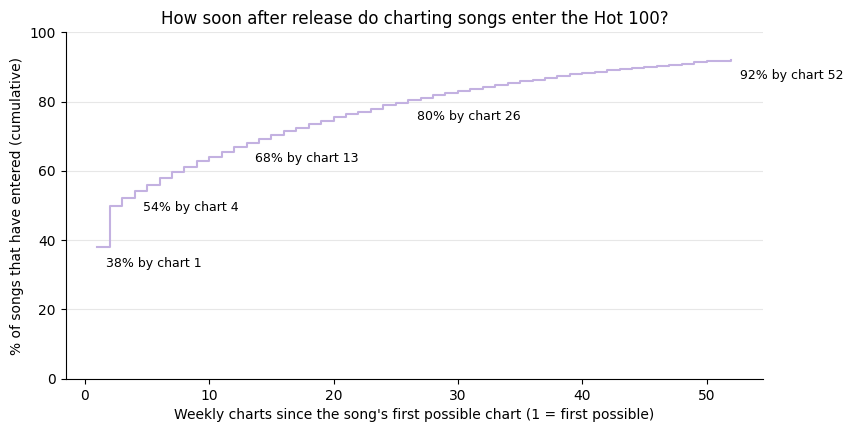

In [ ]:
LONG_FOLLOW_UP = 260                                   # 5 years of weekly charts, the same limit as M3
long_term = ttc[ttc["first_possible_pos"] + LONG_FOLLOW_UP - 1 <= last_pos]
print(f"Songs with a full 5-year window: {len(long_term):,} (released "
      f"{long_term['release_year'].min()}–{long_term['release_year'].max()})")

WAIT_BINS   = [-1, 0, 3, 12, 25, 51, LONG_FOLLOW_UP]   # charts waited; each bin includes its right edge
WAIT_LABELS = ["1st possible chart (or earlier)", "2nd–4th chart", "5th–13th chart",
               "14th–26th chart", "27th–52nd chart", "53rd–260th chart"]
wait_table = (pd.cut(long_term["waited"], WAIT_BINS, labels=WAIT_LABELS)
              .value_counts(sort=False).rename("songs").rename_axis("entered on").to_frame())
wait_table["share"] = (wait_table["songs"] / len(long_term)).round(3)
wait_table["cumulative share"] = (wait_table["songs"].cumsum() / len(long_term)).round(3)
ANALYSIS_RESULTS["wait_distribution_5y"] = wait_table.reset_index().astype({"entered on": str}).to_dict("records")
display(wait_table)

cumulative = pd.Series([(long_term["waited"] < k).mean() for k in range(1, FOLLOW_UP_CHARTS + 1)],
                       index=range(1, FOLLOW_UP_CHARTS + 1))
ANALYSIS_RESULTS["cumulative_share_by_chart_5y"] = {int(k): round(float(v), 3) for k, v in cumulative[[1, 2, 4, 13, 26, 52]].items()}

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.step(cumulative.index, cumulative.values * 100, where="post", color=COLOR_MAIN)
for k in [1, 4, 13, 26, 52]:
    ax.annotate(f"{cumulative[k] * 100:.0f}% by chart {k}", (k, cumulative[k] * 100),
                textcoords="offset points", xytext=(6, -14), fontsize=9)
ax.set_ylim(0, 100)
style_axes(ax, "How soon after release do charting songs enter the Hot 100?",
           "Weekly charts since the song's first possible chart (1 = first possible)",
           "% of songs that have entered (cumulative)")
save_figure(fig, "9_2_cumulative_entry")
plt.show()

**Observations:** we followed 6,813 charting songs released in 2000–2020 for five years after their first possible chart. 38% entered on the very first chart they could have entered, 54% within four charts (about a month), 80% within 26 charts (six months) and 92% within a year; 8% entered between one and five years after release.

**Interpretation:** consistent with our hypothesis, most charting songs enter soon after release. A minority enter much later; part of this may be measurement rather than behaviour, because MusicBrainz gives the first release of the *recording*, often the album, while a song may only have been promoted as a single months later.

### 9.3 Has the speed of entry changed over time?

Songs entering within 52 charts of their first possible chart: 8,416 (of 9,007; 591 entered later)


,songs,median charts waited,25th pct,75th pct,% on 1st possible chart,% within 4 charts
period,,,,,,
2000–04,736,14.0,4.0,27.25,13.9,22.7
2005–09,1269,5.0,0.0,19.00,28.5,46.0
2010–14,1635,1.0,0.0,13.00,44.2,59.3
2015–19,2015,1.0,0.0,5.00,49.7,72.5
2020–24,2761,0.0,0.0,1.00,69.6,85.5


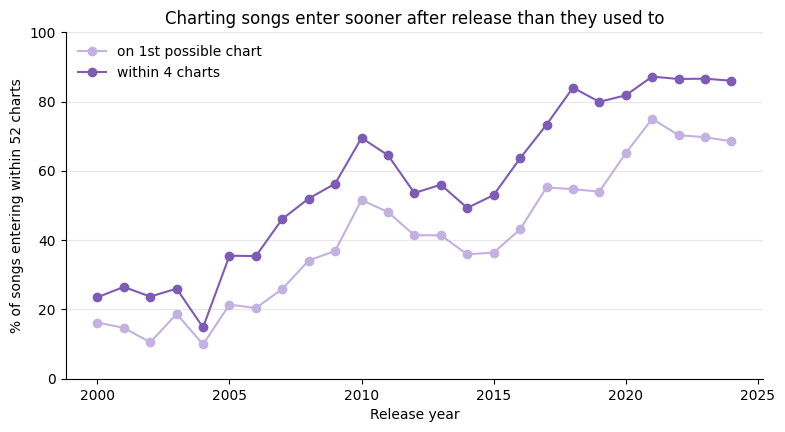

In [ ]:
in_window = ttc[ttc["waited"] < FOLLOW_UP_CHARTS].assign(
    period=lambda d: pd.cut(d["release_year"].astype(int), [1999, 2004, 2009, 2014, 2019, 2024],
                            labels=["2000–04", "2005–09", "2010–14", "2015–19", "2020–24"]))
print(f"Songs entering within {FOLLOW_UP_CHARTS} charts of their first possible chart: {len(in_window):,} "
      f"(of {len(ttc):,}; {len(ttc) - len(in_window):,} entered later)")

def timing_summary(group):
    """Size, median and spread of charts waited, and the share entering early, for one group of songs."""
    w = group["waited"]
    return pd.Series({"songs": len(w), "median charts waited": w.median(),
                      "25th pct": w.quantile(.25), "75th pct": w.quantile(.75),
                      "% on 1st possible chart": round((w == 0).mean() * 100, 1),
                      "% within 4 charts": round((w <= 3).mean() * 100, 1)})

by_period = in_window.groupby("period", observed=True)[["waited"]].apply(timing_summary).astype({"songs": int})
by_year = in_window.groupby("release_year")[["waited"]].apply(timing_summary).astype({"songs": int})
ANALYSIS_RESULTS["timing_by_period"] = by_period.reset_index().astype({"period": str}).to_dict("records")
ANALYSIS_RESULTS["timing_by_release_year"] = by_year.reset_index().to_dict("records")
display(by_period)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(by_year.index, by_year["% on 1st possible chart"], marker="o", color=COLOR_MAIN, label="on 1st possible chart")
ax.plot(by_year.index, by_year["% within 4 charts"], marker="o", color=COLOR_SECOND, label="within 4 charts")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
style_axes(ax, "Charting songs enter sooner after release than they used to",
           "Release year", f"% of songs entering within {FOLLOW_UP_CHARTS} charts")
save_figure(fig, "9_3_speed_by_release_year")
plt.show()

**Observations:** among songs entering within a year, the median wait fell from 14 charts for songs released in 2000–2004 to 0 for 2020–2024: the share entering on the first possible chart rose from 14% to 70%, and the share entering within four charts from 23% to 86%. The rise is not steady: it peaks in 2010 (52% on the first chart), dips in 2012–2015 (36–41%), then rises again from 2016.

**Interpretation:** a song's first weeks after release have become much more decisive. The timing matches the changes to the Hot 100 formula described in 7.2: downloads (2005) and streaming (from 2012, weighted more from 2018) are counted from release day, whereas in the early 2000s songs typically built up radio airplay over weeks. This is consistent with, but does not prove, an effect of these changes. It also matches 7.4 (more new songs entering high, more songs lasting one week).

### 9.4 Is there a threshold after which songs rarely enter?

9.2 shows *how many* songs entered by each chart. To test for a threshold, we ask a different question for each chart *k*: **of the songs that had not entered yet, what share entered at chart *k*?** (the "entry rate"). A threshold would appear as a sharp drop in this rate. We use the 6,813 songs followed for five years, so that songs entering after a year are still counted among those "not entered yet".

,chart,songs not yet entered,entered at this chart,entry rate
0,1,6813,2590,0.380
1,2,4223,807,0.191
2,3,3416,164,0.048
3,4,3252,125,0.038
4,5,3127,122,0.039
5,6,3005,132,0.044
6,7,2873,119,0.041
7,8,2754,109,0.040


Average entry rate, charts 3–13: 0.040; charts 14–52: 0.035


,songs,chart 1,chart 2,chart 3,chart 4,chart 5,chart 6
period,,,,,,,
2000–04,853,0.120,0.031,0.034,0.024,0.026,0.024
2005–09,1412,0.256,0.114,0.057,0.056,0.041,0.044
2010–14,1753,0.412,0.169,0.047,0.040,0.036,0.049
2015–19,2157,0.465,0.345,0.049,0.032,0.053,0.047


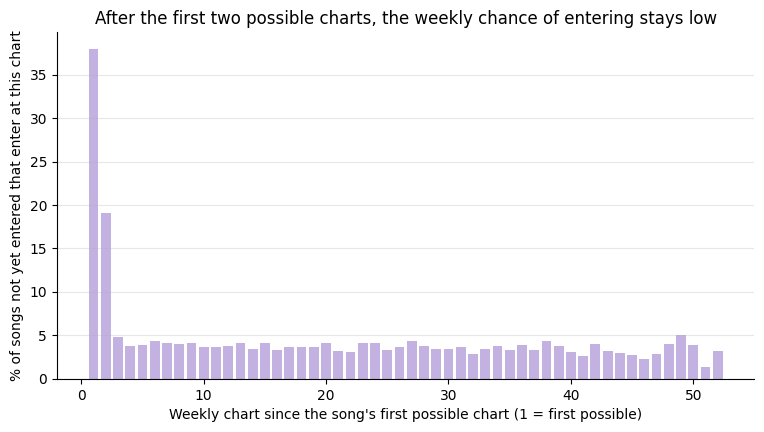

In [ ]:
def entry_rates(waited, charts):
    """For each chart k: of the songs that had not entered before chart k, the share entering at chart k."""
    not_yet = np.array([(waited >= k).sum() for k in range(charts)])
    entering = np.array([(waited == k).sum() for k in range(charts)])
    return pd.DataFrame({"chart": range(1, charts + 1), "songs not yet entered": not_yet,
                         "entered at this chart": entering, "entry rate": (entering / not_yet).round(3)})

entry_rate = entry_rates(long_term["waited"], FOLLOW_UP_CHARTS)
ANALYSIS_RESULTS["entry_rate_by_chart_5y"] = entry_rate.to_dict("records")
display(entry_rate.head(8))
print(f"Average entry rate, charts 3–13: {entry_rate.loc[2:12, 'entry rate'].mean():.3f}; "
      f"charts 14–52: {entry_rate.loc[13:, 'entry rate'].mean():.3f}")

long_periods = long_term[long_term["release_year"] <= 2019].assign(
    period=lambda d: pd.cut(d["release_year"].astype(int), [1999, 2004, 2009, 2014, 2019],
                            labels=["2000–04", "2005–09", "2010–14", "2015–19"]))
rate_by_period = (long_periods.groupby("period", observed=True)["waited"]
                  .apply(lambda w: entry_rates(w, 6).set_index("chart")["entry rate"])
                  .unstack().rename(columns=lambda k: f"chart {k}").rename_axis(columns=None))
rate_by_period.insert(0, "songs", long_periods.groupby("period", observed=True).size())
ANALYSIS_RESULTS["entry_rate_by_period_5y"] = rate_by_period.reset_index().astype({"period": str}).to_dict("records")
display(rate_by_period)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(entry_rate["chart"], entry_rate["entry rate"] * 100, color=COLOR_MAIN)
style_axes(ax, "After the first two possible charts, the weekly chance of entering stays low",
           "Weekly chart since the song's first possible chart (1 = first possible)",
           "% of songs not yet entered that enter at this chart")
save_figure(fig, "9_4_entry_rate")
plt.show()

**Observations:** of the songs that had not entered yet, 38% entered on the first possible chart and 19% on the second; from the third chart onwards the rate falls to about 4% per chart and stays at that level for the rest of the year (4.0% on average for charts 3–13, 3.5% for charts 14–52). The rate on the first chart rose from 12% for songs released in 2000–2004 to 47% in 2015–2019; in 2000–2004, the rate was low from the start (3–4% from the second chart).

**Interpretation:** the data show a clear threshold after the first two possible charts: a song that has not entered by then is about five to ten times less likely to enter in any given later week. The second chart is still high partly because some releases only had a few days in their first tracking week (e.g. Thursday releases since 2015). After the threshold the chance does not fall further but stays low and roughly constant: a steady trickle of "slow-burning" songs. The threshold has become sharper over time: in the early 2000s it was much weaker, because only 12% of songs entered on their first possible chart and most charting songs entered gradually over the following months.

**Limitation:** all these songs eventually charted, so the analysis shows *when* charting songs enter, not how likely *any* song is to chart. That requires songs that never charted: the comparison group (Section 10), analysed in Section 11.

### 9.5 Does the speed of entry differ by genre?

We compare the genre families from 8.7 (M4). Because the genre mix of the chart changed strongly over time (7.2) and entry became faster over time (9.3), a difference between genres could simply reflect *when* their songs were released. We therefore also compare genres **within each release period**. Shares are only shown for groups of at least 30 songs; smaller groups are too noisy to compare.

This describes how charting songs of each genre reached the chart. It does not tell us whether a genre makes a song more likely to chart; that needs the comparison group (Sections 10–11).

In [ ]:
MIN_SONGS = 30            # smallest group for which a share is shown; smaller groups are too noisy

by_family = (in_window.dropna(subset=["genre_family"])
             .groupby("genre_family")[["waited"]].apply(timing_summary)
             .astype({"songs": int}).sort_values("songs", ascending=False))
print(f"Songs with a genre family: {int(in_window['genre_family'].notna().sum()):,} of {len(in_window):,}")
ANALYSIS_RESULTS["timing_by_genre_family"] = by_family.reset_index().to_dict("records")
display(by_family)

Songs with a genre family: 8,309 of 8,416


,songs,median charts waited,25th pct,75th pct,% on 1st possible chart,% within 4 charts
genre_family,,,,,,
Hip hop / rap,2940,0.0,0.0,1.00,59.7,79.2
Pop,1987,1.0,0.0,8.00,49.6,67.5
Country,1321,9.0,0.0,27.00,32.2,40.8
R&B / soul,725,1.0,0.0,11.00,46.1,62.3
Rock / alternative,651,2.0,0.0,16.00,39.0,54.4
Other,246,0.0,0.0,5.75,54.5,72.4
Electronic / dance,234,1.0,0.0,12.00,41.0,64.1
Latin,183,1.0,0.0,6.00,37.2,68.9
Holiday,22,3.5,0.0,5.75,36.4,50.0


% entering on their first possible chart (empty: fewer than 30 songs)


period,2000–04,2005–09,2010–14,2015–19,2020–24
genre_family,,,,,
Country,10.4,20.2,31.8,26.3,55.1
Hip hop / rap,19.7,26.6,39.2,59.5,78.6
Pop,10.4,31.8,52.2,47.5,67.4
R&B / soul,15.0,24.6,36.5,51.8,71.7
Rock / alternative,12.1,35.2,52.1,40.8,64.6


Number of songs


period,2000–04,2005–09,2010–14,2015–19,2020–24
genre_family,,,,,
Country,164,277,302,213,365
Hip hop / rap,198,259,347,873,1263
Pop,115,296,569,480,527
R&B / soul,100,118,96,199,212
Rock / alternative,124,236,121,71,99


Genre mix of charting songs, % of each release period


period,2000–04,2005–09,2010–14,2015–19,2020–24
genre_family,,,,,
Country,22.3,21.8,18.5,10.6,13.2
Electronic / dance,1.4,1.3,4.3,3.7,2.2
Hip hop / rap,26.9,20.4,21.2,43.3,45.7
Holiday,0.0,0.2,0.4,0.3,0.3
Latin,1.1,1.3,0.6,1.7,4.1
Other,1.8,3.0,5.0,1.6,2.9
Pop,15.6,23.3,34.8,23.8,19.1
R&B / soul,13.6,9.3,5.9,9.9,7.7
Rock / alternative,16.8,18.6,7.4,3.5,3.6


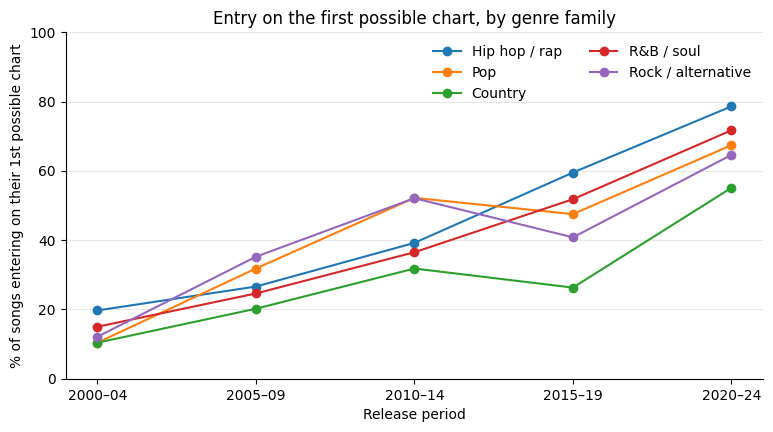

In [ ]:
MAIN_FAMILIES = by_family.index[by_family["songs"] >= 300].tolist()   # families large enough to split by period
fam = in_window[in_window["genre_family"].isin(MAIN_FAMILIES)]

def share_first_chart(w):
    """% of songs entering on their first possible chart, or missing if the group is too small."""
    return round((w == 0).mean() * 100, 1) if len(w) >= MIN_SONGS else np.nan

first_by_family_period = fam.pivot_table(index="genre_family", columns="period", values="waited",
                                         aggfunc=share_first_chart, observed=True)
songs_by_family_period = fam.pivot_table(index="genre_family", columns="period", values="waited",
                                         aggfunc="size", observed=True)
ANALYSIS_RESULTS["first_chart_share_by_family_period"] = first_by_family_period.reset_index().to_dict("records")
print("% entering on their first possible chart (empty: fewer than 30 songs)")
display(first_by_family_period)
print("Number of songs")
display(songs_by_family_period)

composition = (pd.crosstab(in_window["genre_family"].fillna("no genre"), in_window["period"], normalize="columns") * 100).round(1)
ANALYSIS_RESULTS["genre_mix_by_period"] = composition.reset_index().to_dict("records")
print("Genre mix of charting songs, % of each release period")
display(composition)

fig, ax = plt.subplots(figsize=(9, 4.5))
for family in MAIN_FAMILIES:
    row = first_by_family_period.loc[family]
    ax.plot([str(p) for p in row.index], row.values, marker="o", label=family)
ax.set_ylim(0, 100)
ax.legend(frameon=False, ncol=2)
style_axes(ax, "Entry on the first possible chart, by genre family",
           "Release period", "% of songs entering on their 1st possible chart")
save_figure(fig, "9_5_first_chart_by_genre")
plt.show()

**Observations:** among charting songs, hip hop entered fastest (60% on the first possible chart, 79% within four charts) and country slowest (32% and 41%; median wait 9 charts). Within each release period, country is the slowest family in every period (e.g. 55% on the first chart in 2020–2024 against 79% for hip hop), and hip hop the fastest from 2015 onwards; in 2010–2014, pop and rock were fastest (52%). Meanwhile hip hop's share of charting songs rose from 27% (2000–2004) to 46% (2020–2024), while rock fell from 17% to 4%. Holiday songs (22) are too few to compare.

**Interpretation:** genre is clearly associated with *how* songs reach the chart. The difference between country and hip hop holds within every period, so it is not only an effect of when songs were released. A plausible explanation, which our data cannot test, is that country songs are promoted through radio and climb over weeks, while hip hop is driven by streaming from release day. Part of the overall speed-up in 9.3 comes from the growing share of hip hop, but every family also became faster, so the speed-up is not only a change in genre mix.

**Limitations:** genres are volunteer tags, for 1,465 songs taken from the artist rather than the song (8.4e), and the families are our own grouping (8.7). All songs here charted, so these results say nothing about whether a genre helps a song chart (Sections 10–11).

### 9.6 Single or album track?

MusicBrainz records the type of each song's first release (8.2): a single, an album or an EP. We compare how quickly songs entered depending on how they were first released, again within release periods. The type is taken unchanged from `song_musicbrainz` (M1–M4 did not change it); rare types (broadcast, other, unknown) are grouped as "Other / unknown".

In [ ]:
release_types = read_table("SELECT song_id, first_release_type FROM song_musicbrainz")
typed = in_window.merge(release_types, on="song_id", how="left", validate="one_to_one")
if len(typed) != len(in_window):
    raise ValueError("Join contract broken: rows changed when attaching release types.")
typed["release_type"] = typed["first_release_type"].where(
    typed["first_release_type"].isin(["Single", "Album", "EP"]), "Other / unknown")

by_type = (typed.groupby("release_type")[["waited"]].apply(timing_summary)
           .astype({"songs": int}).sort_values("songs", ascending=False))
first_by_type_period = typed.pivot_table(index="release_type", columns="period", values="waited",
                                         aggfunc=share_first_chart, observed=True)
type_mix = (pd.crosstab(typed["release_type"], typed["period"], normalize="columns") * 100).round(1)
ANALYSIS_RESULTS["timing_by_release_type"] = by_type.reset_index().to_dict("records")
ANALYSIS_RESULTS["first_chart_share_by_type_period"] = first_by_type_period.reset_index().to_dict("records")
ANALYSIS_RESULTS["release_type_mix_by_period"] = type_mix.reset_index().to_dict("records")
display(by_type)
print("% entering on their first possible chart (empty: fewer than 30 songs)")
display(first_by_type_period)
print("Type of first release, % of each release period")
display(type_mix)

,songs,median charts waited,25th pct,75th pct,% on 1st possible chart,% within 4 charts
release_type,,,,,,
Album,4975,0.0,0.0,13.0,50.4,63.4
Single,3220,1.0,0.0,5.0,47.4,70.7
EP,212,2.0,0.0,19.0,35.8,52.4
Other / unknown,9,5.0,1.0,9.0,22.2,44.4


% entering on their first possible chart (empty: fewer than 30 songs)


period,2000–04,2005–09,2010–14,2015–19,2020–24
release_type,,,,,
Album,11.4,25.0,25.5,59.3,83.7
EP,NaN,NaN,23.0,39.7,46.9
Single,30.3,39.5,60.2,40.4,46.6


Type of first release, % of each release period


period,2000–04,2005–09,2010–14,2015–19,2020–24
release_type,,,,,
Album,86.1,74.6,41.9,49.6,61.9
EP,0.4,1.7,3.7,3.1,2.3
Other / unknown,0.0,0.4,0.1,0.0,0.1
Single,13.5,23.3,54.3,47.3,35.7


**Observations:** 59% of charting songs were first released on an album, 38% as a single. Until 2010–2014, songs first released as singles entered faster (60% on the first possible chart in 2010–2014, against 26% for album tracks). From 2015 this reversed: in 2020–2024, 84% of album tracks entered on their first possible chart, against 47% of singles. The share of charting songs first released on an album fell from 86% (2000–2004) to 42% (2010–2014), then rose again to 62% (2020–2024).

**Interpretation:** in the streaming era, an album release can put several of its tracks on the chart in the same week, so album tracks that chart do so immediately. Singles, often released ahead of an album, more often enter later, for example when the album comes out or after promotion. In the early 2000s, songs first released on an album typically charted only once promoted to radio, which fits the slow entries in 9.2–9.3.

**Limitations:** "first release" is the earliest dated release in MusicBrainz; if a single and its album were released on the same day, either can be counted first. Early-2000s singles may also be less documented in MusicBrainz than albums, which would inflate the share of album first releases in that period.

### 9.7 Do established artists' songs enter faster?

7.5 showed that about three quarters of charting songs come from lead credits that had charted before. Here we ask whether those songs also enter *faster* than songs by artists reaching the chart for the first time. We reuse the 7.5 definition: a lead credit "had charted before" if it appeared on the Hot 100 before this song's first entry, including before 2000. Comparisons are again made within release periods, with at least 30 songs per share.

,songs,median charts waited,25th pct,75th pct,% on 1st possible chart,% within 4 charts
lead artist,,,,,,
first chart entry,1724,2.0,0.0,13.0,37.9,55.5
had charted before,6692,0.0,0.0,8.0,51.7,68.5


% entering on their first possible chart (empty: fewer than 30 songs)


period,2000–04,2005–09,2010–14,2015–19,2020–24
lead artist,,,,,
first chart entry,18.2,26.8,29.0,36.1,53.9
had charted before,12.7,29.0,47.5,53.6,73.7


Number of songs


period,2000–04,2005–09,2010–14,2015–19,2020–24
lead artist,,,,,
first chart entry,154,257,293,443,577
had charted before,582,1012,1342,1572,2184


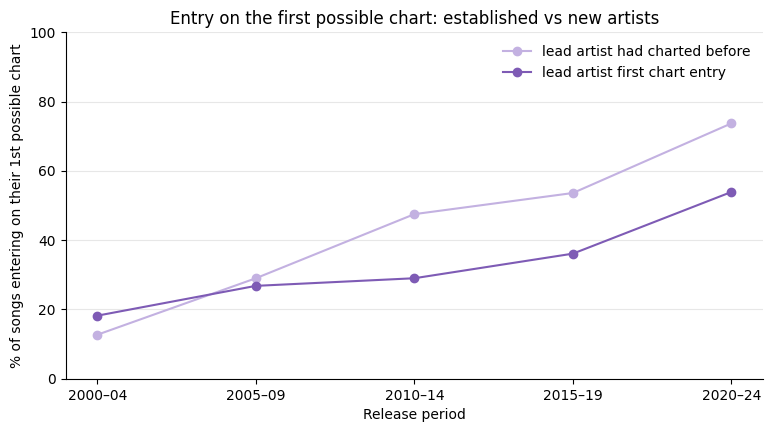

In [ ]:
artist_history = entered[["song_id", "lead_charted_before"]]
history = in_window.merge(artist_history, on="song_id", how="left", validate="one_to_one")
if len(history) != len(in_window) or history["lead_charted_before"].isna().any():
    raise ValueError("Join contract broken: a song is missing its artist history.")
history["lead artist"] = np.where(history["lead_charted_before"], "had charted before", "first chart entry")

by_history = (history.groupby("lead artist")[["waited"]].apply(timing_summary).astype({"songs": int}))
first_by_history_period = history.pivot_table(index="lead artist", columns="period", values="waited",
                                              aggfunc=share_first_chart, observed=True)
songs_by_history_period = history.pivot_table(index="lead artist", columns="period", values="waited",
                                              aggfunc="size", observed=True)
ANALYSIS_RESULTS["timing_by_artist_history"] = by_history.reset_index().to_dict("records")
ANALYSIS_RESULTS["first_chart_share_by_history_period"] = first_by_history_period.reset_index().to_dict("records")
display(by_history)
print("% entering on their first possible chart (empty: fewer than 30 songs)")
display(first_by_history_period)
print("Number of songs")
display(songs_by_history_period)

fig, ax = plt.subplots(figsize=(9, 4.5))
for label, color in [("had charted before", COLOR_MAIN), ("first chart entry", COLOR_SECOND)]:
    row = first_by_history_period.loc[label]
    ax.plot([str(p) for p in row.index], row.values, marker="o", color=color, label=f"lead artist {label}")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
style_axes(ax, "Entry on the first possible chart: established vs new artists",
           "Release period", "% of songs entering on their 1st possible chart")
save_figure(fig, "9_7_first_chart_by_artist_history")
plt.show()

**Observations:** 80% of the songs (6,692 of 8,416) came from lead credits that had charted before. Their songs entered faster: 52% on the first possible chart (median wait 0 charts) against 38% for artists entering the chart for the first time (median 2 charts). The gap appeared over time: in 2000–2004 newcomers were not slower (18% against 13% on the first chart), but from 2010–2014 established artists were clearly faster (48% against 29%), and in 2020–2024 74% against 54%.

**Interpretation:** for established artists, chart entry has become largely a matter of release week: an existing audience streams a new release immediately, which also explains the album "bursts" in 7.6. Newcomers more often build up over several weeks, for example through radio or viral spread. In the early 2000s, when most songs climbed slowly through radio (9.3), an artist's history made no difference to the speed of entry.

**Limitations:** "had charted before" is based on the lead credit text (7.5), so a collaboration credit such as "A & B" counts as a separate credit from "A". All songs here charted: whether being established makes a song more likely to chart at all cannot be tested with our comparison group, because all its artists have charted (Section 10).

### 9.8 Save the analysis results

In [ ]:
def without_nan(obj):
    """Replace missing numbers (NaN) by null, so the file is valid JSON for any program."""
    if isinstance(obj, dict):
        return {k: without_nan(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [without_nan(v) for v in obj]
    if isinstance(obj, float) and np.isnan(obj):
        return None
    return obj

ANALYSIS_RESULTS["release_to_chart_gap_by_rules"] = gap_table.reset_index().to_dict("records")
ANALYSIS_FILE = OUTPUT_DIR / "analysis_results_time_to_chart.json"
ANALYSIS_FILE.write_text(json.dumps(without_nan({
    "record_type": "analysis results – time to chart of Billboard Hot 100 songs (aggregates only)",
    "source_commit": SOURCE_COMMIT,
    "musicbrainz_export_sha256": mb_sha256,
    "computed_at_utc": datetime.now(timezone.utc).replace(microsecond=0).isoformat(),
    "tracking_rules": [{"charts_dated_before": None if d == pd.Timestamp.max else str(d.date()),
                        "days_after_tracking_week": lag} for d, lag in TRACKING_RULES],
    "follow_up_charts": FOLLOW_UP_CHARTS,
    "long_follow_up_charts": LONG_FOLLOW_UP,
    "min_songs_per_share": MIN_SONGS,
    "results": ANALYSIS_RESULTS,
}), indent=2, ensure_ascii=False, allow_nan=False, default=str), encoding="utf-8")
download_file(ANALYSIS_FILE)   # the figures are zipped and downloaded once, with all others, in 11.6

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 9.9 Summary of Section 9

**Observations:**
1. Because Billboard changed how charts are dated (2015, 2018), time to chart is measured in charts waited after a song's first possible chart, not in days (9.1).
2. Of charting songs released 2000–2020, 38% entered on their first possible chart, 54% within four charts and 92% within a year (9.2).
3. Entry became much faster: the share entering on the first possible chart rose from 14% (released 2000–2004) to 70% (2020–2024) (9.3).
4. There is a threshold after the first two possible charts: the weekly chance of entering falls from 38% and 19% to about 4% and stays there (9.4).
5. Country songs entered slowest and hip hop fastest, in every period (9.5); album tracks entered fastest in the streaming era, singles before it (9.6); established artists' songs entered faster from 2010 onwards (9.7).

**Interpretation:** for songs that reach the Hot 100, our hypothesis is supported: success is mostly decided in the first weeks after release, and increasingly so in the streaming era. Genre, release type and artist history are associated with how quickly songs enter, but these are associations among charting songs only, partly shaped by how songs are promoted, and they do not show what makes a song chart at all. That requires songs that did not chart (Sections 10–11).

## 10. Comparison group: songs that did not chart

Section 9 described *when* charting songs enter the Hot 100, but every song analysed there reached the chart (9.4). To study *whether* a song reaches the chart, we also need songs that did not. This section builds that comparison group and takes it through the same steps as the Billboard data: collection (10.1–10.2), checks (10.3–10.4), cleaning (10.5) and storage (10.6–10.7). The comparison itself follows in Section 11.

### 10.1 How the comparison group was obtained (Job B)

As a comparison group we use **songs by the same lead artists that never charted**, released 2000–2024 (decision log, rows 12–14). Using the same artists means every song in the group comes from an artist with proven access to the US market, rather than from the millions of obscure recordings in MusicBrainz. The songs were extracted from the same MusicBrainz database as in Section 8, with a second script (`run_comparison.sh`, `mb_07`, `mb_08`), using the same rules as for the charting songs:

- **Lead artist** of each charting song: the first credited artist on its matched recordings.
- **Candidate songs:** every recording on which one of these artists is credited first, without music videos and live, karaoke, instrumental, demo or a cappella versions.
- **One song = artist + title without brackets**, so that remixes and re-releases count once.
- **Excluded:** any title equal to a Billboard title (by any artist), anything matched to a charting song, and intros, outros, interludes and skits.
- **First release date, release type and genre:** the same rules as for the charting songs (8.2).

How many recordings each rule removed (from `run_log_comparison.txt`):

| Step | Recordings or songs |
|---|---|
| Candidate recordings of the 2,102 lead artists | 964,829 |
| Removed: same title as a Billboard song | 230,028 |
| Removed: matched to a charting song | 52,867 |
| Removed: intro, outro, interlude or skit | 6,981 |
| Removed: empty title | 5,740 |
| Recordings kept | 725,119 |
| Songs (artist + title) | 288,889 |
| … with a release date | 243,274 |
| … first released 2000–2024 | **186,819** |

A recording can be removed for several reasons, so the removals add up to more than the difference. Running the script twice produced byte-identical files (same SHA-256), which confirms that the extraction is reproducible.

### 10.2 Download and verify

In [ ]:
CMP_COMMIT = "6d45e7be9a9920e85e3d8feaf14c92e648c0d9c9"     # pinned snapshot containing the Job B files
CMP_FILES = {                                               # file -> SHA-256 recorded by run_comparison.sh
    "comparison_songs_musicbrainz.csv.gz": "fa4fb810e4533bd452a0c0aa8d3ec56a2aa863da50beadd1de16dfefdde7bc4d",
    "billboard_song_lead_artist.csv":      "603571bea2d887dd460556b5f39dd40864934b4728b03084291387e847ef4206",
}

CMP_ACCESS_TIME_UTC = datetime.now(timezone.utc).replace(microsecond=0)
cmp_bytes = {}
for path, expected_sha256 in CMP_FILES.items():
    url = f"https://raw.githubusercontent.com/{MB_REPO}/{CMP_COMMIT}/{path}"
    data = download_bytes(url)
    file_sha256 = hashlib.sha256(data).hexdigest()   # own name: actual_sha256 is the Billboard file's (3.2)
    print(f"{path}\n  expected SHA-256: {expected_sha256}\n  actual SHA-256  : {file_sha256}")
    if file_sha256 != expected_sha256:
        raise ValueError(f"{path} is NOT the file produced by our PostgreSQL run. Stop here.")
    (RAW_DIR / path).write_bytes(data)
    cmp_bytes[path] = data
print(f"Integrity checks passed. Both files saved in: {RAW_DIR}")

comparison_songs_musicbrainz.csv.gz
  expected SHA-256: fa4fb810e4533bd452a0c0aa8d3ec56a2aa863da50beadd1de16dfefdde7bc4d
  actual SHA-256  : fa4fb810e4533bd452a0c0aa8d3ec56a2aa863da50beadd1de16dfefdde7bc4d
billboard_song_lead_artist.csv
  expected SHA-256: 603571bea2d887dd460556b5f39dd40864934b4728b03084291387e847ef4206
  actual SHA-256  : 603571bea2d887dd460556b5f39dd40864934b4728b03084291387e847ef4206
Integrity checks passed. Both files saved in: outputs/raw


### 10.3 Structure

In [ ]:
CMP_TYPES = {"comparison_id": str, "artist_mbid": str, "mb_title": str, "n_recordings": "Int64",
             "first_release_type": str, "first_release_year": "Int64", "first_release_date": str,
             "date_precision": str, "genre_level": str, "top_genre": str, "top_genres_votes": str}
LEAD_TYPES = {"song_id": str, "artist_mbid": str, "artist_name": str}
cmp_raw = pd.read_csv(io.BytesIO(cmp_bytes["comparison_songs_musicbrainz.csv.gz"]), compression="gzip",
                      dtype=CMP_TYPES, keep_default_na=False, na_values=[""])
lead_raw = pd.read_csv(io.BytesIO(cmp_bytes["billboard_song_lead_artist.csv"]),
                       dtype=LEAD_TYPES, keep_default_na=False, na_values=[""])

matched_ids = set(read_table("SELECT song_id FROM song_musicbrainz WHERE match_method <> 'no match'")["song_id"])
structure = {
    "comparison songs (expected 186,819)": len(cmp_raw),
    "comparison columns as expected": list(cmp_raw.columns) == list(CMP_TYPES),
    "comparison_id unique": bool(cmp_raw["comparison_id"].is_unique),
    "every release year within 2000–2024": bool(cmp_raw["first_release_year"].between(2000, 2024).all()),
    "lead-artist rows (expected 11,224)": len(lead_raw),
    "lead-artist columns as expected": list(lead_raw.columns) == list(LEAD_TYPES),
    "song_id unique in lead-artist file": bool(lead_raw["song_id"].is_unique),
    "lead-artist file covers exactly our matched songs": set(lead_raw["song_id"]) == matched_ids,
    "every comparison artist is a lead artist": bool(cmp_raw["artist_mbid"].isin(lead_raw["artist_mbid"]).all()),
}
CMP_QA = {"structure": {k: (v if isinstance(v, bool) else int(v)) for k, v in structure.items()}}
display(pd.Series(structure, name="value").to_frame())
if not all(v is True or v in (186_819, 11_224) for v in structure.values()):
    raise ValueError("The comparison files do not have the expected structure.")
cmp_raw.head(3)

,value
"comparison songs (expected 186,819)",186819
comparison columns as expected,True
comparison_id unique,True
every release year within 2000–2024,True
"lead-artist rows (expected 11,224)",11224
lead-artist columns as expected,True
song_id unique in lead-artist file,True
lead-artist file covers exactly our matched songs,True
every comparison artist is a lead artist,True


,comparison_id,artist_mbid,mb_title,n_recordings,first_release_type,first_release_year,first_release_date,date_precision,genre_level,top_genre,top_genres_votes
0,000013ae55f265a5d98baf348e1ad18d,d68fda90-ab8d-4799-be56-317ba4ae700f,Guapa,1,Album,2022,2022-03-11,day,release group,latin,latin:2|pop:1|reggaeton:1
1,00005d4a604bd51eb0e3096821355e8a,ceb3f5b7-9f1a-430f-afbe-976fdcf30482,New Balance,1,Album,2017,2017-09-22,day,release group,contemporary r&b,contemporary r&b:1|soul:1
2,00005ff173588856a0195cc0c1db0b31,ebee61b4-bbdd-4087-9bcb-d5aa099088ec,Care a Little Less,1,Album,2023,2023-10-27,day,release group,pop,pop:1|pop rock:1|rock:1


### 10.4 Quality assessment

In [ ]:
import unicodedata   # standard library: removes accents (e.g. "Beyoncé" -> "Beyonce")

def title_key(titles):
    """Title without bracketed parts, accents, case and punctuation (the rule used in mb_07)."""
    plain = titles.map(lambda t: unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode())
    return make_key(plain.str.replace(r"\s*[\(\[][^\)\]]*[\)\]]", "", regex=True))

# 1. Contamination: does any comparison song have the same artist and title as one of our charting songs?
charting_titles = (read_table("song_names")[["song_id", "title"]]
                   .merge(lead_raw[["song_id", "artist_mbid"]], on="song_id", how="inner", validate="many_to_one")
                   .assign(key=lambda d: title_key(d["title"]))[["artist_mbid", "key"]].drop_duplicates())
same_song = (cmp_raw.assign(key=title_key(cmp_raw["mb_title"]))
                    .merge(charting_titles, on=["artist_mbid", "key"], how="inner", validate="many_to_one"))
print(f"Comparison songs with the same artist and title as a charting song: {len(same_song)}")

# 2. Who are the lead artists, and how many comparison songs does each contribute?
artist_names = lead_raw.drop_duplicates("artist_mbid").set_index("artist_mbid")["artist_name"]
per_artist = pd.DataFrame({
    "artist_name": artist_names,
    "charting_songs": lead_raw.groupby("artist_mbid").size(),
    "comparison_songs": cmp_raw.groupby("artist_mbid").size(),
}).fillna({"comparison_songs": 0}).astype({"comparison_songs": int})
placeholder = per_artist["artist_name"].str.fullmatch(r"\[.*\]")

released = (lead_raw.merge(read_table("SELECT song_id, first_release_year FROM song_musicbrainz"), on="song_id",
                           how="left", validate="one_to_one")
                    .merge(read_table("SELECT song_id, first_chart_date FROM song_summary"), on="song_id",
                           how="left", validate="one_to_one"))
released["new_release"] = released["first_release_year"] >= released["first_chart_date"].dt.year - 5
only_old_songs = ~released.groupby("artist_mbid")["new_release"].any()
per_artist["only_old_songs"] = only_old_songs.reindex(per_artist.index).fillna(False).astype(bool)

top_share = per_artist["comparison_songs"].nlargest(20).sum() / len(cmp_raw)
artist_checks = {
    "lead artists": len(per_artist),
    "lead artists without comparison songs": int((per_artist["comparison_songs"] == 0).sum()),
    "placeholder 'artists' (names in [brackets])": int(placeholder.sum()),
    "  comparison songs of these placeholders": int(per_artist.loc[placeholder, "comparison_songs"].sum()),
    "artists that charted only with songs released 5+ years earlier": int(per_artist["only_old_songs"].sum()),
    "  comparison songs of these artists": int(per_artist.loc[per_artist["only_old_songs"], "comparison_songs"].sum()),
    "median comparison songs per artist": float(per_artist["comparison_songs"].median()),
    "share of comparison songs from the 20 largest catalogues": round(float(top_share), 3),
}
CMP_QA["contamination_same_artist_and_title"] = len(same_song)
CMP_QA["artists"] = artist_checks
display(pd.Series(artist_checks, name="value").to_frame())
per_artist.sort_values("comparison_songs", ascending=False).head(12)

Comparison songs with the same artist and title as a charting song: 0


,value
lead artists,2102.000
lead artists without comparison songs,39.000
placeholder 'artists' (names in [brackets]),2.000
comparison songs of these placeholders,3739.000
artists that charted only with songs released 5+ years earlier,54.000
comparison songs of these artists,6450.000
median comparison songs per artist,57.000
share of comparison songs from the 20 largest catalogues,0.105


,artist_name,charting_songs,comparison_songs,only_old_songs
artist_mbid,,,,
a0ef7e1d-44ff-4039-9435-7d5fefdeecc9,[theatre],4,1936,False
66ea0139-149f-4a0c-8fbf-5ea9ec4a6e49,[Disney],1,1803,False
36494952-f434-45d8-a958-8b4acdbcf8a8,Gucci Mane,17,1661,False
f6580b26-77f7-4a7b-8513-6db0476e8f21,James Newton Howard,1,1557,False
ac9a487a-d9d2-4f27-bb23-0f4686488345,Lil Wayne,83,1075,False
e0bba708-bdd3-478d-84ea-c706413bedab,A. R. Rahman,1,1027,False
4ce1c576-305a-4b82-82fa-5e5359056219,Curren$y,1,1009,False
477b8c0c-c5fc-4ad2-b5b2-191f0bf2a9df,Armin van Buuren,1,1004,False
8ba17cf6-bec2-4ae4-9820-b1cda47adc08,Boosie Badazz,2,881,False


In [ ]:
charting_2000_2024 = read_table("""SELECT * FROM song_musicbrainz
                                    WHERE match_method <> 'no match' AND first_release_year BETWEEN 2000 AND 2024""")

NOT_MUSIC = ["non-music", "interview", "spoken word", "field recording"]   # MusicBrainz genres that are not songs
not_music = pd.DataFrame({"charting songs": charting_2000_2024["top_genre"].value_counts().reindex(NOT_MUSIC),
                          "comparison songs": cmp_raw["top_genre"].value_counts().reindex(NOT_MUSIC)}).fillna(0).astype(int)
CMP_QA["main_genre_not_music"] = not_music.to_dict()
print("Songs whose main genre says they are not music:")
display(not_music)

def measurement_profile(df):
    """How completely the songs of one group are described in MusicBrainz (shares in %)."""
    day = df["date_precision"] == "day"
    return pd.Series({
        "songs": len(df),
        "% exact release date": round(day.mean() * 100, 1),
        "% of exact dates on 1 January": round((day & df["first_release_date"].str.endswith("-01-01")).sum()
                                               / day.sum() * 100, 1),
        "% genre from the recording": round((df["genre_level"] == "recording").mean() * 100, 1),
        "% genre from the release group": round((df["genre_level"] == "release group").mean() * 100, 1),
        "% genre from the artist only": round((df["genre_level"] == "artist").mean() * 100, 1),
        "% no genre": round(df["genre_level"].isna().mean() * 100, 1),
        "% first released on an album": round((df["first_release_type"] == "Album").mean() * 100, 1),
        "% first released as a single": round((df["first_release_type"] == "Single").mean() * 100, 1),
    })

measurement = pd.DataFrame({"charting songs (released 2000–2024)": measurement_profile(charting_2000_2024),
                            "comparison songs": measurement_profile(cmp_raw)})
CMP_QA["measurement_by_group"] = measurement.to_dict()
measurement

Songs whose main genre says they are not music:


,charting songs,comparison songs
top_genre,,
non-music,0,216
interview,0,258
spoken word,0,18
field recording,0,19


,charting songs (released 2000–2024),comparison songs
songs,10385.0,186819.0
% exact release date,93.3,86.4
% of exact dates on 1 January,2.3,1.6
% genre from the recording,69.6,27.2
% genre from the release group,16.2,27.1
% genre from the artist only,12.7,42.0
% no genre,1.5,3.8
% first released on an album,62.6,81.8
% first released as a single,34.1,9.9


**Observations:** no comparison song has the same artist and title as a charting song, so the exclusion of charting songs worked. The 2,102 lead artists contribute a median of 57 comparison songs each; the 20 largest catalogues hold 10.5% of all comparison songs (e.g. Gucci Mane 1,661, the film composer James Newton Howard 1,557). The check also revealed three problems: two placeholder "artists" used by MusicBrainz for cast and soundtrack recordings, `[theatre]` and `[Disney]` (3,739 songs); 54 artists that reached the chart only with songs released more than five years earlier, such as holiday classics by Bing Crosby or Nat King Cole and revivals such as Kate Bush (6,450 songs); and 511 recordings that are not music (interviews, spoken word, field recordings). Finally, the two groups are not described equally well: comparison songs less often have an exact release date (86% against 93%), their genre comes much more often from the artist alone (42% against 13%), and they were much more often first released on an album (82% against 63%) and much less often as a single (10% against 34%).

**Interpretation:** the three problems are cleaned below (K1–K3). The other differences must be kept in mind in the analysis: an artist-level genre is the same for all of an artist's songs, so genre comparisons between charting and non-charting songs are only meaningful for songs with their own genre; and because most non-charting songs are album tracks, a difference in release type partly reflects that labels choose likely hits as singles (the release type is not independent of expected success). Because a few artists contribute very many songs, comparisons should give each artist equal weight rather than each song.

### 10.5 Cleaning (K1–K5)

We clean the comparison group in five logged steps ("K" for comparison), mirroring the charting songs. The published extract and the database table `comparison_musicbrainz` stay unchanged; excluded artists are recorded with their reason in `comparison_artists`, and the cleaned values go into `comparison_clean`.

| Step | What | Responds to |
|---|---|---|
| K1 | Remove songs of placeholder artists | `[theatre]`, `[Disney]` (10.4) |
| K2 | Remove artists that charted only with songs released 5+ years earlier | reissues, not new songs (10.4) |
| K3 | Remove recordings whose main genre says they are not music | interviews etc. (10.4) |
| K4 | Exact dates on 1 January treated as known to the year only | same as M1 |
| K5 | Genres grouped into the same 10 families | same as M4 |

In [ ]:
CMP_CLEANING_LOG = []

def log_cmp_step(step, description, rows_before, rows_after, values_changed, justification):
    """Record one cleaning step of the comparison group (same idea as log_step in Section 5)."""
    CMP_CLEANING_LOG.append({"step": step, "description": description, "rows_before": int(rows_before),
                             "rows_after": int(rows_after), "values_changed": int(values_changed),
                             "justification": justification})
    print(f"[{step}] {description}\n      rows {rows_before:,} → {rows_after:,} | values changed: {values_changed:,}")

per_artist["exclusion_reason"] = np.select(
    [placeholder, per_artist["only_old_songs"]],
    ["placeholder artist (K1)", "charted only with songs released 5+ years earlier (K2)"], default=None)
per_artist["included"] = per_artist["exclusion_reason"].isna()

cmpc = cmp_raw.copy()
n0 = len(cmpc)
cmpc = cmpc[~cmpc["artist_mbid"].isin(per_artist.index[placeholder])]
log_cmp_step("K1", "Remove songs credited to placeholder artists ([theatre], [Disney])", n0, len(cmpc), 0,
             "MusicBrainz uses these names for cast and soundtrack recordings by many different performers; "
             "they are not artists. mb_07 skipped other placeholders but not these two.")

n1 = len(cmpc)
cmpc = cmpc[~cmpc["artist_mbid"].isin(per_artist.index[per_artist["only_old_songs"]])]
log_cmp_step("K2", "Remove artists that reached the chart only with songs released 5+ years earlier", n1, len(cmpc), 0,
             "E.g. Bing Crosby, Nat King Cole, Frank Sinatra (holiday classics) or Kate Bush (revival): their "
             "2000–2024 releases are mostly reissues, not new songs competing for the chart (same idea as M3).")

n2 = len(cmpc)
cmpc = cmpc[~cmpc["top_genre"].isin(NOT_MUSIC)]
log_cmp_step("K3", "Remove recordings whose main genre says they are not music", n2, len(cmpc), 0,
             "Interviews, spoken word and field recordings (10.4) are not songs that could chart; "
             "no charting song has these genres.")

day_dates = cmpc["date_precision"] == "day"
jan_first = day_dates & cmpc["first_release_date"].str.endswith("-01-01")
cmpc["release_date"] = pd.to_datetime(cmpc["first_release_date"].where(day_dates & ~jan_first), format="%Y-%m-%d")
cmpc["release_precision"] = cmpc["date_precision"].where(~jan_first, "year")
log_cmp_step("K4", "Treat exact dates on 1 January as known to the year only (as M1)", len(cmpc), len(cmpc),
             jan_first.sum(), f"{int(jan_first.sum()):,} dates on 1 January against about "
             f"{day_dates.sum() / 365.25:,.0f} expected: placeholders, as for the charting songs.")

cmpc["genre_family"] = cmpc["top_genre"].map(genre_family)
log_cmp_step("K5", "Group the detailed genres into broad families (rules of M4)", len(cmpc), len(cmpc),
             cmpc["top_genre"].notna().sum(), "Same rules as for the charting songs, so that both groups are comparable.")
charting_genres = set(read_table("song_musicbrainz")["top_genre"].dropna())
new_genres = (cmpc[~cmpc["top_genre"].isin(charting_genres) & cmpc["top_genre"].notna()]
              .groupby(["top_genre", "genre_family"]).size().rename("songs").reset_index()
              .sort_values("songs", ascending=False))
CMP_QA["genres_not_seen_among_charting_songs"] = {"genres": len(new_genres), "songs": int(new_genres["songs"].sum())}
print(f"Genres not seen among charting songs: {len(new_genres)} ({new_genres['songs'].sum():,} songs); "
      "the 15 most frequent and the family the rules give them:")
display(new_genres.head(15))
family_cmp = cmpc["genre_family"].value_counts(dropna=False).rename("songs").to_frame()
family_cmp["share"] = (family_cmp["songs"] / len(cmpc)).round(3)
family_cmp

[K1] Remove songs credited to placeholder artists ([theatre], [Disney])
      rows 186,819 → 183,080 | values changed: 0
[K2] Remove artists that reached the chart only with songs released 5+ years earlier
      rows 183,080 → 176,630 | values changed: 0
[K3] Remove recordings whose main genre says they are not music
      rows 176,630 → 176,210 | values changed: 0
[K4] Treat exact dates on 1 January as known to the year only (as M1)
      rows 176,210 → 176,210 | values changed: 2,468
[K5] Group the detailed genres into broad families (rules of M4)
      rows 176,210 → 176,210 | values changed: 170,952
Genres not seen among charting songs: 250 (2,350 songs); the 15 most frequent and the family the rules give them:


,top_genre,genre_family,songs
58,coke rap,Hip hop / rap,99
218,smooth jazz,Other,98
66,cumbia,Latin,91
159,latin rock,Latin,76
44,chanson française,Other,75
133,heartland rock,Rock / alternative,69
29,bluegrass,Country,66
36,brostep,Electronic / dance,57
246,vocal jazz,Other,46
220,soca,Other,45


,songs,share
genre_family,,
Hip hop / rap,65184,0.370
Rock / alternative,24898,0.141
Pop,22030,0.125
Country,14966,0.085
R&B / soul,14302,0.081
Other,11750,0.067
Electronic / dance,10475,0.059
Latin,6421,0.036
<NA>,5258,0.030


**Observations:** after cleaning, the comparison group contains 176,210 songs by 2,009 artists. 56 artists were excluded (2 placeholders, 54 that charted only with old songs; 3,739 + 6,450 songs removed), 420 recordings that are not music were removed, and 37 of the 2,046 remaining artists have no comparison song released 2000–2024. 2,468 release dates on 1 January were set to year precision. 250 genres occur only among comparison songs (2,350 songs, 1.3%); inspecting the most frequent showed one gap in our rules ("brostep", a dubstep style), which was added to the electronic family in 8.7 without changing any charting song.

**Interpretation:** the cleaned group consists of real songs by artists who were active in our period, measured with the same rules as the charting songs. Film composers (e.g. James Newton Howard, A. R. Rahman) and very prolific rappers remain, because by our definition they are charting lead artists; their weight is limited in the analysis by giving each artist equal weight (Section 11).

### 10.6 Store in the database

In [ ]:
con.executescript("""
DROP TABLE IF EXISTS comparison_clean;          -- tables that refer to others are dropped first
DROP TABLE IF EXISTS song_lead_artist;
DROP TABLE IF EXISTS comparison_musicbrainz;
DROP TABLE IF EXISTS comparison_artists;

CREATE TABLE comparison_artists (
    artist_mbid       TEXT    PRIMARY KEY,
    artist_name       TEXT    NOT NULL,
    charting_songs    INTEGER NOT NULL CHECK (charting_songs >= 1),
    comparison_songs  INTEGER NOT NULL CHECK (comparison_songs >= 0),
    included          INTEGER NOT NULL CHECK (included IN (0, 1)),
    exclusion_reason  TEXT,
    CHECK ((included = 1) = (exclusion_reason IS NULL))
);

CREATE TABLE song_lead_artist (
    song_id      TEXT PRIMARY KEY REFERENCES songs(song_id),
    artist_mbid  TEXT NOT NULL REFERENCES comparison_artists(artist_mbid)
);

CREATE TABLE comparison_musicbrainz (
    comparison_id       TEXT    PRIMARY KEY CHECK (length(comparison_id) = 32),
    artist_mbid         TEXT    NOT NULL REFERENCES comparison_artists(artist_mbid),
    mb_title            TEXT    NOT NULL,
    n_recordings        INTEGER NOT NULL CHECK (n_recordings >= 1),
    first_release_type  TEXT,
    first_release_year  INTEGER NOT NULL CHECK (first_release_year BETWEEN 2000 AND 2024),
    first_release_date  TEXT    NOT NULL,
    date_precision      TEXT    NOT NULL CHECK (date_precision IN ('day', 'month', 'year')),
    genre_level         TEXT    CHECK (genre_level IN ('recording', 'release group', 'artist')),
    top_genre           TEXT,
    top_genres_votes    TEXT
);

CREATE TABLE comparison_clean (
    comparison_id      TEXT PRIMARY KEY REFERENCES comparison_musicbrainz(comparison_id),
    release_date       TEXT,
    release_precision  TEXT NOT NULL CHECK (release_precision IN ('day', 'month', 'year')),
    genre_family       TEXT
);
""")
artists_tbl = per_artist.rename_axis("artist_mbid").reset_index()[
    ["artist_mbid", "artist_name", "charting_songs", "comparison_songs", "included", "exclusion_reason"]]
to_sql_ready(artists_tbl).to_sql("comparison_artists", con, if_exists="append", index=False)
lead_raw[["song_id", "artist_mbid"]].to_sql("song_lead_artist", con, if_exists="append", index=False)
cmp_raw.to_sql("comparison_musicbrainz", con, if_exists="append", index=False)
to_sql_ready(cmpc[["comparison_id", "release_date", "release_precision", "genre_family"]]).to_sql(
    "comparison_clean", con, if_exists="append", index=False)
con.commit()

db_cmp = {
    "comparison_artists": q("SELECT COUNT(*) AS n FROM comparison_artists")["n"][0],
    "  of which included": q("SELECT SUM(included) AS n FROM comparison_artists")["n"][0],
    "song_lead_artist": q("SELECT COUNT(*) AS n FROM song_lead_artist")["n"][0],
    "comparison_musicbrainz": q("SELECT COUNT(*) AS n FROM comparison_musicbrainz")["n"][0],
    "comparison_clean": q("SELECT COUNT(*) AS n FROM comparison_clean")["n"][0],
    "foreign-key violations": len(q("PRAGMA foreign_key_check")),
    "clean songs of excluded artists": q("""SELECT COUNT(*) AS n FROM comparison_clean c
                                           JOIN comparison_musicbrainz m USING (comparison_id)
                                           JOIN comparison_artists a USING (artist_mbid)
                                           WHERE a.included = 0""")["n"][0],
}
CMP_QA["database_checks"] = {k: int(v) for k, v in db_cmp.items()}
display(pd.Series(db_cmp, name="value").to_frame())
if db_cmp["foreign-key violations"] or db_cmp["clean songs of excluded artists"]:
    raise ValueError("The comparison tables break a database rule.")

,value
comparison_artists,2102
of which included,2046
song_lead_artist,11224
comparison_musicbrainz,186819
comparison_clean,176210
foreign-key violations,0
clean songs of excluded artists,0


### 10.7 Save the provenance, quality and cleaning record

In [ ]:
CMP_PROV_FILE = OUTPUT_DIR / "provenance_quality_comparison.json"
CMP_PROV_FILE.write_text(json.dumps({
    "record_type": "provenance, quality assessment and cleaning log – comparison group (Job B)",
    "musicbrainz_dump": MB_DUMP,
    "export_repository": f"https://github.com/{MB_REPO}",
    "export_commit": CMP_COMMIT,
    "export_files_sha256": CMP_FILES,
    "accessed_at_utc": CMP_ACCESS_TIME_UTC.isoformat(),
    "quality": CMP_QA,
    "cleaning_steps": CMP_CLEANING_LOG,
    "excluded_artists": artists_tbl.loc[~artists_tbl["included"], ["artist_name", "exclusion_reason"]].to_dict("records"),
}, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
download_file(CMP_PROV_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 10.8 Summary of Section 10

**Observations:** a comparison group of 186,819 songs by the 2,102 lead artists of our matched charting songs, never charted and first released 2000–2024, was extracted reproducibly from the same MusicBrainz database (10.1) and verified (10.2–10.3). No comparison song has the same artist and title as a charting song. After removing placeholder artists, artists that charted only with old songs, and recordings that are not music, 176,210 songs by 2,009 artists remain (10.5).

**Interpretation:** the group gives us what the chart data alone cannot: songs that did not reach the chart, by artists who demonstrably could. Three limitations follow for Section 11: non-charting songs are less well documented (fewer exact dates; genres more often from the artist alone), so only equally measured variables can be compared; release type is partly a consequence of expected success (labels release likely hits as singles); and catalogue sizes differ widely between artists, so each artist must get equal weight. Because every artist in the group has charted, the comparison cannot test whether being a known artist helps a song chart.

## 11. What distinguishes the songs that charted?

This section answers our research question directly: among songs by the same artists, released in the same years, how do the songs that reached the Hot 100 differ from those that did not?

**Measure.** The **chart rate**: the share of songs that charted.

**Design choices** (decision log, rows 18, 21, 22):
- **Same artists, same years.** Only songs by the 2,046 included lead artists (Section 10), first released 2000–2023 in both groups. 2023 is the last release year that gives every song at least two years to chart, even songs whose release is known only to the year.
- **Each artist counts equally.** Catalogue sizes differ widely (10.4), so shares are computed per artist and then averaged. Only artists with at least 10 songs in the group being compared are used; with fewer, a single song swings an artist's share by 10 points or more.
- **Within-artist comparisons.** For release type and genre, we compare each category's chart rate with *the same artist's own average*. A positive difference means: when an artist releases a song of this kind, it charts more often than that artist's songs usually do. This removes differences between artists, such as how famous they are.
- **Uncertainty.** Next to each average difference we give an approximate 95% range (the average ± 1.96 standard errors across artists). If the range does not include 0, the difference is unlikely to be explained by chance variation between artists. This is a simple descriptive measure, not a model.

As before, every result is followed by observations and, separately, interpretations. All comparisons describe associations, not causes.

### 11.1 The songs compared, and how many charted

In [ ]:
COMPARISON_RESULTS = {}
LAST_RELEASE_YEAR = 2023      # every song, even one known only to the year, has at least 2 years to chart
MIN_ARTIST_SONGS = 10         # artist-level shares need at least this many songs

SONG_COLUMNS = """artist_mbid, first_release_year, first_release_type, genre_level,
                  c.genre_family, c.release_date, c.release_precision"""
charting = read_table(f"""
    SELECT m.song_id AS song_key, {SONG_COLUMNS}, c.flag_release_after_chart
    FROM song_musicbrainz m
    JOIN song_lead_artist l    USING (song_id)
    JOIN comparison_artists a  USING (artist_mbid)
    JOIN song_mb_clean c       USING (song_id)
    WHERE a.included = 1""")
not_charting = read_table(f"""
    SELECT m.comparison_id AS song_key, {SONG_COLUMNS}
    FROM comparison_musicbrainz m
    JOIN comparison_clean c USING (comparison_id)""")

# Concatenate: same kind of observation (a song of a lead artist), with a column saying where each row comes from.
all_songs = pd.concat([charting.assign(charted=True),
                       not_charting.assign(charted=False, flag_release_after_chart=False)], ignore_index=True)
if not all_songs["song_key"].is_unique:
    raise ValueError("A song appears twice after concatenating the two groups.")

all_songs = all_songs.rename(columns={"first_release_year": "release_year"})
all_songs["release_type"] = all_songs["first_release_type"].where(
    all_songs["first_release_type"].isin(["Single", "Album", "EP"]), "Other / unknown")
all_songs["period"] = pd.cut(all_songs["release_year"].astype(float), [1999, 2004, 2009, 2014, 2019, LAST_RELEASE_YEAR],
                             labels=["2000–04", "2005–09", "2010–14", "2015–19", f"2020–{str(LAST_RELEASE_YEAR)[2:]}"])

ledger = []
def add_to_ledger(label, df, reason):
    ledger.append({"step": label, "charting songs": int(df["charted"].sum()),
                   "non-charting songs": int((~df["charted"]).sum()), "artists": df["artist_mbid"].nunique(),
                   "reason": reason})
add_to_ledger("songs of included lead artists", all_songs, "Sections 8 and 10; charting songs need a MusicBrainz match")
songs_2000_2023 = all_songs[all_songs["release_year"].between(2000, LAST_RELEASE_YEAR)].copy()
add_to_ledger(f"first released 2000–{LAST_RELEASE_YEAR}", songs_2000_2023,
              "same release years for both groups, each song observed for at least 2 years")
cmp_ledger = pd.DataFrame(ledger)
COMPARISON_RESULTS["selection_ledger"] = cmp_ledger.to_dict("records")
display(cmp_ledger)

artist_rates = songs_2000_2023.groupby("artist_mbid")["charted"].agg(songs="size", chart_rate="mean")
big = artist_rates[artist_rates["songs"] >= MIN_ARTIST_SONGS]
overall = {
    "songs": len(songs_2000_2023),
    "% of songs that charted (all songs pooled)": round(songs_2000_2023["charted"].mean() * 100, 1),
    f"artists with at least {MIN_ARTIST_SONGS} songs": len(big),
    "% charted, average over these artists": round(big["chart_rate"].mean() * 100, 1),
    "% charted, median artist": round(big["chart_rate"].median() * 100, 1),
    "% charted, 25th–75th percentile of artists": f"{big['chart_rate'].quantile(.25) * 100:.1f}–{big['chart_rate'].quantile(.75) * 100:.1f}",
}
COMPARISON_RESULTS["overall"] = overall
pd.Series(overall, name="value").to_frame()

,step,charting songs,non-charting songs,artists,reason
0,songs of included lead artists,11150,176210,2046,Sections 8 and 10; charting songs need a MusicBrainz match
1,first released 2000–2023,9798,168540,2029,"same release years for both groups, each song observed for at least 2 years"


,value
songs,178338
% of songs that charted (all songs pooled),5.5
artists with at least 10 songs,1884
"% charted, average over these artists",6.1
"% charted, median artist",3.5
"% charted, 25th–75th percentile of artists",1.7–7.5


**Observations:** we compare 9,798 charting and 168,540 non-charting songs by 2,029 artists, first released 2000–2023. Of all these songs, 5.5% reached the Hot 100. Among the 1,884 artists with at least 10 songs, the average artist placed 6.1% of their songs on the chart, the median artist 3.5%, and the middle half of artists between 1.7% and 7.5%.

**Interpretation:** even for artists who have proven they can reach the Hot 100, most of their songs never do: the typical artist charts with only about one song in thirty. Reaching the chart is the exception, not the rule. The exact level depends on how completely MusicBrainz lists each artist's catalogue, so comparisons *within* these data (below) are more reliable than this overall level.

### 11.2 Has the chart rate changed over time?

In [ ]:
def artist_weighted_rate(df, by):
    """Share of songs that charted per group, giving each artist equal weight (artists with enough songs only)."""
    cells = df.groupby([by, "artist_mbid"], observed=True)["charted"].agg(songs="size", rate="mean").reset_index()
    cells = cells[cells["songs"] >= MIN_ARTIST_SONGS]
    return cells.groupby(by, observed=True).agg(artists=("rate", "size"), songs=("songs", "sum"),
                                                artist_weighted_pct=("rate", lambda r: round(r.mean() * 100, 1)))

by_period_rate = artist_weighted_rate(songs_2000_2023, "period")
by_period_rate["pooled_pct"] = (songs_2000_2023.groupby("period", observed=True)["charted"].mean() * 100).round(1)
COMPARISON_RESULTS["chart_rate_by_period"] = by_period_rate.reset_index().astype({"period": str}).to_dict("records")
by_period_rate

,artists,songs,artist_weighted_pct,pooled_pct
period,,,,
2000–04,781,27101,6.0,5.2
2005–09,953,37589,5.5,4.7
2010–14,1040,38377,5.0,5.0
2015–19,1144,37985,5.4,5.6
2020–23,981,29922,6.0,7.2


**Observations:** the artist-weighted chart rate stayed between 5.0% and 6.0% in every period. The pooled rate rose from 4.7–5.2% before 2010 to 7.2% in 2020–2023.

**Interpretation:** although about twice as many songs entered the chart per year in the 2020s as in the early 2000s (7.2), the typical artist's chance of placing a given song on the chart barely changed. That the pooled rate rose while the artist-weighted rate did not suggests that, recently, artists with many songs charted a larger share of them, which fits the album "bursts" of 7.6 and 9.6. A limitation: the share also depends on how completely MusicBrainz documents each period's releases, which may differ over time.

### 11.3 Single or album track?

,artists,songs,artist_weighted_pct,difference_pts,range_pts,approx_95pct_range,% of artists above own average
release_type,,,,,,,
Single,1697,19883,17.5,11.3,0.9,+10.4 to +12.2,60.0
Album,1744,139980,4.5,-1.6,0.2,-1.8 to -1.4,36.0
Other / unknown,518,3819,3.3,-2.2,1.5,-3.7 to -0.7,5.0
EP,1195,9938,3.1,-2.9,0.7,-3.6 to -2.2,11.0


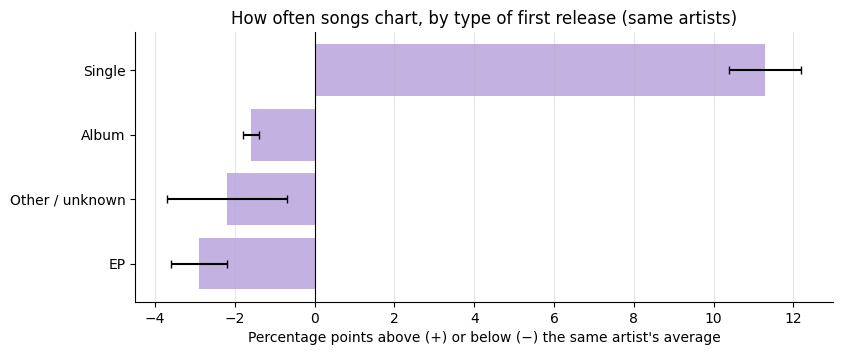

,non-charting songs (%),charting songs (%)
release_type,,
Album,82.0,62.7
EP,5.8,2.8
Other / unknown,2.2,0.3
Single,10.0,34.1


In [ ]:
def within_artist(df, column):
    """For each category: how much more (or less) often an artist's songs in this category charted than
    that same artist's songs overall. Only artists with enough songs and at least two categories count;
    each artist has equal weight."""
    d = df.dropna(subset=[column])
    d = d[d.groupby("artist_mbid")["charted"].transform("size") >= MIN_ARTIST_SONGS]
    d = d[d.groupby("artist_mbid")[column].transform("nunique") >= 2]
    artist_rate = d.groupby("artist_mbid")["charted"].mean()
    cells = d.groupby(["artist_mbid", column], observed=True)["charted"].agg(songs="size", rate="mean").reset_index()
    cells["difference"] = cells["rate"] - cells["artist_mbid"].map(artist_rate)
    summary = cells.groupby(column, observed=True).agg(
        artists=("rate", "size"), songs=("songs", "sum"),
        artist_weighted_pct=("rate", "mean"), difference_pts=("difference", "mean"),
        sd=("difference", "std"), share_above=("difference", lambda x: (x > 0).mean()))
    margin = 1.96 * summary["sd"] / np.sqrt(summary["artists"])        # approximate 95% range of the mean
    summary["artist_weighted_pct"] = (summary["artist_weighted_pct"] * 100).round(1)
    summary["difference_pts"] = (summary["difference_pts"] * 100).round(1)
    summary["range_pts"] = (margin * 100).round(1)
    summary["approx_95pct_range"] = [f"{d - m:+.1f} to {d + m:+.1f}"
                                     for d, m in zip(summary["difference_pts"], summary["range_pts"])]
    summary["% of artists above own average"] = (summary["share_above"] * 100).round(0)
    return summary.drop(columns=["sd", "share_above"]).sort_values("difference_pts", ascending=False)

def plot_within_artist(summary, title, name):
    """Horizontal bars: difference from the artist's own average, with the approximate 95% range."""
    s = summary.sort_values("difference_pts")
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(s) + 1.5))
    ax.barh([str(i) for i in s.index], s["difference_pts"], xerr=s["range_pts"], color=COLOR_MAIN, ecolor="black", capsize=3)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Percentage points above (+) or below (−) the same artist's average")
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    save_figure(fig, name)
    plt.show()

by_type_within = within_artist(songs_2000_2023, "release_type")
COMPARISON_RESULTS["release_type_within_artist"] = by_type_within.reset_index().to_dict("records")
display(by_type_within)
plot_within_artist(by_type_within, "How often songs chart, by type of first release (same artists)", "11_3_release_type_within_artist")

type_share = (pd.crosstab(songs_2000_2023["release_type"], songs_2000_2023["charted"], normalize="columns") * 100).round(1)
type_share.columns = ["non-charting songs (%)", "charting songs (%)"]
type_share

**Observations:** songs first released as singles charted far more often than the same artists' other songs: on average 17.5% of an artist's singles reached the Hot 100, 11.3 percentage points above the artist's own average (approximate range +10.4 to +12.2), and this held for 60% of artists. Album tracks (4.5%), EP tracks (3.1%) and other releases (3.3%) charted less often than the artist's average. Singles make up 34% of charting songs but only 10% of non-charting songs.

**Interpretation:** release as a single is the strongest difference we found between charting and non-charting songs of the same artist. It should not be read as "releasing a song as a single makes it chart": artists and labels choose as singles the songs they expect to succeed, and then promote them (radio, playlists, videos). The difference therefore measures the combination of this selection and of promotion, which our data cannot separate. It is consistent with 9.6, where singles and album tracks also differed in how quickly they entered.

### 11.4 Which genres chart more often than the same artist's other songs?

An artist-level genre is the same for all of an artist's songs, so it cannot distinguish songs of the same artist (10.4). This comparison therefore uses only songs **with a genre of their own** (from the recording or from the artist's own release), in both groups. Only families with at least 30 artists are shown.

Songs with a genre of their own: 103,171 of 178,338 (charting 8.2% of them)


,artists,songs,artist_weighted_pct,difference_pts,range_pts,approx_95pct_range,% of artists above own average
genre_family,,,,,,,
Pop,812,16122,21.2,12.1,1.9,+10.2 to +14.0,55.0
R&B / soul,409,8554,13.8,4.1,2.3,+1.8 to +6.4,37.0
Rock / alternative,494,15623,10.8,3.7,2.0,+1.7 to +5.7,40.0
Country,172,7293,14.2,2.0,2.5,-0.5 to +4.5,44.0
Electronic / dance,478,6746,9.9,1.6,2.0,-0.4 to +3.6,21.0
Hip hop / rap,470,18345,10.9,0.8,1.6,-0.8 to +2.4,34.0
Other,479,5984,8.9,0.7,2.1,-1.4 to +2.8,18.0
Latin,82,2723,6.0,-2.3,3.1,-5.4 to +0.8,38.0
Holiday,207,917,4.0,-5.0,2.2,-7.2 to -2.8,8.0


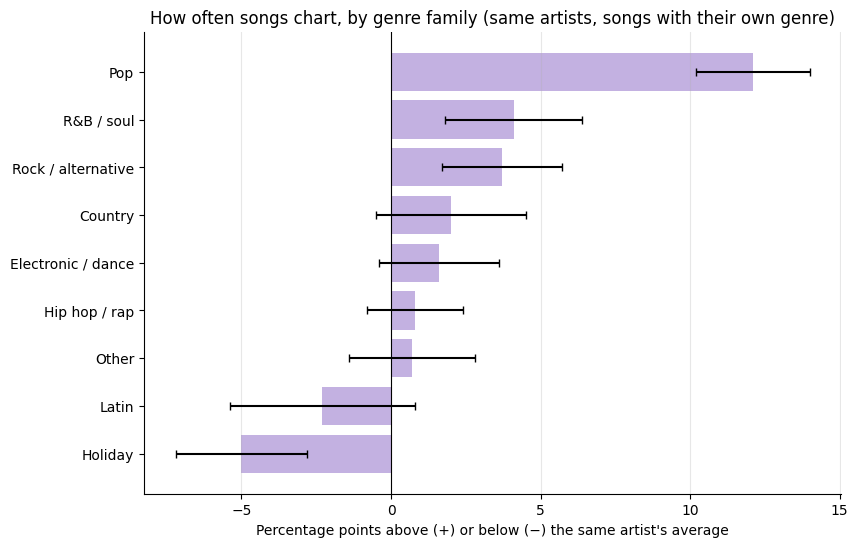

In [ ]:
own_genre = songs_2000_2023[songs_2000_2023["genre_level"].isin(["recording", "release group"])]
print(f"Songs with a genre of their own: {len(own_genre):,} of {len(songs_2000_2023):,} "
      f"(charting {own_genre['charted'].mean() * 100:.1f}% of them)")
by_genre_within = within_artist(own_genre, "genre_family")
by_genre_within = by_genre_within[by_genre_within["artists"] >= 30]
COMPARISON_RESULTS["genre_within_artist"] = by_genre_within.reset_index().to_dict("records")
display(by_genre_within)
plot_within_artist(by_genre_within, "How often songs chart, by genre family (same artists, songs with their own genre)",
                   "11_4_genre_within_artist")

**Observations:** among songs with a genre of their own, an artist's songs tagged as pop charted 12.1 percentage points more often than that artist's average (approximate range +10.2 to +14.0; 812 artists), and R&B/soul (+4.1) and rock/alternative (+3.7) songs also charted more often. For country, electronic/dance, hip hop, Latin and "other", the range includes 0, so no clear difference. Holiday songs charted 5.0 points less often than the artist's average.

**Interpretation:** when the same artist releases songs in different genres, the ones tagged pop are clearly the most likely to chart. Two cautions apply. First, tags are added by volunteers after release, and a song that became a hit may be tagged "pop" partly *because* it was popular, which would inflate this difference. Second, this compares songs *within* artists: it does not say that pop artists chart more often than hip hop artists (hip hop is the largest family among charting songs, 9.5). Holiday songs (mostly tracks on Christmas albums) rarely chart, apart from a few classics.

### 11.5 Revisiting the threshold: the chance that a song will still chart

In 9.4 we could only study songs that did chart. With the comparison group we can now test our hypothesis as stated: **beyond a certain time after release, is a song much less likely to *ever* enter the chart?** For each chart *k* after release, we take all songs that had not charted before chart *k* (charting and non-charting) and ask what share of them still charted later. We use songs with an exact release date that can be followed for five years (released 2000–2020), measured in charts waited as in Section 9, with songs whose release date is impossible (M2) excluded, as in Section 9.

Songs with an exact release date and 5 years of charts after it: 130,317 (6,814 charted), released 2000–2020


,chart,songs not yet charted,% that still charted later,% artist-weighted
0,1,130317,5.23,5.63
1,2,127726,3.31,3.96
2,3,126919,2.69,3.41
4,5,126630,2.47,3.15
12,13,125769,1.80,2.35
25,26,124895,1.11,1.54
51,52,124063,0.45,0.68


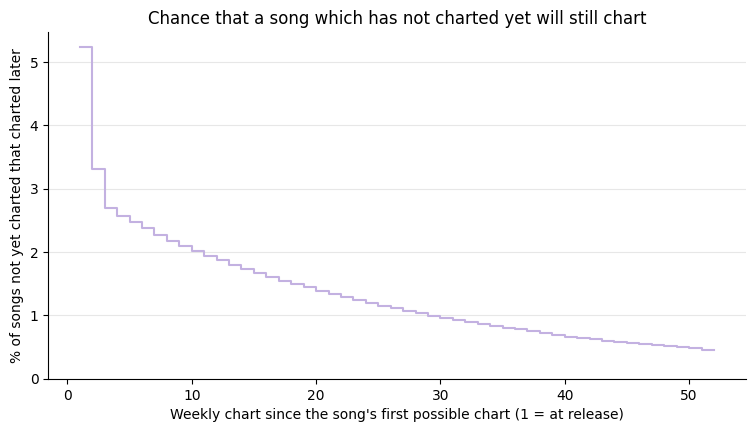

In [ ]:
dated_songs = songs_2000_2023[(songs_2000_2023["release_precision"] == "day") & songs_2000_2023["release_date"].notna()
                              & ~songs_2000_2023["flag_release_after_chart"]].copy()
dated_songs["first_possible_pos"] = np.searchsorted(tracking_end.values, dated_songs["release_date"].values, side="left")
entry = read_table("SELECT song_id AS song_key, first_chart_date FROM song_summary")
dated_songs = dated_songs.merge(entry, on="song_key", how="left", validate="one_to_one")
dated_songs["waited"] = (dated_songs["first_chart_date"].map(chart_position) - dated_songs["first_possible_pos"])
followed = dated_songs[(dated_songs["first_possible_pos"] + LONG_FOLLOW_UP - 1 <= last_pos)
                       & (dated_songs["waited"].isna() | (dated_songs["waited"] < LONG_FOLLOW_UP))].copy()
followed["waited"] = followed["waited"].clip(lower=0)          # NaN = never charted
print(f"Songs with an exact release date and 5 years of charts after it: {len(followed):,} "
      f"({int(followed['charted'].sum()):,} charted), released "
      f"{followed['release_year'].min()}–{followed['release_year'].max()}")

def still_possible(waited, charts):
    """For each chart k: of the songs that had not charted before chart k, the share that ever charted later."""
    rows = []
    for k in range(charts):
        not_yet = waited.isna() | (waited >= k)
        rows.append({"chart": k + 1, "songs not yet charted": int(not_yet.sum()),
                     "% that still charted later": round(waited[not_yet].notna().mean() * 100, 2)})
    return pd.DataFrame(rows)

later = still_possible(followed["waited"], FOLLOW_UP_CHARTS)
by_artist = []
for k in [0, 1, 2, 4, 12, 25, 51]:
    nyt = followed[followed["waited"].isna() | (followed["waited"] >= k)]
    rates = nyt.groupby("artist_mbid")["waited"].agg(n="size", rate=lambda w: w.notna().mean())
    by_artist.append(round(rates.loc[rates["n"] >= MIN_ARTIST_SONGS, "rate"].mean() * 100, 2))
key_rows = later.iloc[[0, 1, 2, 4, 12, 25, 51]].assign(**{"% artist-weighted": by_artist})
COMPARISON_RESULTS["chance_to_still_chart"] = later.to_dict("records")
COMPARISON_RESULTS["chance_to_still_chart_key_points"] = key_rows.to_dict("records")
display(key_rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.step(later["chart"], later["% that still charted later"], where="post", color=COLOR_MAIN)
ax.set_ylim(bottom=0)
style_axes(ax, "Chance that a song which has not charted yet will still chart",
           "Weekly chart since the song's first possible chart (1 = at release)",
           "% of songs not yet charted that charted later")
save_figure(fig, "11_5_chance_to_still_chart")
plt.show()

**Observations:** at release, 5.2% of these songs went on to chart. Of the songs that missed their first possible chart, 3.3% still charted later; of those that missed their first two, 2.7%; after about a quarter of a year without entering (12 charts), 1.8%; after half a year, 1.1%; after a year, 0.45%. The artist-weighted figures are slightly higher but follow the same pattern (5.6% at release, 0.7% after a year).

**Interpretation:** this confirms our hypothesis with songs that did not chart included: the chance that a song ever reaches the Hot 100 halves once it has missed its first two possible charts, and after a year without charting it is about eleven times lower than at release. Together with 9.4, the first two charts after release are decisive; after them, the chance keeps shrinking steadily rather than dropping to zero at a fixed point, so the "threshold" is a sharp early drop followed by a slow decline.

**Limitations:** only songs with an exact release date are included, which is more often the case for charting songs (93%) than for non-charting songs (86%, 10.4); the shares are therefore slightly too high, although the shape of the curve should not change much. Songs released before 2000 and after 2020 are not included.

### 11.6 Save the comparison results and figures

In [ ]:
COMPARISON_FILE = OUTPUT_DIR / "analysis_results_comparison.json"
COMPARISON_FILE.write_text(json.dumps(without_nan({
    "record_type": "analysis results – charting vs non-charting songs of the same artists (aggregates only)",
    "source_commit": SOURCE_COMMIT,
    "musicbrainz_export_sha256": mb_sha256,
    "comparison_export_commit": CMP_COMMIT,
    "computed_at_utc": datetime.now(timezone.utc).replace(microsecond=0).isoformat(),
    "last_release_year": LAST_RELEASE_YEAR,
    "min_songs_per_artist": MIN_ARTIST_SONGS,
    "results": COMPARISON_RESULTS,
}), indent=2, ensure_ascii=False, allow_nan=False, default=str), encoding="utf-8")

ALL_FIG_ZIP = shutil.make_archive(str(OUTPUT_DIR / "figures_all"), "zip", FIG_DIR)
download_file(COMPARISON_FILE)
download_file(ALL_FIG_ZIP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 11.7 Summary of Section 11

**Observations:**
1. Of 178,338 songs released 2000–2023 by 2,029 artists who have charted, 5.5% reached the Hot 100; the median artist charted with 3.5% of their songs (11.1). This share changed little over time (11.2).
2. Songs first released as singles charted 11 percentage points more often than the same artist's average; album and EP tracks less often (11.3).
3. Among songs with their own genre, those tagged pop charted 12 points more often than the same artist's average, R&B and rock slightly more often, holiday songs less often (11.4).
4. A song's chance of ever charting halves within its first two possible charts and is about eleven times lower after a year without charting (11.5).

**Interpretation:** for songs by artists who can reach the chart, what most distinguishes the songs that do is how they are released and promoted (as singles), the genre they are perceived as (pop), and timing: a song that has not charted within its first couple of weeks is unlikely ever to do so. These are associations: singles are chosen because they are expected to succeed, genre tags may partly follow success, and every artist compared has already charted, so the effect of being a known artist cannot be tested.

## 12. Generated documentation: README and file inventory

This last section documents the run itself. From the notebook's own settings and results it produces two files:
- **`file_inventory.csv`**: every file the notebook wrote to `outputs/`, with its size, its SHA-256 fingerprint, whether it was downloaded, and whether it contains song-level chart data.
- **`README.md`**: a short description of the project for someone who receives our files without the notebook: the question, the sources with their fixed versions and fingerprints, how to reproduce the work, the main results and limitations, the files produced and the software versions.

**Why generated rather than written by hand** (decision log, row 23). A hand-written README has to be updated every time a result changes, and its numbers can silently go out of date. Here every number, version and fingerprint is read from the run that produced the results. The README repeats the main interpretations of Sections 9–11 only briefly; the full reasoning stays in this notebook.

### 12.1 File inventory

Every file in `outputs/` is listed. Whether a file was downloaded is recorded by `download_file` itself (2.3), so the table shows what actually happened in this run, not what we intended. A file counts as containing **song-level chart data** if it holds Billboard chart rows or song lists derived from them; these are the files that Section 1.8 keeps private. The README and the inventory itself are not listed, because they are written in this section (and a file cannot contain its own fingerprint).

In [ ]:
# Files that contain song-level chart data, or full extracts that include it: never to be published (Section 1.8).
CHART_DATA_PREFIXES = ("raw/hot-100", "clean/", "storage_comparison/")   # raw Billboard file, cleaned tables, storage tests
CHART_DATA_FILES    = {"billboard_hot100.sqlite", "billboard_song_names.csv"}
GENERATED_HERE      = {"README.md", "file_inventory.csv"}     # written in this section, so not listed

def sha256_of(path):
    """SHA-256 fingerprint of a file, read in 1 MB blocks so that large files do not fill the memory."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

downloaded = {Path(p).resolve() for p in DOWNLOADED}
rows = []
for path in sorted(p for p in OUTPUT_DIR.rglob("*") if p.is_file()):
    rel = path.relative_to(OUTPUT_DIR).as_posix()
    if rel in GENERATED_HERE:
        continue
    if path.resolve() in downloaded:
        sent = "yes"
    elif rel.startswith("figures/"):
        sent = "yes, inside figures_all.zip"
    else:
        sent = "no, kept in Colab only"
    rows.append({"file": rel,
                 "size (KB)": round(path.stat().st_size / 1000, 1),
                 "downloaded": sent,
                 "song-level chart data": "yes" if rel.startswith(CHART_DATA_PREFIXES) or rel in CHART_DATA_FILES else "no",
                 "sha256": sha256_of(path)})
inventory = pd.DataFrame(rows)

private_sent = inventory.loc[(inventory["song-level chart data"] == "yes") & (inventory["downloaded"] == "yes"), "file"]
print(f"Files in {OUTPUT_DIR}/: {len(inventory)}, of which downloaded: {(~inventory['downloaded'].str.startswith('no')).sum()}, "
      f"with song-level chart data: {(inventory['song-level chart data'] == 'yes').sum()}")
print("Files with chart data that were downloaded:", ", ".join(private_sent) or "none")

INVENTORY_FILE = OUTPUT_DIR / "file_inventory.csv"
inventory.to_csv(INVENTORY_FILE, index=False)
download_file(INVENTORY_FILE)
inventory.drop(columns="sha256")

Files in outputs/: 43, of which downloaded: 27, with song-level chart data: 14
Files with chart data that were downloaded: billboard_song_names.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,file,size (KB),downloaded,song-level chart data
0,analysis_results_comparison.json,13.5,yes,no
1,analysis_results_time_to_chart.json,28.6,yes,no
2,billboard_hot100.sqlite,83394.6,"no, kept in Colab only",yes
3,billboard_song_names.csv,526.6,yes,yes
4,clean/hot100_songs.csv,1008.1,"no, kept in Colab only",yes
5,clean/hot100_weekly_clean.csv,17364.6,"no, kept in Colab only",yes
6,cleaning_log_billboard.json,5.7,yes,no
7,cleaning_log_musicbrainz.json,3.6,yes,no
8,descriptive_results_billboard.json,9.3,yes,no
9,figures/11_3_release_type_within_artist.png,53.7,"yes, inside figures_all.zip",no


**Observations:** the only downloaded file that contains chart data is `billboard_song_names.csv`, the list of song names needed for the PostgreSQL step (8.1), which stays within the group. The database, the raw Billboard file, the cleaned tables and the storage-test files remain in Colab only.

**Interpretation:** the separation set out in Section 1.8 holds in practice: what leaves Colab is documentation, aggregates and figures. The fingerprints let anyone check that a file they hold is the one produced by this run. The JSON records contain the time they were made, and the zip files the time each figure was saved, so their fingerprints change with every run; the other files are rebuilt from the same pinned inputs and should be identical from one run to the next.

### to fix: 12.2 README

need to add grp repo

The README is built in two steps: the first cell collects the numbers and tables from this run, the second writes the text, saves it as `README.md`, downloads it, and displays it below as it will appear. It contains aggregates only.

The Billboard fingerprint is taken from `EXPECTED_SHA256`: Section 3.2 stops the notebook unless the downloaded file matches it exactly, so it is the fingerprint of the file we used.

In [ ]:
from IPython.display import Markdown

EXTRACT_REPO_URL = f"https://github.com/{MB_REPO}"
GENERATED_AT = datetime.now(timezone.utc).replace(microsecond=0)

def pct(x, digits=1):
    """A number as a percentage text, e.g. 5.5 -> '5.5%'."""
    return f"{x:.{digits}f}%"

def md_table(df):
    """A DataFrame as a Markdown table (no extra library needed)."""
    header = "| " + " | ".join(map(str, df.columns)) + " |"
    rule = "|" + "---|" * len(df.columns)
    body = ["| " + " | ".join(map(str, row)) + " |" for row in df.itertuples(index=False)]
    return "\n".join([header, rule, *body])

# Numbers quoted in the README, taken from this run's results (nothing typed by hand).
n_songs, n_charts = int(q("SELECT COUNT(*) AS n FROM songs")["n"][0]), int(q("SELECT COUNT(*) AS n FROM charts")["n"][0])
entered_by = ANALYSIS_RESULTS["cumulative_share_by_chart_5y"]
compared = cmp_ledger.iloc[-1]
top_type, top_genre = by_type_within.iloc[0], by_genre_within.iloc[0]
still = key_rows.set_index("chart")["% that still charted later"]

sources = pd.DataFrame([
    ["Billboard Hot 100 weekly charts", f"[{SOURCE_REPO}]({REPO_URL}), commit `{SOURCE_COMMIT[:7]}`, file `{SOURCE_PATH}`",
     f"`{EXPECTED_SHA256}`", "rights claimed by PMC, publisher of Billboard (notebook Section 1)"],
    ["MusicBrainz full export", f"`{MB_DUMP}`, MetaBrainz Foundation", "checked against the published checksums (8.2)",
     "core data CC0; genres (tags) CC BY-NC-SA 3.0"],
    ["MusicBrainz data of charting songs (Job A)", f"[{MB_REPO}]({EXTRACT_REPO_URL}), commit `{MB_COMMIT[:7]}`, file `{MB_PATH}`",
     f"`{MB_EXPECTED_SHA256}`", "CC BY-NC-SA 3.0 (contains genres)"],
    *[[f"Comparison group (Job B): `{name}`", f"[{MB_REPO}]({EXTRACT_REPO_URL}), commit `{CMP_COMMIT[:7]}`",
       f"`{sha}`", "CC BY-NC-SA 3.0 (contains genres)"] for name, sha in CMP_FILES.items()],
], columns=["Data", "Where from (fixed version)", "SHA-256", "Rights / licence"])

files = inventory[~inventory["file"].str.startswith(("figures/", "storage_comparison/"))].drop(columns="sha256")
versions = pd.DataFrame([["Python", sys.version.split()[0]], ["pandas", pd.__version__], ["numpy", np.__version__],
                         ["matplotlib", matplotlib.__version__], ["requests", requests.__version__],
                         ["SQLite", sqlite3.sqlite_version], ["Platform", platform.platform()]],
                        columns=["Software", "Version"])

In [ ]:
README = f"""# What determines whether a song reaches the Billboard Hot 100? (Group C)

*Generated automatically by `{NOTEBOOK_NAME}` on {GENERATED_AT:%Y-%m-%d %H:%M} UTC. Do not edit by hand: change the notebook and run it again.*

## Research question
What determines whether a song reaches the Billboard Hot 100? A song counts as successful if it appears on the chart at least once.
We study the weekly charts dated {STUDY_START} to {STUDY_END} ({n_charts:,} charts, {n_songs:,} songs) and compare the songs that charted
with songs by the same lead artists, released in the same years, that never charted.

## Data sources
Every source is downloaded from a fixed version and checked with its SHA-256 fingerprint before use; the notebook stops if a file differs.

{md_table(sources)}

## Where the work is kept
- **The notebook** (`{NOTEBOOK_NAME}`) contains the whole workflow, from collection to analysis, with every decision and its justification (decision log at the top).
- **[{MB_REPO}]({EXTRACT_REPO_URL})** contains the SQL scripts that extract MusicBrainz data in a local PostgreSQL database, the extracts and their run logs.
  It is separate because this step cannot run in Colab (the MusicBrainz tables are about 25 GB), its results must be downloadable at a fixed version,
  and the extracts carry MusicBrainz's licence (notebook 8.3, decision log row 20).

## How to reproduce
1. Open the notebook in Google Colab and click **Runtime → Run all** (to start from scratch, first **Runtime → Disconnect and delete runtime**).
2. Nothing needs to be uploaded and no login is needed. Allow multiple downloads if the browser asks.
3. The MusicBrainz step (Jobs A and B) does **not** need to be repeated: its results are downloaded from the extract repository at fixed commits.
   To repeat it, follow "Reproducing" in that repository (PostgreSQL, the MusicBrainz export `{MB_DUMP}`,
   and the list `billboard_song_names.csv` produced by the notebook in Section 8.1).

## Main results
1. **Timing.** Of the charting songs followed for five years, {pct(entered_by[1] * 100, 0)} entered on their first possible chart
   and {pct(entered_by[4] * 100, 0)} within four charts (Section 9.2).
2. **Most songs never chart.** Of {int(compared['charting songs']) + int(compared['non-charting songs']):,} songs released
   2000–{LAST_RELEASE_YEAR} by {int(compared['artists']):,} artists who have charted, {pct(overall['% of songs that charted (all songs pooled)'])} reached
   the Hot 100; the median artist charted with {pct(overall['% charted, median artist'])} of their songs (Section 11.1).
3. **Release type.** Songs first released as a {top_type.name.lower()} charted {top_type['difference_pts']:.1f} percentage points more often
   than the same artist's average (approximate 95% range: {top_type['approx_95pct_range']}; Section 11.3).
4. **Genre.** Among songs with a genre of their own, {top_genre.name} songs charted {top_genre['difference_pts']:.1f} points more often
   than the same artist's average (approximate 95% range: {top_genre['approx_95pct_range']}; Section 11.4).
5. **A sharp early drop.** At release, {pct(still[1], 1)} of songs went on to chart; after missing their first two possible charts,
   {pct(still[3], 1)}; after a year without charting, {pct(still[52], 2)} (Section 11.5).

These are associations, not causes: singles are chosen because they are expected to succeed, genre tags may partly follow success,
and every artist compared has already charted.

## Main limitations
- MusicBrainz documents some songs and periods more completely than others, so overall levels are less reliable than comparisons within artists.
- The comparison group contains only artists who have charted, so the effect of being a known artist cannot be tested.
- Release dates are more often exact for charting songs than for non-charting songs (10.4).

## Files produced by the notebook
All files are written to the `outputs/` folder in Colab, which is deleted when the runtime ends. Files with song-level chart data are kept in Colab only
(apart from `billboard_song_names.csv`, needed for the PostgreSQL step and kept private). Fingerprints of every file: `file_inventory.csv`.
Figures are in `figures_all.zip`; individual figures and the storage-test files of Section 6.7 are listed only in `file_inventory.csv`.

{md_table(files)}

## Software used in this run
{md_table(versions)}
"""

README_FILE = OUTPUT_DIR / "README.md"
README_FILE.write_text(README, encoding="utf-8")
download_file(README_FILE)
display(Markdown(README))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# What determines whether a song reaches the Billboard Hot 100? (Group C)

*Generated automatically by `Data Project_Billboard_Group C.ipynb` on 2026-10-26 00:16 UTC. Do not edit by hand: change the notebook and run it again.*

## Research question
What determines whether a song reaches the Billboard Hot 100? A song counts as successful if it appears on the chart at least once.
We study the weekly charts dated 2000-01-01 to 2025-12-27 (1,357 charts, 11,728 songs) and compare the songs that charted
with songs by the same lead artists, released in the same years, that never charted.

## Data sources
Every source is downloaded from a fixed version and checked with its SHA-256 fingerprint before use; the notebook stops if a file differs.

| Data | Where from (fixed version) | SHA-256 | Rights / licence |
|---|---|---|---|
| Billboard Hot 100 weekly charts | [utdata/rwd-billboard-data](https://github.com/utdata/rwd-billboard-data), commit `f5801b0`, file `data-out/hot-100-current.csv` | `3f2a274dd7cb26217c3bce8fb2e761ed3e131c5da6c00744a39c070e8b47dc20` | rights claimed by PMC, publisher of Billboard (notebook Section 1) |
| MusicBrainz full export | `20261017-002244`, MetaBrainz Foundation | checked against the published checksums (8.2) | core data CC0; genres (tags) CC BY-NC-SA 3.0 |
| MusicBrainz data of charting songs (Job A) | [Isabelle333/billboard-musicbrainz-extract](https://github.com/Isabelle333/billboard-musicbrainz-extract), commit `c95bcb0`, file `musicbrainz_for_billboard_songs.csv` | `a7dcab5ba6888d7a0f11da8d6b20f81fde6540f897400a9c09b3db85c3cfb3af` | CC BY-NC-SA 3.0 (contains genres) |
| Comparison group (Job B): `comparison_songs_musicbrainz.csv.gz` | [Isabelle333/billboard-musicbrainz-extract](https://github.com/Isabelle333/billboard-musicbrainz-extract), commit `6d45e7b` | `fa4fb810e4533bd452a0c0aa8d3ec56a2aa863da50beadd1de16dfefdde7bc4d` | CC BY-NC-SA 3.0 (contains genres) |
| Comparison group (Job B): `billboard_song_lead_artist.csv` | [Isabelle333/billboard-musicbrainz-extract](https://github.com/Isabelle333/billboard-musicbrainz-extract), commit `6d45e7b` | `603571bea2d887dd460556b5f39dd40864934b4728b03084291387e847ef4206` | CC BY-NC-SA 3.0 (contains genres) |

## Where the work is kept
- **The notebook** (`Data Project_Billboard_Group C.ipynb`) contains the whole workflow, from collection to analysis, with every decision and its justification (decision log at the top).
- **[Isabelle333/billboard-musicbrainz-extract](https://github.com/Isabelle333/billboard-musicbrainz-extract)** contains the SQL scripts that extract MusicBrainz data in a local PostgreSQL database, the extracts and their run logs.
  It is separate because this step cannot run in Colab (the MusicBrainz tables are about 25 GB), its results must be downloadable at a fixed version,
  and the extracts carry MusicBrainz's licence (notebook 8.3, decision log row 20).

## How to reproduce
1. Open the notebook in Google Colab and click **Runtime → Run all** (to start from scratch, first **Runtime → Disconnect and delete runtime**).
2. Nothing needs to be uploaded and no login is needed. Allow multiple downloads if the browser asks.
3. The MusicBrainz step (Jobs A and B) does **not** need to be repeated: its results are downloaded from the extract repository at fixed commits.
   To repeat it, follow "Reproducing" in that repository (PostgreSQL, the MusicBrainz export `20261017-002244`,
   and the list `billboard_song_names.csv` produced by the notebook in Section 8.1).

## Main results
1. **Timing.** Of the charting songs followed for five years, 38% entered on their first possible chart
   and 54% within four charts (Section 9.2).
2. **Most songs never chart.** Of 178,338 songs released
   2000–2023 by 2,029 artists who have charted, 5.5% reached
   the Hot 100; the median artist charted with 3.5% of their songs (Section 11.1).
3. **Release type.** Songs first released as a single charted 11.3 percentage points more often
   than the same artist's average (approximate 95% range: +10.4 to +12.2; Section 11.3).
4. **Genre.** Among songs with a genre of their own, Pop songs charted 12.1 points more often
   than the same artist's average (approximate 95% range: +10.2 to +14.0; Section 11.4).
5. **A sharp early drop.** At release, 5.2% of songs went on to chart; after missing their first two possible charts,
   2.7%; after a year without charting, 0.45% (Section 11.5).

These are associations, not causes: singles are chosen because they are expected to succeed, genre tags may partly follow success,
and every artist compared has already charted.

## Main limitations
- MusicBrainz documents some songs and periods more completely than others, so overall levels are less reliable than comparisons within artists.
- The comparison group contains only artists who have charted, so the effect of being a known artist cannot be tested.
- Release dates are more often exact for charting songs than for non-charting songs (10.4).

## Files produced by the notebook
All files are written to the `outputs/` folder in Colab, which is deleted when the runtime ends. Files with song-level chart data are kept in Colab only
(apart from `billboard_song_names.csv`, needed for the PostgreSQL step and kept private). Fingerprints of every file: `file_inventory.csv`.
Figures are in `figures_all.zip`; individual figures and the storage-test files of Section 6.7 are listed only in `file_inventory.csv`.

| file | size (KB) | downloaded | song-level chart data |
|---|---|---|---|
| analysis_results_comparison.json | 13.5 | yes | no |
| analysis_results_time_to_chart.json | 28.6 | yes | no |
| billboard_hot100.sqlite | 83394.6 | no, kept in Colab only | yes |
| billboard_song_names.csv | 526.6 | yes | yes |
| clean/hot100_songs.csv | 1008.1 | no, kept in Colab only | yes |
| clean/hot100_weekly_clean.csv | 17364.6 | no, kept in Colab only | yes |
| cleaning_log_billboard.json | 5.7 | yes | no |
| cleaning_log_musicbrainz.json | 3.6 | yes | no |
| descriptive_results_billboard.json | 9.3 | yes | no |
| figures_all.zip | 888.4 | yes | no |
| figures_billboard.zip | 263.8 | yes | no |
| genre_family_mapping.csv | 5.6 | yes | no |
| provenance_billboard.json | 2.4 | yes | no |
| provenance_quality_comparison.json | 12.5 | yes | no |
| provenance_quality_musicbrainz.json | 3.4 | yes | no |
| quality_assessment_billboard.json | 3.7 | yes | no |
| raw/billboard_song_lead_artist.csv | 622.0 | no, kept in Colab only | no |
| raw/comparison_songs_musicbrainz.csv.gz | 12365.5 | no, kept in Colab only | no |
| raw/hot-100-current_f5801b0.csv | 20699.1 | no, kept in Colab only | yes |
| raw/musicbrainz_for_billboard_songs.csv | 2364.1 | no, kept in Colab only | no |
| schema_billboard.sql | 2.3 | yes | no |
| storage_billboard.json | 2.4 | yes | no |

## Software used in this run
| Software | Version |
|---|---|
| Python | 3.13.16 |
| pandas | 2.2.3 |
| numpy | 2.1.3 |
| matplotlib | 3.10.0 |
| requests | 2.32.4 |
| SQLite | 3.45.1 |
| Platform | Linux-6.6.122+-x86_64-with-glibc2.39 |


### 12.3 Final checks

Before finishing, we check that:
- every JSON record can be read by any program. Python writes missing numbers as `NaN`, which is not valid JSON; 9.8 and 11.6 already prevent this, and here we check all records;
- the database is intact and all its relationships (foreign keys) hold;
- the README contains no missing values;
- no file with chart data was downloaded, apart from `billboard_song_names.csv`.

The notebook stops if a check fails. Finally the database connection is closed, so the database file is complete. After this, run any cell again only with **Runtime → Run all**.

In [ ]:
import re   # standard library: text patterns

def no_nan(token):
    """Called by json.loads for NaN or Infinity, which are not valid JSON."""
    raise ValueError(f"{token} is not valid JSON")

checks = {}
for path in sorted(OUTPUT_DIR.glob("*.json")):
    try:
        json.loads(path.read_text(encoding="utf-8"), parse_constant=no_nan)
        checks[f"{path.name} is valid JSON"] = "passed"
    except ValueError as error:
        checks[f"{path.name} is valid JSON"] = f"FAILED: {error}"

checks["database integrity (PRAGMA integrity_check)"] = "passed" if q("PRAGMA integrity_check").iloc[0, 0] == "ok" else "FAILED"
checks["no foreign-key violations"] = "passed" if q("PRAGMA foreign_key_check").empty else "FAILED"
checks["README has no missing values"] = "passed" if not re.search(r"\b(nan|None|NaN)\b|<NA>", README) else "FAILED"
checks["no chart-data file downloaded except billboard_song_names.csv"] = (
    "passed" if set(private_sent) <= {"billboard_song_names.csv"} else "check: " + ", ".join(private_sent))

final_checks = pd.Series(checks, name="result").to_frame()
display(final_checks)
if final_checks["result"].str.startswith("FAILED").any():
    raise ValueError("A final check failed – see the table above.")

con.commit()
con.close()
print("Database connection closed. To run any cell again, use Runtime → Run all.")

,result
analysis_results_comparison.json is valid JSON,passed
analysis_results_time_to_chart.json is valid JSON,passed
cleaning_log_billboard.json is valid JSON,passed
cleaning_log_musicbrainz.json is valid JSON,passed
descriptive_results_billboard.json is valid JSON,passed
provenance_billboard.json is valid JSON,passed
provenance_quality_comparison.json is valid JSON,passed
provenance_quality_musicbrainz.json is valid JSON,passed
quality_assessment_billboard.json is valid JSON,passed
storage_billboard.json is valid JSON,passed


Database connection closed. To run any cell again, use Runtime → Run all.


### 12.4 Summary of Section 12

The notebook ends by documenting its own run: an inventory of every file it produced, with fingerprints and whether each one left Colab, and a README generated from the same results, so the documentation always matches the analysis. The final checks confirm that every record is valid, that the database is intact, and that chart data stayed in Colab as set out in Section 1.8.